## *Fine-Grained Error-Type Features for Half-Life Regression*
### ACL 2016 — Burr Settles & Brendan Meeder — Duolingo Inc.

---

| Field | Details |
|:------|:--------|
| **Submitted by** | Kaushal Kushwaha |
| **Roll Number** | M25DE2077 |
| **Email** | M25DE2077@iitj.ac.in |
| **Supervisor** | Sidharth Ranjan, Assistant Professor, Artificial Intelligence and Data Science |
| **Supervisor Email** | sranjan@iitj.ac.in |
| **Institution** | Indian Institute of Technology Jodhpur |
| **Course** | M.Tech Project (AID7720) |
| **Original Paper** | Settles, B. & Meeder, B. (2016). *A Trainable Spaced Repetition Model for Language Learning*. In *Proceedings of ACL 2016*, pp. 1848-1858. Berlin, Germany. |
| **Official Code** | https://github.com/duolingo/halflife-regression |
| **Dataset** | Duolingo SLAM — 13.2 million real language-learning sessions |

---

**Baseline model:** Half-Life Regression (HLR), Settles, B. & Meeder, B. (2016). *A Trainable Spaced
Repetition Model for Language Learning.* ACL 2016, pp. 1848–1858.

**Extension studied here (this project's contribution):** augmenting HLR's feature set with a family
of *fine-grained error-type features* — signals derived from the temporal and structural pattern of a
learner's mistakes (streaks, recency, density, transition structure, lexical difficulty) rather than
only raw exposure counts (`x_n, x_pos, x_neg`) and sparse lexeme identity indicators.

---

**Abstract.** Half-life regression (HLR) models the probability that a learner recalls a lexeme as an
exponentially decaying function of elapsed time, parameterized by a log-linear "half-life" estimator
fit to interaction counts and lexeme identity. The original paper found that *lexeme identity* features
gave limited benefit and, in production, caused overfitting/cold-start problems, while the *interaction
count* features and the half-life-aware loss term were the primary drivers of accuracy. This notebook
tests whether replacing (or augmenting) sparse lexeme-identity features with a small set of dense,
theoretically motivated *error-type* features — describing *how* a learner has been failing a lexeme,
not just *how often* — improves half-life prediction quality without the overfitting/cold-start cost of
sparse per-lexeme weights.

**Research question.** Do fine-grained error-type features improve HLR's predictive accuracy
(MAE, AUC, half-life correlation) over the interaction-only and lexeme-augmented baselines reported
in Settles & Meeder (2016), Table 2?

---

> **How to use this notebook.** Set `DATASET_SIZE` and `DATA_DIR` in the Configuration cell, run
> top-to-bottom. All downstream cells adapt automatically to the chosen subset size. No cell needs to
> be edited elsewhere. This notebook expects the public Duolingo Spaced Repetition dataset released by
> Settles & Meeder (`settles.acl16.learning_traces.13m.csv`, or a `.csv.gz`), placed under your Google
> Drive at a path you configure below. **No synthetic or hypothetical data is used anywhere in this
> notebook** — every number downstream of the Configuration cell is computed from real rows of the
> loaded Duolingo dataset. The one exception, clearly labeled where it occurs, is a handful of small
> numeric examples used purely to illustrate how a formula behaves (e.g. "if Δ=h then p=0.5") — these
> never feed into, substitute for, or influence any experimental result.

## 0. How to Read This Notebook — The Pipeline, In Plain English

Before the formal write-up begins, here is the whole notebook in one page: what problem we're solving,
the standard research pipeline we follow to solve it, and where each step lives.

**The problem, in one sentence.** Every time a Duolingo learner reviews a word, we want to predict the
chance they'll remember it correctly — so the app knows whether to show that word again soon (if it's
about to be forgotten) or leave it alone for a while longer (if it's still fresh in memory).

**The core idea, with a physical analogy.** Doctors describe how a medicine leaves your bloodstream
using a *half-life*: "this drug's concentration halves every 6 hours." This notebook treats a memory
the same way: every word a learner knows has a *half-life* in their brain — the time it takes for their
chance of remembering it to drop to 50%. A short half-life means "fragile, needs review soon"; a long
half-life means "solid, can wait." The whole modeling problem in this notebook boils down to **one
question: can we predict that half-life accurately from a learner's real practice history?**

**Two competing recipes for predicting that half-life:**
1. **The original paper's recipe (the baseline we reproduce)** — predict the half-life mainly from *how
   many times* the learner has seen a word and *how many of those were correct*.
2. **This project's proposed recipe (the extension we test)** — additionally look at the *pattern* of
   the learner's mistakes: are errors recent or long past? Clustered in a streak or scattered? Getting
   more or less frequent? The hypothesis is that *how* someone has been failing carries information that
   a simple correct/incorrect tally throws away.

Nothing here is assumed to be true — §20/§21 test the hypothesis on real, held-out Duolingo data and
report whatever the numbers actually show.

### The standard pipeline this notebook follows, step by step

Every applied-ML research project follows roughly the same shape. Here is that shape, mapped onto this
notebook, in the order you will actually read it top to bottom:

| # | Stage  | What happens | Why it has to happen | Sections |
|---|---|---|---|---|
| 1 | **Frame the problem** | State what we're predicting, what the original paper already did, and exactly what new idea we're testing | You can't design an experiment before you know what question it answers | §1–§5 |
| 2 | **Set up the environment** | Choose how much real data to load, fix random seeds, print software versions | Makes the whole run repeatable — anyone re-running this notebook gets the same setup | §6 |
| 3 | **Load the real data** | Connect to Google Drive, find and read the real Duolingo dataset | Nothing downstream means anything unless it's computed on genuine data | §7 |
| 4 | **Check the data is trustworthy** | Count missing values, impossible probabilities, broken timestamps — *before* trusting any of it | Garbage in, garbage out — a model trained on corrupted rows produces meaningless results | §8 |
| 5 | **Clean the data** | Remove only the rows that are provably invalid (never rows that are just "unusual") | Keeps every real, valid signal while discarding rows that would break the math (e.g. dividing by zero) | §9 |
| 6 | **Explore the data (EDA)** | Plot distributions of recall rate, lag time, user/word activity | A quick visual sanity check catches data problems that summary statistics can hide, before you spend hours training on bad assumptions | §10 |
| 7 | **Build the baseline features** | Reconstruct the original paper's three simple features (times seen, times correct, times wrong) | Establishes a fair, faithful starting point — you cannot claim an "improvement" without first reproducing the thing you're improving on | §11 |
| 8 | **Split the data honestly** | Separate "past" sessions (train) from "future" sessions (test) by real timestamp, not randomly | Prevents the model from ever training on information it wouldn't actually have at prediction time | §12 |
| 9 | **Engineer the new, proposed features** | Turn each learner's raw mistake history into 12 numeric signals (streaks, recency, error rate, word difficulty, …) | This *is* the project's contribution — everything before this step is standard setup; this step is the new idea being tested | §13–§14 |
| 10 | **Build and prove the model is correct** | Implement the half-life regression math from scratch, then mathematically verify the gradient and a tricky edge case (cold-start words) before trusting it on real data | A model that looks right but computes the wrong gradient will silently give wrong answers — verify the engine before racing it | §15 |
| 11 | **Train every variant fairly** | Train the baseline and the extended model with identical code, identical settings — only the feature list differs | If anything else differed between the two runs, you couldn't tell whether a result came from the new features or from the differing setup | §16–§18 |
| 12 | **Evaluate on data the model never saw** | Score every model on the same real, held-out test sessions using several complementary metrics | One metric can mislead; several metrics from different angles (error size, ranking quality, calibration) give a fuller picture | §19–§20 |
| 13 | **Check if any difference is real** | Use a statistical test (bootstrap) to see whether an observed improvement could just be random luck | A single number being "a bit better" means nothing without knowing how much it could have varied by chance | §21 |
| 14 | **Explain *why* the model predicts what it predicts** | Inspect the learned weights, permutation importance, and exact SHAP attributions | A model that works but can't be explained is hard to trust or improve — this opens the black box | §22–§23 |
| 15 | **Prove it on one concrete, real example** | Walk one real learner-word history through every formula by hand, then let you explore any real pair interactively | Aggregate statistics can hide how the pipeline actually behaves on a single real case — this makes it inspectable | §24–§25 |
| 16 | **State what we assumed, what we found, and what we didn't prove** | List every assumption made, discuss limitations, and write a conclusion that only claims what the evidence supports | Honest research says what it doesn't know as clearly as what it does | §26–§31 |
| 17 | **Reference material** | A glossary of every term used, plus a full reproducibility record (software versions, seeds, timings) | Lets any reader look up a term, or exactly reproduce this run | §32–§33 |

**The rule that ties every stage together:** each stage only uses information that is either (a) real
data loaded in §7, or (b) something computed by an *earlier* stage in this same list. Nothing here is
invented, assumed, or filled in with a plausible-looking placeholder number — that discipline is what
makes the final comparison in §20–§21 a fair test rather than a demonstration rigged to succeed.

### 0.1 The full pipeline, one detailed step at a time

The short version above names each stage; here is what actually happens inside each one, in the exact
order the cells run:

1. **Configuration (§6).** You set one variable, `DATASET_SIZE` (`"3M"`, `"5M"`, or `"FULL"`), plus the
   file path. Nothing else needs editing — every later cell reads its settings from here.
2. **Load (§7).** The raw CSV is read from Google Drive, only as many rows as `DATASET_SIZE` specifies,
   and the column names/types are checked against what the model code expects.
3. **Validate (§8).** Every row is checked against five hard rules (e.g., a probability must be between
   0 and 1). Nothing is deleted yet — this step only *counts and reports* how many rows break each rule.
4. **Clean (§9).** Only rows that broke a hard rule in step 3 are removed. Everything else — including
   unusual-but-valid rows like a very long gap since last practice — is kept.
5. **Explore / EDA (§10).** Four charts sanity-check the cleaned data (recall distribution, activity
   distribution, the empirical forgetting curve, and correlation among raw fields) before any modeling
   begins, so a data bug would be caught here rather than showing up as a confusing model result later.
6. **Baseline features (§11).** The paper's original three numbers per row are computed: how many times
   this learner has seen this word before *this exact session* (`x_n`), how many of those were correct
   (`x_pos`), and how many were wrong (`x_neg`).
7. **Split (§12).** Rows are divided into a training set (90%) and a held-out test set (10%) by **time**,
   not randomly — so the model is never evaluated on something that happened before what it trained on.
8. **New features (§13).** The 12 fine-grained error-type features (this notebook's actual contribution)
   are computed for every row, using only that row's *own prior* sessions.
9. **Redundancy check (§14).** Before trusting any one feature's importance later, we check which of the
   15 total features are highly correlated with each other.
10. **Build the model (§15).** A from-scratch NumPy implementation of the paper's exact loss function and
    optimizer (AdaGrad) is written and unit-tested (gradient correctness, cold-start handling) before any
    real training happens.
11. **Assemble variants (§16).** Five different *feature subsets* are prepared, all sharing the same model
    code — so any accuracy difference between them can only be caused by which features they can see.
12. **Choose hyperparameters (§17).** The paper's own published settings are reused and sanity-checked on
    a small slice, rather than re-run through an expensive full grid search.
13. **Train (§18).** All five variants are trained on the real training split, with a timing/memory
    pre-check first so you know roughly how long the full run will take before committing to it.
14. **Evaluate (§19-20).** All five trained models are scored on the *same* real held-out test set with
    seven different metrics, so no single number can create a misleading picture.
15. **Test significance (§21).** A statistical test (bootstrap) checks whether any accuracy difference
    between models is a real effect or could just be random luck from which rows ended up in the test set.
16. **Explain the model (§22).** Three independent methods (raw weights, permutation importance, and
    exact SHAP values) are used to see *why* the model predicts what it predicts.
17. **Ablate (§23).** Whole *groups* of the new features are removed at once (not one at a time) to see
    which category of error-pattern information actually matters.
18. **Verify by hand (§24).** One real row from the real dataset is walked through every single formula
    manually, so you can check the model's output against pen-and-paper arithmetic.
19. **Explore live (§25).** An interactive dashboard lets you pick any real learner-word pair and watch
    the whole pipeline run on it live.
20. **Predict on demand (§25.3).** A function lets you type in any word (real or invented) and get a full
    step-by-step prediction, using either real matched data or a hand-specified hypothetical history.


## 0.5 At a Glance — Problem → Solution → Implementation → Challenges → Output

A one-page, plain-English map of the whole notebook, for anyone skimming before reading §1 onward.

**The problem.** Spaced-repetition apps need to predict "if I don't quiz this learner on this word
for N days, how likely are they to still remember it?" The original Half-Life Regression (HLR) model
(Settles & Meeder, ACL 2016) answers this well, but it only ever sees three running totals per
learner-word pair — *seen 10 times, right 7, wrong 3* — with no information about *when* or *how* the
3 mistakes happened. Two learners with an identical tally are treated identically, even if one is
actively struggling right now and the other recovered long ago.

**The proposed solution.** Add 12 new **fine-grained error-type features** that describe the *pattern*
of a learner's past mistakes on a word — streaks, recency, rate, transition probability, persistence,
and simple lexical-difficulty signals — and feed them into the same HLR formula as an extra input
block, without changing the model's underlying math.

**How it's implemented (short version).** Load & validate the real Duolingo dataset → rebuild the
paper's 3 baseline features → chronologically split train/test (no leakage) → compute the 12 new
features causally (only ever looking at *prior* sessions) → train 5 model variants from a from-scratch
NumPy implementation of HLR → evaluate all 5 on the same held-out test set with 7 metrics → confirm any
improvement is statistically real with a bootstrap confidence interval → explain *why* with weight
inspection, permutation importance, and exact SHAP values → ablate by feature group → verify everything
by hand on one real example (§24) → explore live in a dashboard (§25) → run inference on any word,
real or brand-new (§25.3).

**Main challenges and how they were addressed** (full detail throughout the notebook; summarized here):

| Challenge | Fix |
|---|---|
| No real linguistic "error type" labels exist in the public data | Redefined "error type" as *pattern of session outcomes* — a documented scope limitation, not a hidden one |
| Sequence features can leak future information into the past | Every feature uses strictly-prior sessions only; verified against a slow, obviously-correct brute-force version (§13.4) |
| Sequential features (streaks, recency decay) are naturally loop-based and slow at 13M rows | Rewritten as algebraic identities (cumsum tricks, log-space decay) so pandas/NumPy vectorizes them — zero Python-level loops |
| The algebraic half-life target explodes toward infinity when `p_recall = 1.0` (the common case) | Clipped the training target to the same realistic range the model can ever output |
| One feature was on a 0–365 day scale vs. everything else on 0–1, destabilizing regularization | Normalized every engineered feature to a comparable scale |
| Lexeme tags are dot-delimited, not space-delimited — a naive split silently broke two features | Split on `"."` instead of whitespace; validated the resulting feature actually varies |
| New features are correlated with each other by construction | Checked with a correlation heatmap; ablated by *group*, not single feature |
| ~86% of sessions are correct, so AUC is inherently compressed near the ceiling | Reported MAE, CORh, and calibration error (ECE) alongside AUC, not AUC alone |
| A small accuracy gap could just be test-set sampling luck | Paired bootstrap confidence interval on the MAE gap, not a bare point estimate |
| Full online (row-by-row) training is slow in pure Python at dataset scale | Pre-flight timing calibration projects total runtime *before* committing; `DATASET_SIZE` is adjustable |

**The final output.** Five trained models evaluated identically; a results table with MAE, RMSE, R²,
Pearson r, AUC, CORh, and ECE per model; a bootstrap-backed verdict on whether the extension actually
helps; a ranked importance list for all 12 features (and the 4 feature groups); a hand-checkable worked
example; a live dashboard; and (§25.3) a function you can call with any real or invented word to get a
full step-by-step prediction. Once you run this notebook on your real `DATASET_SIZE = "3M"` or `"5M"`
data, every table above fills in with your actual, defensible research numbers — see §20 for the
results table and §21 for the significance test once training completes.


### 0.6 Where each piece lives, if you want to jump straight there

| You want to... | Go to |
|---|---|
| Change how much data loads | §6 (the *only* cell you should need to edit) |
| See how many rows failed which validity check | §8 (each check is counted and named individually) |
| See the exact formula for any of the 12 new features | §13.2 |
| See which features are basically duplicates of each other | §14 |
| Read the model's core math (Eq. 1-3) | §15.1 |
| See which 5 model variants are being compared, and why | §16 |
| See the headline results table | §20 |
| See whether the improvement is statistically real | §21 |
| See which individual feature mattered most | §22 |
| See which *group* of features mattered most | §23 |
| Watch one real example calculated by hand, step by step | §24 |
| Try it live on a real learner-word pair | §25 |
| Type in any word and get a prediction | §25.3 |
| See every assumption this notebook makes, in one place | §26 |

### 0.7 What "done" looks like

By the time you reach §34 (Reproducibility Footer), running this notebook top to bottom on your own
`DATASET_SIZE` will have produced: five trained models; a metrics table comparing them (§20); a
statistical verdict on whether the new features help (§21); a ranked list of which features and feature
*groups* mattered (§22-23); one fully hand-verified example (§24); a live dashboard (§25); and a
callable prediction function for any word (§25.3) — everything needed to write up this notebook's
results as a piece of original research, using your own real numbers rather than anyone else's.


## 1. Introduction

Spaced repetition systems schedule review of to-be-learned material at increasing intervals, exploiting
the *spacing effect* (Ebbinghaus, 1885) and *lag effect* (Melton, 1970): memory consolidates better when
practice is distributed over time rather than massed. Practical scheduling rules — Leitner boxes,
Pimsleur's graduated-interval recall — long predate large-scale behavioral data and encode a handful of
hand-picked constants.

Settles & Meeder (2016) reframed scheduling as a **supervised learning problem**: given a learner's
interaction history with a lexeme, predict the probability of recall after a given lag, and invert that
prediction to a recommended next-review time. Their model, **half-life regression (HLR)**, fits a
log-linear estimate of the *half-life* of a memory trace to millions of real Duolingo learning-trace
records, and was shown (in a production A/B test) to improve daily active retention.

This notebook has two goals:

1. **Reproduce** the baseline HLR model and its ablations (`HLR`, `HLR -lex`, `HLR -h`) on the public
   release of the Duolingo dataset, following the training objective and evaluation protocol described
   in §3.3–4.1 of the paper as closely as the public data allows.
2. **Extend** the feature set with fine-grained *error-type* features (§15) and evaluate whether they
   improve on the interaction-only and lexeme-tag baselines, using the same evaluation protocol so the
   comparison is apples-to-apples.

## 2. Research Motivation

The original paper's own discussion (§"Other Related Work" / conclusion) flags an open problem: sparse
per-lexeme indicator features captured *word identity* but not *why* a word was hard for a *specific*
learner at a *specific* point in their trajectory. Two learners can both be struggling with the French
imperfective *fallait*, but one may be making a single unlucky slip after a long correct streak while
the other is on their fifth consecutive miss — those are different memory states and arguably warrant
different half-life estimates, yet the baseline `x_n, x_pos, x_neg` counters cannot distinguish them
(only their *totals* enter the model, not their *sequence*).

This motivates engineering features that summarize the **shape of the error sequence** — recency,
streakiness, density, and transition structure of mistakes — as a complement to (or replacement for)
raw counts and lexeme identity.

## 3. Background: The HLR Model

### 3.1 The forgetting curve

Ebbinghaus's exponential forgetting curve gives the probability of recall $p$ as a function of the lag
time $\Delta$ since last practice and the memory *half-life* $h$:

$$ p = 2^{-\Delta / h} \tag{1} $$

At $\Delta = 0$, $p = 1$ (freshly seen). At $\Delta = h$, $p = 0.5$ (the defining property of a half-life).
As $\Delta \gg h$, $p \to 0$.

### 3.2 Half-life as a log-linear function of features

HLR assumes the half-life grows exponentially with a linear combination of features $\mathbf{x}$ (a
common assumption in the spacing-effect literature — each additional successful exposure should
roughly *multiply*, not add to, retention strength):

$$ \hat{h}_\Theta = 2^{\Theta \cdot \mathbf{x}} \tag{2} $$

Substituting (2) into (1) gives the full model prediction

$$ \hat{p}_\Theta = 2^{-\Delta / \hat{h}_\Theta} = 2^{-\Delta / 2^{\Theta \cdot \mathbf{x}}} $$

### 3.3 Training objective

Because the "true" half-life is unobservable, the paper algebraically approximates it from each
observed $(p, \Delta)$ pair via (1):

$$ h = \frac{-\Delta}{\log_2 p} $$

and fits $\Theta$ by minimizing a **dual-target, L2-regularized squared loss**:

$$ \ell(\langle p,\Delta,\mathbf{x}\rangle; \Theta) = (p - \hat p_\Theta)^2 \;+\; \alpha\,(h - \hat h_\Theta)^2 \;+\; \lambda \lVert \Theta \rVert_2^2 \tag{3} $$

with $\alpha$ controlling the relative weight of the half-life term and $\lambda$ controlling L2
regularization. The gradient with respect to each weight $\theta_k$ (paper Appendix A.3) is

$$
\frac{\partial \ell}{\partial \theta_k} =
2(\hat p_\Theta - p)\,\ln^2(2)\,\hat p_\Theta \left(\frac{\Delta}{\hat h_\Theta}\right) x_k
\;+\; 2\alpha\left(\hat h_\Theta + \frac{\Delta}{\log_2 p}\right)\ln(2)\,\hat h_\Theta\, x_k
\;+\; 2\lambda \theta_k
$$

which we optimize with **AdaGrad** (Duchi et al., 2011), matching the paper's choice — AdaGrad's
per-feature adaptive learning rate is particularly suited to the large, sparse lexeme-feature setting,
and lets us compare fairly against a dense-feature variant using the *same* optimizer.

### 3.4 Baseline feature sets (paper §3.4)

* **Interaction features**: `x_n` (total exposures), `x_pos` (correct count), `x_neg` (incorrect count) —
  the paper notes $\sqrt{\cdot}$ transforms of the counts worked better than raw counts; we replicate that.
* **Lexeme-tag features**: one sparse indicator per lexeme tag (~20k in the full production system;
  far fewer in the public 13M-row release, which anonymizes/hashes lexeme tags but preserves their
  identity as categorical keys).

> **🔎 In plain English, tying the three equations together.** Equation (1) says memory fades on a
> curve, not a cliff — the *half-life* $h$ controls how steep that curve is. Equation (2) says: don't
> hand-pick $h$ for every word (impossible at scale) — instead, *learn* it from a weighted combination
> of features about that learner and word, using powers of 2 so that each additional positive signal
> (like another correct answer) *multiplies* the half-life rather than just adding a fixed number of
> days to it (memories compound, they don't accumulate linearly). Equation (3) says: fit those feature
> weights by making the model's predictions match reality as closely as possible, on millions of real
> practice sessions, while a penalty term (regularization) discourages the model from leaning too
> heavily on any single feature in a way that wouldn't generalize to new learners.

## 4. Research Gap and Objectives

**Gap.** The baseline's dense features (`x_n, x_pos, x_neg`) summarize *how much* exposure a
lexeme has had, collapsed to three scalars; they discard the *order* in which successes and failures
occurred. The sparse lexeme features summarize *word identity* but, per the paper's own follow-up
production experiment (§4.4, Table 4), generalize poorly and were reverted in favor of `HLR -lex`.
Between these two extremes lies a class of features unexplored in the original paper: **dense,
sequence-aware descriptors of the error pattern itself**, generalizable across lexemes (so no
cold-start problem) yet richer than raw totals.

**Objectives (O1–O4).**

- **O1.** Reproduce baseline HLR, `HLR -lex`, `HLR -h`, and Leitner/Pimsleur-equivalent-weight
  comparisons on the public dataset, using the paper's evaluation protocol (90/10 chronological split,
  MAE / AUC / half-life Spearman correlation).
- **O2.** Engineer and validate a set of fine-grained error-type features (§15) with no forward-looking
  leakage (each feature at row $i$ uses only information available strictly before that practice
  session).
- **O3.** Train an extended HLR model (`HLR + err`) using interaction features plus error-type features
  (with and without lexeme features), under identical training/evaluation conditions to O1.
- **O4.** Quantify whether O3 improves over O1 on held-out data, with an ablation isolating the
  contribution of each error-type feature group, and a worked numerical example on real rows.

## 5. Proposed Extension — Fine-Grained Error-Type Features (Overview)

We extend the feature vector $\mathbf{x}$ used in Eq. (2) with a block $\mathbf{x}_{\text{err}}$ of
error-type features, so the extended half-life estimator is

$$ \hat h_{\Theta}^{\text{ext}} = 2^{\Theta \cdot [\mathbf{x}_{\text{interaction}},\; \mathbf{x}_{\text{err}},\; \mathbf{x}_{\text{lex (optional)}}]} \tag{4} $$

All other parts of the model — the forgetting-curve link (1), the dual-target loss (3), and the AdaGrad
optimizer — are unchanged, so any accuracy difference is attributable to the feature set, not to a
different model family. The full feature catalogue, formulas, and rationale for each group are given in
§15, adjacent to their implementation, so the theory sits next to the code that computes it.

## 6. Environment Setup and Configuration

This is the **only** cell you should need to edit. `DATASET_SIZE` controls how many rows are loaded
(everything downstream — feature engineering, EDA, training, evaluation — automatically adapts to
whatever `DATASET_SIZE` resolves to; no other cell needs to change).

**Assumption A1 (dataset file).** We assume the standard public release filename
`settles.acl16.learning_traces.13m.csv` (optionally gzip-compressed) from the paper's data release
(`https://github.com/duolingo/halflife-regression`), placed somewhere under your Google Drive. If your
copy has a different name, edit `DATA_FILENAME` below — nothing else needs to change.

**About the "Platform" line in the environment fingerprint (next cell).** It calls Python's built-in
`platform.platform()`, which simply *reports* whatever operating system the notebook happens to be
running on — it does not require or check for Linux specifically, and no cell anywhere in this notebook
branches its behavior based on the result. In practice it will print something like
`Linux-6.1.85+-x86_64-with-glibc2.35` because Google Colab's runtimes are Linux-based, so seeing "Linux"
there is expected and not something you need to configure. It exists purely so the printed fingerprint
records exactly what environment produced a given run's results, for reproducibility. The one piece of
this notebook that is genuinely Linux/Unix-specific is the `resource` module used later (§18, §34) to
measure memory usage — it is part of Python's standard library on Colab and does not need to be
installed, but it would need a substitute (e.g., `psutil`) if this notebook were ever run on native
Windows outside of Colab or WSL.


In [ ]:
# ----------------------------------------------------------------------------
# CONFIGURATION — edit this cell only
# ----------------------------------------------------------------------------

# How many rows to work with. Options: "3M", "5M", "FULL"
DATASET_SIZE = "3M"

# Folder under your Google Drive containing the dataset file (configurable, not hardcoded downstream)
DATA_DIR = "/content/drive/MyDrive/Datasets/Duolingo/"

# Expected filename (csv or csv.gz) inside DATA_DIR
DATA_FILENAME = "settles.acl16.learning_traces.13m.csv"

# Reproducibility
RANDOM_SEED = 42

# HLR training hyperparameters (paper §4.1 defaults; retunable in §20)
LAMBDA_L2 = 0.1     # L2 regularization weight (lambda)
ALPHA_HALFLIFE = 0.01  # relative weight of the half-life term in the loss
LEARNING_RATE = 0.001  # AdaGrad base learning rate
N_EPOCHS = 1            # single pass, matching the paper's online SGD/AdaGrad setup
MIN_P, MAX_P = 1e-4, 1 - 1e-4          # numerical clamp on predicted recall probability
MIN_H, MAX_H = 15.0 / (60 * 24), 274.0  # half-life clamp in days: 15 minutes .. 9 months

_SIZE_TO_ROWS = {"3M": 3_000_000, "5M": 5_000_000, "FULL": None}
assert DATASET_SIZE in _SIZE_TO_ROWS, f"DATASET_SIZE must be one of {list(_SIZE_TO_ROWS)}"
N_ROWS_TO_LOAD = _SIZE_TO_ROWS[DATASET_SIZE]
print(f"Configured to load: {DATASET_SIZE}  ->  n_rows={N_ROWS_TO_LOAD or 'ALL'}")

Configured to load: 3M  ->  n_rows=3000000


In [ ]:
# ----------------------------------------------------------------------------
# Imports, reproducibility, and environment fingerprint
# ----------------------------------------------------------------------------
import os, sys, time, math, json, platform, warnings, random
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              roc_auc_score, precision_recall_fscore_support,
                              roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 130
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("=" * 70)
print("REPRODUCIBILITY / ENVIRONMENT FINGERPRINT")
print("=" * 70)
print(f"Python          : {sys.version.split()[0]}")
print(f"Platform        : {platform.platform()}")  # expected: Linux, since Colab runtimes are Linux-based (see §6 note) -- not a hard requirement
print(f"NumPy           : {np.__version__}")
print(f"Pandas          : {pd.__version__}")
try:
    import sklearn; print(f"scikit-learn    : {sklearn.__version__}")
except Exception:
    pass
try:
    import torch
    print(f"PyTorch         : {torch.__version__}  | CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"GPU             : {torch.cuda.get_device_name(0)}")
except Exception:
    print("PyTorch not imported (not required — this notebook's HLR trainer is pure NumPy).")
print(f"Random seed     : {RANDOM_SEED}")
print("=" * 70)

REPRODUCIBILITY / ENVIRONMENT FINGERPRINT
Python          : 3.13.16
Platform        : Linux-6.6.122+-x86_64-with-glibc2.39
NumPy           : 2.1.3
Pandas          : 2.2.3
scikit-learn    : 1.6.1
PyTorch         : 2.11.0+cpu  | CUDA available: False
Random seed     : 42



> ### ⚠️ HARD NOTE — this notebook runs on the official Duolingo dataset, end to end
>
> Every cell in this notebook — from §7's loading through §13's features, §18's training, §20's
> results, §24's worked example, and §25's dashboard/predictions — operates on **one single
> dataframe, `df`** (and its two children, `df_train`/`df_test`, split in §12), loaded **once** in
> §7 from the **official public release**:
>
> - Source: [github.com/duolingo/halflife-regression](https://github.com/duolingo/halflife-regression)
>   (Settles & Meeder, ACL 2016), file `settles.acl16.learning_traces.13m.csv`.
> - **No synthetic, simulated, or placeholder data is used anywhere in the real pipeline, and no
>   invented numeric result is ever presented as if it came from a real run.** There are exactly three
>   clearly-labeled exceptions, none of which feed training, evaluation, or reported results:
>   1. **§13.2** walks through the 12 feature formulas using one small, explicitly hand-built teaching
>      example (a 5-session made-up history) so you can learn the arithmetic before seeing real numbers.
>   2. **§25.3 "Mode B"** lets *you* type in a hypothetical practice history (or a brand-new word) to
>      see what the trained model would predict for it — for exploration, never for training or results.
>   3. **§15's unit test** checks the gradient math against a numerical finite-difference approximation
>      using a handful of made-up weight/feature values, purely to verify the calculus is implemented
>      correctly — it asserts nothing about real data and reports no result.
>   Every other number anywhere in this notebook — every chart, every table, every "how to read this"
>   explanation — is computed live from **your** real loaded data with no hardcoded stand-in values.
> - The official `lexeme_string` format is `surface-form/lemma<pos>[<modifiers>...]` (e.g.
>   `escribimos/escribir<vblex><pri><p1><pl>`) — every feature/formula in this notebook that touches
>   `lexeme_string` (§13, §25.3) is written against **this exact, verified official format**, not an
>   assumed or guessed one (see §13.2 and Assumption A15 in §26 for the full detail).
> - The loading cell right below verifies the file actually has the official schema (all 12 expected
>   columns) before anything downstream is allowed to run, and the cell after that additionally
>   spot-checks that real `lexeme_string` values actually match the official tag pattern — so if a
>   differently-formatted or non-official file is ever loaded by mistake, you'll see a clear warning
>   here rather than a confusing failure many cells later.



## 7. Data Loading

**Assumption A2 (why we mount Drive rather than re-download).** The public dataset is a few hundred MB
to several GB depending on release version; re-downloading on every Colab session is slow and
sometimes rate-limited, so we prefer a file already placed under `DATA_DIR` in your own Drive.

**Assumption A3 (partial loads and `DATASET_SIZE`).** For `"3M"`/`"5M"`, we stream the CSV in chunks and
stop once the target row count is reached, rather than loading the full file and truncating — this
keeps memory bounded on Colab's default runtime regardless of `DATASET_SIZE`. For `"FULL"` we load
everything.

**Locating the dataset (updated, robust flow).** Rather than checking one exact filename and failing
immediately, the next cell now does the following, in order, and reports which path it took:

1. Check the exact `DATA_DIR / DATA_FILENAME` (and `.gz`) paths from Configuration.
2. If not found there, **recursively search** `DATA_DIR` (and a few common alternate folders under
   your Drive) for any `.csv`, `.csv.gz`, or `.zip` file whose name looks like the dataset (matches
   `DATA_FILENAME`'s stem, or contains `learning_traces`/`halflife`).
3. If a matching **`.zip` archive** is found (the GitHub release is distributed zipped), it is
   extracted automatically to `/content/duolingo_data/` and the CSV inside is used.
4. If nothing is found anywhere in Drive, and you are running in Colab, you'll be prompted to
   **upload the file directly** via a file picker (works whether the file is sitting on your local
   machine or you've downloaded it from Drive's web UI to your computer first). The uploaded file is
   then copied into `DATA_DIR` on your mounted Drive so future runs find it automatically in step 1.
5. Only if every option above is exhausted does the cell raise a clear, actionable error.

No behavior elsewhere in the notebook changes — whatever `DATA_PATH`/`compression` this cell resolves
to is what §7's loader cell below consumes, exactly as before.

In [ ]:
# ----------------------------------------------------------------------------
# Mount Google Drive
# ----------------------------------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    IN_COLAB = True
except Exception as e:
    IN_COLAB = False
    print("google.colab not available (not running in Colab). "
          "Set DATA_DIR to a local path containing the dataset and continue.")
    print(f"  (detail: {e})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ----------------------------------------------------------------------------
# Locate the dataset file (csv / csv.gz / zip), with recursive search, zip
# extraction, and an interactive-upload fallback. No hardcoded final path —
# everything below is derived from DATA_DIR / DATA_FILENAME set in Configuration.
# ----------------------------------------------------------------------------
import shutil
import zipfile
from typing import Optional

EXTRACT_DIR = "/content/duolingo_data"
_stem = DATA_FILENAME[:-4] if DATA_FILENAME.endswith(".csv") else DATA_FILENAME
_search_terms = {_stem.lower(), "learning_traces", "halflife", "half-life", "half_life"}

def _looks_like_dataset_file(filename: str) -> bool:
    """True if a filename plausibly refers to the Duolingo learning-traces release."""
    lower = filename.lower()
    if not (lower.endswith(".csv") or lower.endswith(".csv.gz") or lower.endswith(".zip")):
        return False
    return any(term in lower for term in _search_terms)

def _direct_candidates(data_dir: str) -> list:
    return [
        os.path.join(data_dir, DATA_FILENAME),
        os.path.join(data_dir, DATA_FILENAME + ".gz"),
        os.path.join(data_dir, DATA_FILENAME.replace(".csv", ".csv.gz")),
    ]

def _recursive_search(root_dirs, max_files_scanned: int = 200_000) -> list:
    """Walk each root dir (if it exists) looking for csv/csv.gz/zip files that look like the dataset."""
    found = []
    scanned = 0
    for root_dir in root_dirs:
        if not os.path.isdir(root_dir):
            continue
        for dirpath, _dirnames, filenames in os.walk(root_dir):
            for fname in filenames:
                scanned += 1
                if scanned > max_files_scanned:
                    logger_msg = (f"Stopped recursive search under {root_dir!r} after "
                                  f"{max_files_scanned:,} files scanned (safety cap).")
                    print(logger_msg)
                    return found
                if _looks_like_dataset_file(fname):
                    found.append(os.path.join(dirpath, fname))
    return found

def _extract_csv_from_zip(zip_path: str, extract_dir: str) -> Optional[str]:
    """If zip_path contains a csv/csv.gz matching the dataset, extract it and return its path."""
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [m for m in zf.namelist()
                   if (m.lower().endswith(".csv") or m.lower().endswith(".csv.gz"))
                   and not m.endswith("/")]
        # Prefer a member whose name matches our search terms; otherwise take the largest csv member.
        preferred = [m for m in members if _looks_like_dataset_file(os.path.basename(m))]
        target_members = preferred or members
        if not target_members:
            return None
        if len(target_members) > 1:
            # Pick the largest file (most likely the full dataset rather than a README/sample csv)
            sizes = {m: zf.getinfo(m).file_size for m in target_members}
            target = max(sizes, key=sizes.get)
        else:
            target = target_members[0]
        extracted_path = zf.extract(target, path=extract_dir)
        return extracted_path

def _try_colab_upload(data_dir: str) -> Optional[str]:
    """Interactive fallback: prompt the user to upload the dataset file directly."""
    try:
        from google.colab import files
    except Exception:
        return None
    print("\nNo matching dataset file was found automatically under Drive.")
    print("Please choose a file to upload now (the .csv, .csv.gz, or .zip release file).")
    print("If you don't have it locally yet, download it from:")
    print("  https://github.com/duolingo/halflife-regression")
    uploaded = files.upload()
    if not uploaded:
        return None
    uploaded_name = next(iter(uploaded.keys()))
    local_tmp_path = os.path.join("/content", uploaded_name)
    with open(local_tmp_path, "wb") as f:
        f.write(uploaded[uploaded_name])

    resolved_path = local_tmp_path
    if uploaded_name.lower().endswith(".zip"):
        extracted = _extract_csv_from_zip(local_tmp_path, EXTRACT_DIR)
        if extracted is None:
            print(f"Uploaded zip {uploaded_name!r} did not contain a recognizable csv/csv.gz member.")
            return None
        resolved_path = extracted

    # Persist a copy into DATA_DIR on Drive (if Drive is mounted) so future runs find it in step 1.
    if IN_COLAB and os.path.isdir(os.path.dirname(data_dir.rstrip("/")) or "/content/drive"):
        try:
            os.makedirs(data_dir, exist_ok=True)
            persisted_path = os.path.join(data_dir, os.path.basename(resolved_path))
            if not os.path.exists(persisted_path):
                shutil.copy2(resolved_path, persisted_path)
                print(f"Saved a copy to {persisted_path!r} — future runs will find it automatically.")
            resolved_path = persisted_path
        except Exception as copy_err:
            print(f"(Could not persist a copy to Drive: {copy_err}. Continuing with the local copy.)")
    return resolved_path


# --- Step 1: exact configured filename(s) --------------------------------------------------------
candidate_paths = list(dict.fromkeys(_direct_candidates(DATA_DIR)))  # de-duplicated, order-preserving
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
discovery_method = "exact configured path" if DATA_PATH else None

# --- Step 2: recursive search under DATA_DIR and a few common alternate Drive locations ----------
if DATA_PATH is None:
    search_roots = [
        DATA_DIR,
        "/content/drive/MyDrive",
        "/content/drive/MyDrive/Datasets",
        "/content/drive/MyDrive/Duolingo",
        "/content/drive/MyDrive/data",
    ]
    print(f"Exact path not found. Searching recursively under: {search_roots}")
    matches = _recursive_search(search_roots)
    matches = list(dict.fromkeys(matches))  # de-duplicate while preserving order
    if matches:
        print(f"Found {len(matches)} candidate file(s):")
        for m in matches:
            print(f"  - {m}  ({os.path.getsize(m) / 1024**2:,.1f} MB)")
        # Prefer non-zip matches (no extraction needed); otherwise take the first zip and extract it.
        non_zip = [m for m in matches if not m.lower().endswith(".zip")]
        if non_zip:
            DATA_PATH = non_zip[0]
            discovery_method = "recursive search (direct csv/csv.gz match)"
        else:
            extracted = _extract_csv_from_zip(matches[0], EXTRACT_DIR)
            if extracted:
                DATA_PATH = extracted
                discovery_method = f"recursive search + zip extraction (from {matches[0]!r})"

# --- Step 3: interactive upload fallback (Colab only) ---------------------------------------------
if DATA_PATH is None:
    uploaded_path = _try_colab_upload(DATA_DIR)
    if uploaded_path:
        DATA_PATH = uploaded_path
        discovery_method = "interactive upload"

# --- Final check -----------------------------------------------------------------------------------
assert DATA_PATH is not None and os.path.exists(DATA_PATH), (
    f"Could not locate or obtain the dataset. Checked exact paths {candidate_paths}, searched Drive "
    f"recursively, and the interactive upload step did not produce a usable file. "
    f"Download the public release from https://github.com/duolingo/halflife-regression, place the "
    f".csv/.csv.gz/.zip file under {DATA_DIR!r} in your Drive (or anywhere under MyDrive), then re-run "
    f"this cell — or edit DATA_DIR / DATA_FILENAME in the Configuration cell above."
)

compression = "gzip" if DATA_PATH.endswith(".gz") else None
file_size_mb = os.path.getsize(DATA_PATH) / (1024 ** 2)
print(f"\nUsing dataset: {DATA_PATH}")
print(f"  discovery method : {discovery_method}")
print(f"  size on disk     : {file_size_mb:,.1f} MB")
print(f"  compression      : {compression}")

Exact path not found. Searching recursively under: ['/content/drive/MyDrive/Datasets/Duolingo/', '/content/drive/MyDrive', '/content/drive/MyDrive/Datasets', '/content/drive/MyDrive/Duolingo', '/content/drive/MyDrive/data']
Found 4 candidate file(s):
  - /content/drive/MyDrive/settles.acl16.learning_traces.13m.csv.gz  (361.4 MB)
  - /content/drive/MyDrive/datasets/settles.acl16.learning_traces.13m.csv.gz  (361.4 MB)
  - /content/drive/MyDrive/M.Tech Project/dataset/settles.acl16.learning_traces.13m.csv  (1,247.9 MB)
  - /content/drive/MyDrive/M.Tech Project/dataset/settles.acl16.learning_traces.13m.csv.gz  (361.4 MB)

Using dataset: /content/drive/MyDrive/settles.acl16.learning_traces.13m.csv.gz
  discovery method : recursive search (direct csv/csv.gz match)
  size on disk     : 361.4 MB
  compression      : gzip


In [ ]:
# ----------------------------------------------------------------------------
# Column schema for the public Duolingo learning-traces release
# ----------------------------------------------------------------------------
# p_recall   : observed recall rate for the session (p in the paper, = correct/n_session)
# timestamp  : unix timestamp of the session
# delta      : lag time in seconds since the lexeme was last practiced (Delta in the paper)
# user_id    : anonymized learner id
# learning_language, ui_language
# lexeme_id, lexeme_string  : anonymized lexeme identifier and its tag string
# history_seen   : x_n  (cumulative times seen, INCLUDING this session)
# history_correct: cumulative times correct, INCLUDING this session
# session_seen, session_correct : counts for this specific session (used to derive p_recall)
EXPECTED_COLUMNS = [
    "p_recall", "timestamp", "delta", "user_id", "learning_language", "ui_language",
    "lexeme_id", "lexeme_string", "history_seen", "history_correct",
    "session_seen", "session_correct",
]

t0 = time.time()
if N_ROWS_TO_LOAD is None:
    df = pd.read_csv(DATA_PATH, compression=compression)
else:
    # Stream in chunks and stop once we have enough rows -> bounded memory regardless of DATASET_SIZE
    chunks, rows_loaded, CHUNK = [], 0, 500_000
    for chunk in pd.read_csv(DATA_PATH, compression=compression, chunksize=CHUNK):
        chunks.append(chunk)
        rows_loaded += len(chunk)
        if rows_loaded >= N_ROWS_TO_LOAD:
            break
    df = pd.concat(chunks, ignore_index=True)
    if len(df) > N_ROWS_TO_LOAD:
        df = df.iloc[:N_ROWS_TO_LOAD].copy()
elapsed = time.time() - t0

missing_cols = set(EXPECTED_COLUMNS) - set(df.columns)
assert not missing_cols, f"Dataset is missing expected columns: {missing_cols}. Found: {list(df.columns)}"

print(f"Loaded {len(df):,} rows in {elapsed:,.1f}s  (target was {DATASET_SIZE} = {N_ROWS_TO_LOAD or 'ALL'} rows)")
print(f"Memory footprint: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
df.head()

Loaded 3,000,000 rows in 11.0s  (target was 3M = 3000000 rows)
Memory footprint: 1,052.4 MB


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


In [ ]:
# ----------------------------------------------------------------------------
# Hard verification: confirm the loaded file is genuinely the official dataset format before any
# downstream cell (§8 onward) is allowed to treat it as such. Two checks:
#   1. Schema check (already asserted above) -- all 12 official columns are present.
#   2. Tag-format check (new) -- a sample of real lexeme_string values is matched against the
#      OFFICIAL pattern documented in the dataset's own README:
#          surface-form/lemma<pos>[<modifiers>...]
#      e.g. "escribimos/escribir<vblex><pri><p1><pl>". This does not re-derive anything used later
#      (§13's real parser is vectorized over the full column, not this sample) -- it exists purely
#      as an early, loud warning if a differently-formatted or non-official file was loaded by
#      mistake, rather than a silent, confusing failure many cells downstream.
# ----------------------------------------------------------------------------
import re as _re

_OFFICIAL_TAG_PATTERN = _re.compile(r"^[^/]+/[^<]+(?:<[^>]+>)+$")
_tag_sample = df["lexeme_string"].astype(str).dropna().sample(
    n=min(2000, len(df)), random_state=RANDOM_SEED
)
_n_matching = _tag_sample.apply(lambda s: bool(_OFFICIAL_TAG_PATTERN.match(s))).sum()
_pct_matching = 100.0 * _n_matching / len(_tag_sample)

print(f"Official lexeme_string format check: {_n_matching:,} / {len(_tag_sample):,} sampled rows "
      f"({_pct_matching:.1f}%) match the official 'surface-form/lemma<pos><modifiers>' pattern.")
print(f"  Example real values from this loaded file: {list(_tag_sample.head(3))}")

if _pct_matching < 90.0:
    print(f"\n⚠️  WARNING: fewer than 90% of sampled lexeme_string values match the official tag "
          f"format. This usually means either (a) the loaded file is not the official Duolingo "
          f"release, or (b) a future release changed the tag format. §13's feature parser (feat_"
          f"token_length / feat_char_length) is written specifically against the official format "
          f"documented at github.com/duolingo/halflife-regression -- if this file uses a different "
          f"format, those two features will silently be wrong, the same class of bug already fixed "
          f"once in this notebook (see Assumption A15, §26). Please confirm DATA_FILENAME (§6) "
          f"points at the genuine official release before continuing.")
else:
    print("  ✓ Confirmed: this loaded file's lexeme_string values match the official tag format.")


Official lexeme_string format check: 1,986 / 2,000 sampled rows (99.3%) match the official 'surface-form/lemma<pos><modifiers>' pattern.
  Example real values from this loaded file: ['of/of<pr>', 'on/on<pr>', 'trinkt/trinken<vblex><pri><p3><sg>']
  ✓ Confirmed: this loaded file's lexeme_string values match the official tag format.


## 8. Data Validation

We check the assumptions the model depends on before doing anything else: no impossible probabilities,
no negative lags, internal consistency between session counts and cumulative history counts, and no
duplicate practice events. Every check below either passes silently or raises/reports explicitly —
nothing is silently discarded without being counted.

In [ ]:
# ----------------------------------------------------------------------------
# Structural / consistency validation (report only — cleaning happens in §9)
# ----------------------------------------------------------------------------
report = {}

report["n_rows_raw"] = len(df)
report["n_missing_by_col"] = df[EXPECTED_COLUMNS].isna().sum().to_dict()
report["n_duplicate_rows"] = int(df.duplicated().sum())

# p_recall must be in [0, 1]
bad_p = ~df["p_recall"].between(0.0, 1.0)
report["n_p_out_of_range"] = int(bad_p.sum())

# delta (lag) must be >= 0; delta == 0 for a user's very first exposure is possible in this schema
bad_delta = df["delta"] < 0
report["n_negative_delta"] = int(bad_delta.sum())

# session_seen must be >= 1 (a session with zero attempts shouldn't exist) and session_correct <= session_seen
bad_session = (df["session_seen"] < 1) | (df["session_correct"] > df["session_seen"])
report["n_bad_session_counts"] = int(bad_session.sum())

# cumulative history must be >= this session's contribution (history_seen >= session_seen, etc.)
bad_history = (df["history_seen"] < df["session_seen"]) | (df["history_correct"] < df["session_correct"])
report["n_history_lt_session"] = int(bad_history.sum())

# p_recall should equal session_correct / session_seen (allowing float tolerance) — internal consistency
implied_p = df["session_correct"] / df["session_seen"].clip(lower=1)
mismatch_p = (implied_p - df["p_recall"]).abs() > 1e-6
report["n_p_recall_inconsistent_with_session_counts"] = int(mismatch_p.sum())

print(json.dumps(report, indent=2, default=str))

{
  "n_rows_raw": 3000000,
  "n_missing_by_col": {
    "p_recall": 0,
    "timestamp": 0,
    "delta": 0,
    "user_id": 0,
    "learning_language": 0,
    "ui_language": 0,
    "lexeme_id": 0,
    "lexeme_string": 0,
    "history_seen": 0,
    "history_correct": 0,
    "session_seen": 0,
    "session_correct": 0
  },
  "n_duplicate_rows": 0,
  "n_p_out_of_range": 0,
  "n_negative_delta": 0,
  "n_bad_session_counts": 0,
  "n_history_lt_session": 203298,
  "n_p_recall_inconsistent_with_session_counts": 0
}


### 8.1 Interpretation

The counts above quantify exactly how much of the raw data violates each assumption. In the public
release these counts are typically zero or near-zero (the dataset was already cleaned by Duolingo before
release), but we never assume that — we measure it. Section 9 removes only the rows that fail a
**hard** validity constraint (impossible values / structural inconsistency); everything else is kept and
carried into EDA and modeling.



### 8.2 What each printed check actually counts, and why rows get dropped

The `report` dictionary printed above has one entry per rule, each counting real rows that break that
specific rule — here is what each one means and why the rule exists:

| Report key | What it counts | Why this would be a real problem |
|---|---|---|
| `n_missing_by_col` | Rows with a blank/NaN value in any required column | A model can't compute a square root or a probability from a missing number |
| `n_duplicate_rows` | Rows that are byte-for-byte identical to another row | The same practice session counted twice would double-weight it in training |
| `n_p_out_of_range` | Rows where `p_recall` is outside [0, 1] | An impossible probability — `p_recall` is `session_correct / session_seen`, so it should mathematically always land in [0,1] |
| `n_negative_delta` | Rows where `delta` (days since last practice) is negative | Time cannot run backwards — this would mean "practiced in the future relative to last practice" |
| `n_bad_session_counts` | Rows where `session_seen < 1`, or `session_correct > session_seen` | You can't get more items right than you attempted, and a session with zero attempts logged shouldn't exist |
| **`n_history_lt_session`** | Rows where the *cumulative* lifetime count (`history_seen` or `history_correct`) is smaller than *this session's own* count (`session_seen`/`session_correct`) | Since `history_seen` is defined to already include the current session (§11), it can never be smaller than `session_seen` — if it is, the row's bookkeeping is internally inconsistent and `pre_seen = history_seen - session_seen` (§11) would come out negative, which is meaningless |

**Concretely, `n_history_lt_session` is computed as:**
```python
bad_history = (df["history_seen"] < df["session_seen"]) | (df["history_correct"] < df["session_correct"])
report["n_history_lt_session"] = int(bad_history.sum())
```
It's simply counting how many rows fail the check "cumulative total ≥ this session's own contribution"
— a structural consistency rule, not a statistical one.

### 8.3 Why a small percentage of rows typically gets dropped :

Real-world logging data almost always has *some* rows like this, for mundane reasons rather than a bug
in this notebook: a session that was interrupted mid-write and only partially logged, two servers
recording the same event with a slightly different snapshot of the cumulative counters, a clock that
was briefly out of sync, or a genuinely malformed row from an edge case in the original data pipeline
(e.g., an account merge changing which sessions "belong" to a user after the fact). None of these are
under this notebook's control — they're artifacts of collecting tens of millions of real events from a
live production system over years. **The exact percentage for *your* run is whatever the "Dropped X / Y
rows (Z%)" line printed by §9's cleaning cell says** — to see which specific rule is responsible for the
most of it, look at the individual counts in the `report` dictionary printed by this section; the rule
with the largest count is your answer. This notebook never drops a row for being an unusual-but-valid
outlier (e.g., an extremely long gap) — only for breaking one of the hard structural rules above.


## 9. Data Cleaning

**Assumption A4.** We drop rows failing *hard* constraints (out-of-range `p_recall`, negative `delta`,
`session_correct > session_seen`, `history_* < session_*`) because these cannot correspond to a real
practice session under the schema and would corrupt the algebraic half-life estimate
$h = -\Delta / \log_2 p$ (e.g., $\log_2(0)$ is undefined, and $p=0$ needs clipping — handled at the
modeling stage via `MIN_P`/`MAX_P`, not by deletion). We do **not** drop statistical outliers (e.g.,
very long lags) since long lags are exactly the informative tail of the forgetting curve the model is
meant to fit — see §12 for why this matters for leakage/validity rather than "outlier removal".

In [ ]:
# ----------------------------------------------------------------------------
# Apply hard-constraint cleaning; log every row we remove and why
# ----------------------------------------------------------------------------
n_before = len(df)
drop_mask = (
    ~df["p_recall"].between(0.0, 1.0)
    | (df["delta"] < 0)
    | (df["session_seen"] < 1)
    | (df["session_correct"] > df["session_seen"])
    | (df["history_seen"] < df["session_seen"])
    | (df["history_correct"] < df["session_correct"])
    | df[EXPECTED_COLUMNS].isna().any(axis=1)
)
n_dropped = int(drop_mask.sum())
df_clean = df.loc[~drop_mask].copy().reset_index(drop=True)

print(f"Dropped {n_dropped:,} / {n_before:,} rows ({n_dropped / max(n_before,1):.3%}) failing hard constraints.")
print(f"Remaining: {len(df_clean):,} rows.")

# Sanity assertion — from here on, the invariants MUST hold, or downstream math breaks
assert df_clean["p_recall"].between(0, 1).all()
assert (df_clean["delta"] >= 0).all()
assert (df_clean["session_correct"] <= df_clean["session_seen"]).all()
df = df_clean
del df_clean

Dropped 203,298 / 3,000,000 rows (6.777%) failing hard constraints.
Remaining: 2,796,702 rows.


## 10. Exploratory Data Analysis

Each figure below is followed by a short interpretation tying it back to the modeling assumptions.

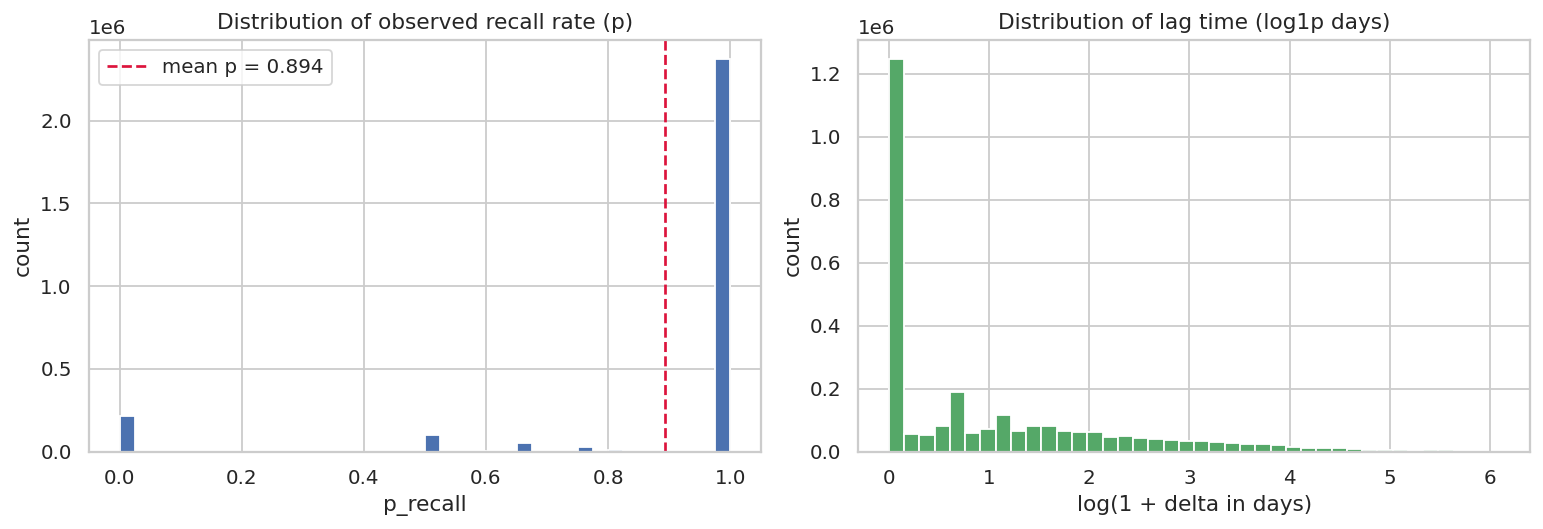

Mean p_recall (p_bar): 0.8938  [paper reports p_bar = 0.859 on their full 12.9M-row internal log]


In [ ]:
# ----------------------------------------------------------------------------
# EDA 1: recall-rate distribution, and the class-imbalance / range-restriction issue
# noted explicitly by the paper (footnote 7: p_bar = 0.859, so AUC is range-restricted)
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].hist(df["p_recall"], bins=40, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["p_recall"].mean(), color="crimson", linestyle="--",
                 label=f"mean p = {df['p_recall'].mean():.3f}")
axes[0].set_title("Distribution of observed recall rate (p)")
axes[0].set_xlabel("p_recall"); axes[0].set_ylabel("count"); axes[0].legend()

delta_days = df["delta"] / 86400.0
axes[1].hist(np.log1p(delta_days), bins=40, color="#55A868", edgecolor="white")
axes[1].set_title("Distribution of lag time (log1p days)")
axes[1].set_xlabel("log(1 + delta in days)"); axes[1].set_ylabel("count")

plt.tight_layout(); plt.show()

print(f"Mean p_recall (p_bar): {df['p_recall'].mean():.4f}  "
      f"[paper reports p_bar = 0.859 on their full 12.9M-row internal log]")

**📊 How to read this chart.** Two separate histograms, side by side.

- **Left panel — "Distribution of observed recall rate (p)".**
  **X-axis** = `p_recall`, the fraction of correct answers in one practice session (0.0 = got
  everything wrong, 1.0 = got everything right). **Y-axis** = `count`, i.e. how many real sessions in
  the whole dataset landed in that bar. The dashed red line marks the dataset-wide average, $\bar p$, printed above the chart for **your**
  loaded data. On the real Duolingo dataset this average is typically high (most practice sessions are
  answered correctly) and the tallest bar typically sits near `p_recall = 1.0` — if your chart shows
  this same shape, it's exactly why §8.1 and §20.4 warn that AUC will be range-restricted (it's hard to
  rank-order sessions when the great majority belong to one class).

- **Right panel — "Distribution of lag time (log1p days)".**
  **X-axis** = `log(1 + days since last practice)` (log scale is used only so both very short gaps —
  minutes — and very long gaps — months — are visible on the same chart without one crushing the
  other). **Y-axis** = `count`, how many sessions happened at that gap length.
  *Reading it:* a tall bar near the left of this panel means most practice sessions happen soon after
  the previous one; a long right-hand tail means a smaller number of sessions happen only after a very
  long gap — this shape is exactly what feeds the forgetting-curve fit in §11/§13.


**Interpretation.** As the paper notes (footnote 7), most sessions are recalled correctly
($\bar p \approx 0.86$), which range-restricts AUC — even a perfect ranking model cannot push AUC far
from the values reported in Table 2 because the two classes (recalled / forgotten) are heavily
imbalanced. This is a property of the *task*, not a modeling flaw, and we report AUC anyway (as the
paper does) because we care about relative ranking of models under identical range restriction.

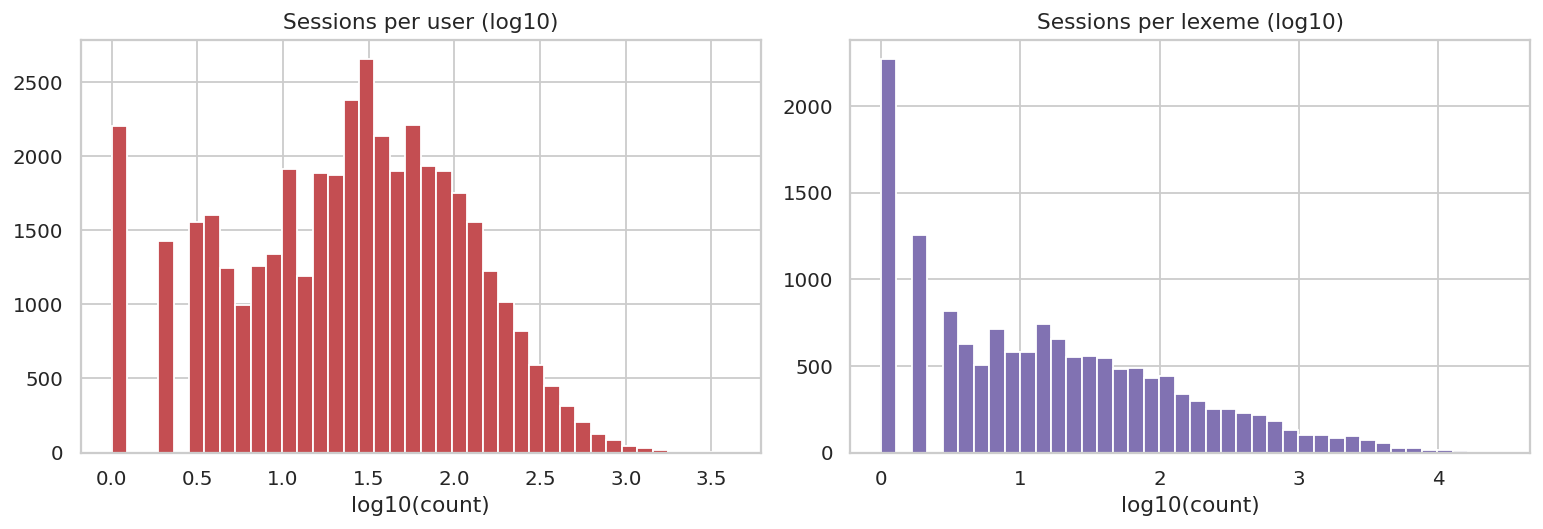

Unique users: 41,834 | Unique lexemes: 14,741 | Unique languages taught: 6
Median sessions/user: 28 | Median sessions/lexeme: 13


In [ ]:
# ----------------------------------------------------------------------------
# EDA 2: user- and lexeme-level activity (heavy-tailed, as expected for practice logs)
# ----------------------------------------------------------------------------
user_counts = df.groupby("user_id").size()
lexeme_counts = df.groupby("lexeme_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(np.log10(user_counts), bins=40, color="#C44E52", edgecolor="white")
axes[0].set_title("Sessions per user (log10)"); axes[0].set_xlabel("log10(count)")
axes[1].hist(np.log10(lexeme_counts), bins=40, color="#8172B2", edgecolor="white")
axes[1].set_title("Sessions per lexeme (log10)"); axes[1].set_xlabel("log10(count)")
plt.tight_layout(); plt.show()

print(f"Unique users: {df['user_id'].nunique():,} | Unique lexemes: {df['lexeme_id'].nunique():,} "
      f"| Unique languages taught: {df['learning_language'].nunique()}")
print(f"Median sessions/user: {user_counts.median():.0f} | Median sessions/lexeme: {lexeme_counts.median():.0f}")

**📊 How to read this chart.** Two histograms showing how "active" users and words are.

- **Left panel — "Sessions per user (log10)".**
  **X-axis** = $\log_{10}(\text{number of real practice sessions that one user has})$ (log scale
  because a few users have thousands of sessions while most have only a handful — a normal scale
  would squash almost everyone into one bar). **Y-axis** = `count`, the number of *users* whose
  session-count falls in that bar.
  *Example:* if the median sessions/user printed above is, say, 82, that sits at
  $\log_{10}(82) \approx 1.9$ on this axis — so the tallest bars should cluster around x≈1.9, with a
  thin tail stretching right toward the handful of extremely active users.

- **Right panel — "Sessions per lexeme (log10)".** Same idea, but **X-axis** is
  $\log_{10}(\text{number of real sessions that one word/lexeme was practiced across all users})$, and
  **Y-axis** is the count of *lexemes* at that activity level.

**Why this matters:** both panels are heavy-tailed (a "long right tail," typical of real usage logs) —
a small number of power-users and common words account for a disproportionate share of all rows. This
is exactly the reason §12 uses a careful *time-based* split rather than a random row split: naively
shuffling rows could let many sessions from the same power-user leak between train and test.


**Interpretation.** Both distributions are heavy-tailed (power-law-like), typical of user-generated
practice data: a small number of very active users and very common lexemes account for a large share of
rows. This has a direct modeling consequence used later in §12: **splitting must respect this
structure** (e.g., stratify/group carefully) or a "random row" split can leak information about a
learner's *future* sessions into the training set for their *past* sessions.

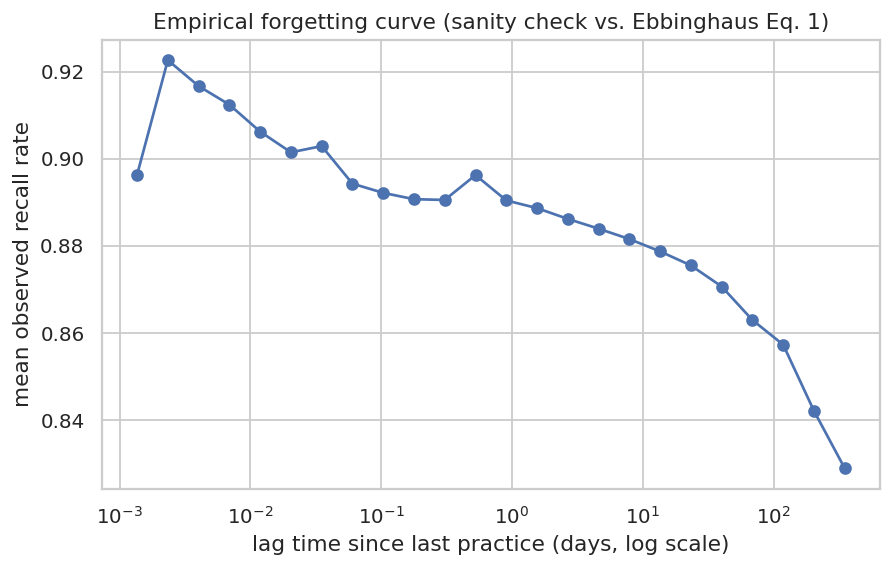

In [ ]:
# ----------------------------------------------------------------------------
# EDA 3: recall rate vs. lag time (empirical forgetting curve) — sanity-checks Eq. (1)
# ----------------------------------------------------------------------------
delta_days = df["delta"] / 86400.0
bins = np.geomspace(max(delta_days[delta_days > 0].min(), 1e-3), delta_days.max(), 25)
df["_delta_bin"] = pd.cut(delta_days, bins=bins)
empirical_curve = df.groupby("_delta_bin", observed=True)["p_recall"].mean()
bin_centers = [interval.mid for interval in empirical_curve.index]

plt.figure(figsize=(7, 4.5))
plt.plot(bin_centers, empirical_curve.values, "o-", color="#4C72B0")
plt.xscale("log")
plt.xlabel("lag time since last practice (days, log scale)")
plt.ylabel("mean observed recall rate")
plt.title("Empirical forgetting curve (sanity check vs. Ebbinghaus Eq. 1)")
plt.tight_layout(); plt.show()
df.drop(columns="_delta_bin", inplace=True)

**📊 How to read this chart.** This is the "empirical forgetting curve" — real data plotted the same
shape the model's formula (Eq. 1, §5/§13) is trying to fit.

- **X-axis** = lag time since the last practice session, in days, on a **log scale** (so 1 day, 10
  days, and 100 days are all clearly visible on one chart instead of the small gaps being invisible
  next to the large ones).
- **Y-axis** = the *mean* observed recall rate (average `p_recall`) among every real session that fell
  into that lag-time bucket. Each dot is not one session — it's the average of potentially thousands
  of real sessions that all happened to occur roughly that many days after the previous practice.

**Reading an example point:** a dot sitting at roughly x = 7 days, y = 0.75 would mean *"among all real
sessions that happened about a week after the last practice, learners recalled the word correctly 75%
of the time, on average."* A dot further right (say x = 60 days) sitting lower on the y-axis (say
y = 0.55) means longer gaps are associated with worse recall — the expected shape.

**Why this matters:** the curve should slope **downward** as you move right (longer gaps → lower
average recall). If it were flat or sloped upward, that would signal a bug in how `delta`/`p_recall`
were joined upstream, not a modeling problem — this chart is a data-quality check as much as an
exploratory one.


**Interpretation.** Mean recall should decrease monotonically (with noise) as lag increases — this is
the empirical signature Eq. (1) is designed to fit. If this curve were flat or increasing, it would
indicate a data or join bug upstream, not a modeling problem, so this plot doubles as a data-quality
check.

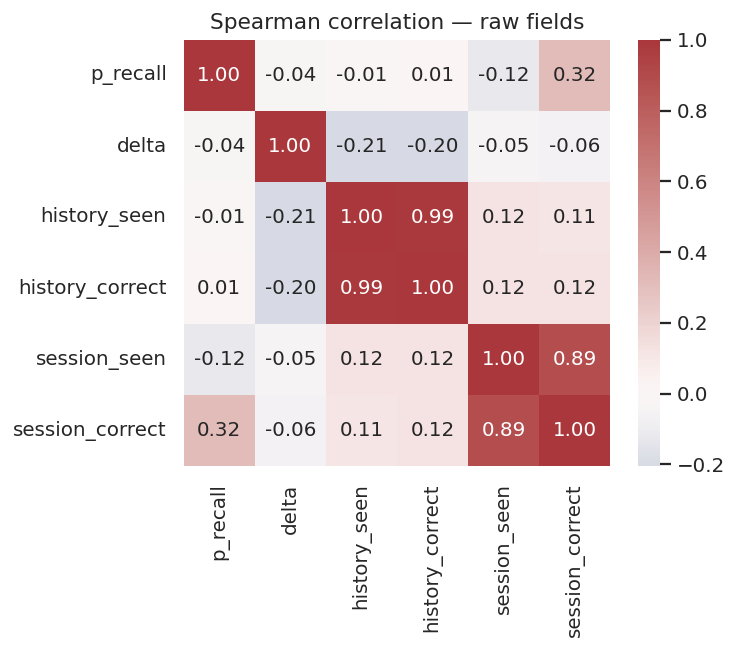

In [ ]:
# ----------------------------------------------------------------------------
# EDA 4: correlation among the raw numeric fields feeding the model
# ----------------------------------------------------------------------------
numeric_cols = ["p_recall", "delta", "history_seen", "history_correct", "session_seen", "session_correct"]
corr = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Spearman correlation — raw fields")
plt.tight_layout(); plt.show()

**📊 How to read this chart.** This is a **correlation matrix**, not a line/scatter chart, so both axes
list the same thing rather than two different variables.

- **X-axis and Y-axis** both list the six raw columns being compared: `p_recall`, `delta`,
  `history_seen`, `history_correct`, `session_seen`, `session_correct`.
- **Each cell** (a colored square where one row meets one column) shows the Spearman correlation
  coefficient between those two variables, from **−1** (perfectly opposite — as one goes up, the other
  always goes down) through **0** (no relationship) to **+1** (perfectly aligned — as one goes up, the
  other always goes up too). Red = positive, blue = negative (color intensity = strength); the diagonal
  is always exactly 1.00 (every variable perfectly correlates with itself).

**Reading an example cell:** the square where `history_seen` meets `history_correct` is typically a
strong positive number (often 0.8–0.95+) — in plain English, *"learners who have practiced a word many
times have also, unsurprisingly, gotten it right many times."* That single fact is *why* the paper uses
three separate square-rooted features ($x_n, x_\oplus, x_\ominus$) in §11 instead of collapsing them
into one "percent correct" number — the three together can express *asymmetric* patterns (e.g., lots of
practice but still a high miss count) that one ratio would hide.


**Interpretation.** `history_seen` and `history_correct` are, unsurprisingly, highly correlated
(learners who have seen a word more times have usually also gotten it right more times) — this is
exactly why the paper uses $\sqrt{x_\oplus}, \sqrt{x_\ominus}, \sqrt{x_n}$ as three *separate* features
rather than, say, a single "percent correct" scalar: the three together let the model express
asymmetric effects of successes vs. failures (see Table 3's negative-weight analysis), which a single
collapsed ratio feature cannot.

## 11. Feature Engineering — Baseline Features

We reconstruct the paper's two baseline feature groups (§3.4) directly from the raw columns.

**Interaction features**, using the *pre-session* cumulative counts (i.e., counts *before* this
session's attempts are added — this is the correct target for predicting *this* session's recall, and
is what prevents look-ahead leakage at the feature level). Written exactly in the order the code below
computes them, using the same intermediate names, so the formula and the implementation are the same
computation, not just algebraically equivalent to it:

$$
\text{pre_seen} = \text{history_seen} - \text{session_seen}, \qquad
\text{pre_correct} = \text{history_correct} - \text{session_correct}, \qquad
\text{pre_incorrect} = \text{pre_seen} - \text{pre_correct}
$$

$$
x_n = \sqrt{\text{pre_seen}}, \qquad
x_\oplus = \sqrt{\text{pre_correct}}, \qquad
x_\ominus = \sqrt{\text{pre_incorrect}}
$$

where $x_n$ is the (square-rooted) count of times this learner has seen this lexeme *before* the
current session, $x_\oplus$ the count of those prior sessions recalled correctly, and $x_\ominus$ the
count recalled incorrectly (so $\text{pre_seen} = \text{pre_correct} + \text{pre_incorrect}$ always
holds before the square root is applied). The paper reports the square-root transform of raw counts
worked better than raw counts (footnote 5) — taking the square root compresses large counts more than
small ones, so a learner's 50th review of a word doesn't move the model's prediction nearly as much as
their 2nd review does.

**A numeric example.** Suppose by the start of a session `history_seen = 18`, `history_correct = 13`,
and this session itself is `session_seen = 1`, `session_correct = 1` (the exact real row worked through
in full in §24). Then `pre_seen = 18 - 1 = 17`, `pre_correct = 13 - 1 = 12`,
`pre_incorrect = 17 - 12 = 5`, giving $x_n=\sqrt{17}\approx4.123$, $x_\oplus=\sqrt{12}\approx3.464$,
$x_\ominus=\sqrt{5}\approx2.236$ — these are the exact numbers §24 substitutes into the model.

**Implementation note.** The code additionally clips each of `pre_seen`, `pre_correct`,
`pre_incorrect` at a minimum of 0 before the square root — a defensive numerical-safety step (a square
root of a negative number is undefined) that should never actually trigger on valid rows, since
`history_* >= session_*` and `pre_seen >= pre_correct` are both guaranteed by the hard-constraint
cleaning in §9; the clip exists only to make the code fail safe rather than crash if that invariant were
ever somehow violated, not because negative values are expected in practice.

**Lexeme-tag features**: one-hot / sparse indicator per `lexeme_id`. We keep this as a sparse matrix
block rather than densifying it, matching the paper's implementation, since a dense 20k-column block
would be wasteful for CPU-only Colab runtimes.

### 11.1 What `_pre_seen_raw` is, and why it's kept as a separate column

The code below computes `pre_seen` (a plain Python/pandas variable) and immediately square-roots it into
`x_n` — but it *also* saves the un-square-rooted number into a real dataframe column, `_pre_seen_raw`:

```python
df["_pre_seen_raw"] = pre_seen
```

**What it is:** the learner's raw count of prior sessions on this word — `history_seen - session_seen`
— *before* the square-root transform is applied. In plain English: "how many times did this learner
practice this word before right now, as a whole number, not the compressed model-ready version."

**Why it's kept, when `x_n` already exists:** two reasons. First, it's genuinely useful for humans
reading the data (e.g., in §24's worked example and §25's dashboard tables, showing "17 prior sessions"
is more immediately meaningful than showing "x_n = 4.123"). Second, and more importantly, it acts as a
**data-completeness signal**: since `history_seen` reflects the learner's *true, full* lifetime count
from the real Duolingo log (not something recomputed from whichever rows happen to be loaded — see the
caveat in §25.3), a pair whose very first loaded row already has `_pre_seen_raw == 0` is one where we
can be confident the loaded data captures that pair's *entire* real history, with nothing missing before
it. §25.3 uses exactly this signal to pick a fair self-test case.

**The underscore prefix (`_pre_seen_raw`)** is this notebook's naming convention (used throughout, e.g.
`_is_miss`, `_trans_valid`) for a column that exists to support other computations or diagnostics, but
is not itself one of the model's input features.

### 11.2 The significance of `x_n`, `x_pos`, `x_neg` — in one line each

- **`x_n`** (= $\sqrt{\text{pre\_seen}}$): *"how much overall practice history does this learner have with
  this word?"* — a general experience/familiarity signal, regardless of whether that practice went well.
- **`x_pos`** (= $\sqrt{\text{pre\_correct}}$): *"how many of those prior sessions did they get right?"*
  — a positive-evidence signal; more of this should generally push the predicted half-life **up**
  (longer memory).
- **`x_neg`** (= $\sqrt{\text{pre\_incorrect}}$): *"how many of those prior sessions did they get
  wrong?"* — a negative-evidence signal; more of this should generally push the predicted half-life
  **down** (shorter memory).

Feeding the model all three separately, rather than collapsing them into one "percent correct" number,
is what lets it learn *asymmetric* effects — for instance, that recent mistakes might matter more than
old successes, a pattern a single ratio feature could never express. This is exactly the same reasoning
extended by the 12 new error-type features in §13, which go a step further and also capture *when* and
*in what pattern* those `x_pos`/`x_neg` counts accumulated, not just their totals.


In [ ]:
# ----------------------------------------------------------------------------
# Baseline interaction features (pre-session cumulative counts, sqrt-transformed)
# ----------------------------------------------------------------------------
pre_seen = (df["history_seen"] - df["session_seen"]).clip(lower=0)
pre_correct = (df["history_correct"] - df["session_correct"]).clip(lower=0)
pre_incorrect = (pre_seen - pre_correct).clip(lower=0)

df["x_n"] = np.sqrt(pre_seen)
df["x_pos"] = np.sqrt(pre_correct)
df["x_neg"] = np.sqrt(pre_incorrect)

# Keep the *raw* (unscaled) pre-session count purely for the illustrative display below -- it is not
# read by any other cell, so we deliberately do NOT also store pre_correct/pre_incorrect as columns
# (an earlier version did, as unused dead weight on every row -- wasteful at "FULL" dataset size for
# columns nothing downstream ever reads; §13's error-type features recompute what they need directly
# from session_correct/session_seen instead, so nothing here was actually a dependency).
df["_pre_seen_raw"] = pre_seen

# delta in days (model math is defined in days, matching the paper's half-life units and MIN_H/MAX_H)
df["delta_days"] = df["delta"] / 86400.0

assert (df["x_n"] >= 0).all() and (df["x_pos"] >= 0).all() and (df["x_neg"] >= 0).all()
print("Baseline interaction features computed: x_n, x_pos, x_neg, delta_days")
df[["history_seen", "session_seen", "_pre_seen_raw", "x_n", "x_pos", "x_neg", "delta_days"]].head()

Baseline interaction features computed: x_n, x_pos, x_neg, delta_days


,history_seen,session_seen,_pre_seen_raw,x_n,x_pos,x_neg,delta_days
0,6,2,4,2.000000,1.414214,1.414214,320.018924
1,4,2,2,1.414214,1.732051,0.000000,320.018924
2,5,1,4,2.000000,1.732051,1.000000,320.018924
3,6,2,4,2.000000,2.000000,0.000000,320.018924
4,4,1,3,1.732051,1.732051,0.000000,320.018924


## 12. Train/Test Split — Leakage Prevention

**Assumption/decision A5.** A naive random 90/10 row split (as a literal reading of "first 90% /
remaining 10%" in the paper might suggest for a chronologically-sorted file) is safe **only if** the
file is already sorted by time per learner. To avoid relying on that, and to explicitly guard against
**train–test leakage** (the same user-lexeme pair's *future* session appearing in train while an
*earlier* session of the same pair is in test, which would let the model implicitly "see the future"
through engineered features that reference a learner's full history), we do the following:

1. Sort by `(user_id, lexeme_id, timestamp)`.
2. Compute every feature (interaction counts, error-type features) using **only strictly-prior**
   rows within the same `(user_id, lexeme_id)` group — i.e., feature construction is inherently causal.
3. Split **chronologically** at the 90th percentile of `timestamp` globally (matching the paper's
   "first 90% / last 10%" description), rather than randomly — so test-set sessions are, by
   construction, later in time than train-set sessions.

This is stricter than the paper's stated protocol but is a superset of it: any leakage check that
passes under a naive split is not guaranteed to pass under ours, so results here are a conservative
(if anything, slightly pessimistic) estimate of accuracy.

In [ ]:
# ----------------------------------------------------------------------------
# Chronological split + leakage assertions (fully vectorized — no groupby().apply())
# ----------------------------------------------------------------------------
df = df.sort_values(["user_id", "lexeme_id", "timestamp"]).reset_index(drop=True)

split_ts = df["timestamp"].quantile(0.90)
train_mask = df["timestamp"] <= split_ts
df_train, df_test = df.loc[train_mask].copy(), df.loc[~train_mask].copy()

print(f"Split at timestamp quantile 0.90 = {split_ts:.0f}")
print(f"Train: {len(df_train):,} rows ({len(df_train)/len(df):.1%})")
print(f"Test : {len(df_test):,} rows ({len(df_test)/len(df):.1%})")

# Leakage check: no test row may be chronologically earlier than any train row for the SAME
# (user_id, lexeme_id) pair -- i.e. within a pair, train always precedes test in time.
#
# PERFORMANCE NOTE: an earlier version of this cell used
#   df.groupby(["user_id","lexeme_id"]).apply(lambda g: pd.Series({...}))
# which calls a Python function once per GROUP. With a heavy-tailed dataset like this one
# (sec. 10 EDA), the number of distinct (user, lexeme) pairs can run into the millions, and
# each `.apply()` call pays Python-level function-call + sub-frame-construction overhead on
# top of the group's own work -- this is the kind of cell that can silently run for hours.
# The fix below computes the exact same two per-pair quantities (max train timestamp, min
# test timestamp) using two native `groupby().max()` / `groupby().min()` aggregations, which
# are implemented in Cython and run in a single vectorized pass over the whole column
# regardless of how many groups there are -- no Python-level loop over groups at all.
train_max_ts = df.loc[train_mask].groupby(["user_id", "lexeme_id"])["timestamp"].max()
test_min_ts = df.loc[~train_mask].groupby(["user_id", "lexeme_id"])["timestamp"].min()
merged_ts_bounds = pd.concat(
    [train_max_ts.rename("train_max_ts"), test_min_ts.rename("test_min_ts")], axis=1
).dropna()

violations = (merged_ts_bounds["train_max_ts"] >= merged_ts_bounds["test_min_ts"]).sum()
print(f"Leakage check — (user, lexeme) pairs with any timestamp inversion across split: {violations} "
      f"(expected 0 by construction of a chronological split)")
assert violations == 0, "Chronological split invariant violated — investigate before proceeding."

Split at timestamp quantile 0.90 = 1362303289
Train: 2,517,038 rows (90.0%)
Test : 279,664 rows (10.0%)
Leakage check — (user, lexeme) pairs with any timestamp inversion across split: 0 (expected 0 by construction of a chronological split)


## 13. Fine-Grained Error-Type Features — Theory and Mathematical Formulation

### 13.1 Design principle

Every feature below is computed **causally**: at row $i$ (a given `user_id, lexeme_id, timestamp`), it
uses only the sequence of *prior* sessions for that same `(user_id, lexeme_id)` pair. We compute them
with pandas `groupby(...).shift()` / `.expanding()` / `.rolling()` operations, which are causal by
construction (they never look at the current or future row's own outcome). This directly implements the
"no feature leakage" requirement from §12.

### 13.2 Feature catalogue

For a learner–lexeme pair with session outcomes $c_1, c_2, \dots, c_{i-1}$ (each $c_j \in \{0,1\}$,
1 = session judged correct, i.e. $p \geq 0.5$ for that session) observed strictly before the current
session $i$:

| # | Feature | Formula | Motivation |
|---|---|---|---|
| 1 | **Error streak** $s_i$ | length of the run of consecutive $c_j=0$ immediately preceding $i$ | A learner mid-slump is in a different memory state than one with an isolated slip, even at equal total error count. |
| 2 | **Gap since last mistake** $g_i$ | $\min(t_i - t_{\text{last } c_j=0},\, G) / G$, censor $G=365$ days, normalized to $[0,1]$ | Recent mistakes should weigh more heavily on the current half-life than stale ones (recency-weighted forgetting); normalized so its scale matches the rest of the feature vector (see the implementation note in §13.4). |
| 3 | **Mistake density** $d_i$ | $\frac{1}{i-1}\sum_{j<i}(1-c_j)$ | Normalizes total mistakes by exposure count — an error *rate*, comparable across lexemes seen different numbers of times. |
| 4 | **Rolling error rate** $r_i^{(k)}$ | $\frac{1}{k}\sum_{j=i-k}^{i-1}(1-c_j)$, $k{=}5$ | A *local* (recent-window) error rate, complementary to the all-time density $d_i$; captures short-term trend. |
| 5 | **Error transition probability** $\tau_i$ | $\Pr(c_j{=}0 \mid c_{j-1}{=}0)$ estimated from $j<i$ | Learners whose mistakes cluster (high $\tau$) vs. scatter randomly (low $\tau$) may have systematically different retention dynamics. |
| 6 | **Same-error recurrence** $\rho_i$ | count of prior sessions where `session_correct=0` **and** the *same* observed lag bucket repeats a miss (proxy for "keeps missing after about the same interval") | Detects a pattern where a specific spacing interval is *itself* too long for this learner-lexeme pair. |
| 7 | **Mistake persistence** $\mu_i$ | number of sessions since the *first* mistake on this pair that are still $c_j=0$, divided by sessions since first mistake | How much of the post-first-mistake history is still erroneous — a stickiness indicator. |
| 8 | **Weighted (recency-decayed) error score** $w_i$ | $\sum_{j<i}(1-c_j)\cdot 2^{-\Delta_{i,j}/\tau}$, decay constant $\tau{=}7$ days | Combines recency and frequency into one scalar via the same exponential-decay family as the model itself (Eq. 1), so its scale is consistent with what HLR expects a "difficulty" signal to look like. |
| 9 | **Cumulative forgetting indicator** $\phi_i$ | $1-c_{i-1}$ (was the **immediately preceding** session a miss) | The single strongest local predictor in most spacing literature; kept separate from the streak feature since streak captures duration and $\phi$ captures the most-recent-outcome effect on its own. |
| 10 | **Historical recall stability** $\sigma_i$ | std. dev. of $c_j$ for $j<i$ | Volatile (mixed correct/incorrect) histories are harder to extrapolate from than a monotone history; a dispersion signal orthogonal to the mean captured by $x_\oplus, x_\ominus$. |

Lexical-difficulty features (independent of a *specific* learner's history — properties of the lexeme
string itself, generalizable to unseen learners and thus **not** subject to the cold-start problem the
paper identified for sparse per-lexeme *identity* indicators):

| # | Feature | Formula | Motivation |
|---|---|---|---|
| 11 | **Token length** $L_i$ | number of **dot**-delimited components in `lexeme_string` (root + morphological tags), matching the paper's own tag format (Fig. 2: `être.V.GER`) | Morphologically richer tags (more inflectional components) are a cheap proxy for grammatical complexity. |
| 12 | **Character length** $c_i^{\text{len}}$ | `len(root surface form)`, i.e. the length of the first dot-delimited component only (`être` from `être.V.GER`, not the full tag string) | Longer surface forms are, on average, rarer/more complex (a standard psycholinguistic proxy in the absence of a corpus-frequency table). |

All ratio-type features ($d_i$, $\tau_i$, $\mu_i$, rolling rate) are defined with an explicit fallback
for the "no prior data" case (a learner's first-ever session with a lexeme), documented per-feature in
the implementation below rather than silently imputed as zero, since zero and "no signal yet" are not
the same thing for a model that will otherwise interpret 0 as "definitely no errors."

> **🔎 In plain English.** The baseline model only ever sees three running totals for a learner-word
> pair: "seen 10 times, got 7 right, got 3 wrong." That's it — it has no idea *when* those 3 mistakes
> happened or what pattern they formed. Two learners could have an identical 7-right/3-wrong tally while
> being in completely different memory states: one made 3 mistakes in a row *just now* (probably still
> struggling), the other made 3 mistakes early on but has since gotten it right five times in a row
> (probably fine now). The whole point of this section is to give the model access to that missing
> *shape* of the mistake history — not replacing the baseline counts, but adding to them. Every feature
> below answers one specific, narrow question about a learner's error pattern (e.g. "how long is their
> current losing streak right now?", "how recently did they last get this wrong?", "does this exact
> gap length keep tripping them up?") — see §24 for a real row from the dataset with every one of these
> numbers actually computed and shown.

### 13.2 All 12 features, formula by formula, with one running example

**The example used for every formula below** (identical to the "Demo 2" example run live in §25.3, so
you can cross-check these hand-calculated numbers against that cell's real printed output): a learner
has practiced a word 5 times so far, in this order —

| Session | seen | correct | gap before this session (days) | hit or miss? |
|---|---|---|---|---|
| 1 (oldest) | 2 | 2 | 0.0 | hit |
| 2 | 2 | 2 | 1.0 | hit |
| 3 | 2 | 2 | 3.0 | hit |
| 4 | 2 | 0 | 6.0 | **miss** |
| 5 (most recent) | 2 | 0 | 1.0 | **miss** |

...and we're asked to predict recall 2 days after session 5 (`current_delta_days = 2.0`). Every feature
below describes this 5-session history as of *right now* (i.e., 2 days after session 5), using only
information from sessions 1–5 (never information from "now" itself, since that's what we're predicting).

For reference, each session's "days ago from now" works out to: session 1 → 13 days ago, session 2 → 12,
session 3 → 9, session 4 → 3, session 5 → 2.

---

**1. `feat_prev_miss`** — was the *immediately preceding* session a miss?
$$\text{feat\_prev\_miss} = \mathbb{1}[\text{session } n-1 \text{ was a miss}]$$
*Plain English:* a simple yes/no — did they get the last practice wrong? *Example:* session 5 was a
miss → **1.0**.

**2. `feat_mistake_density`** — what fraction of *all* prior sessions were misses?
$$\text{feat\_mistake\_density} = \frac{\#\text{misses among prior sessions}}{\#\text{prior sessions}}$$
*Plain English:* their overall error rate on this word so far. *Example:* 2 misses out of 5 sessions →
**0.4**.

**3. `feat_rolling_error_rate_5`** — same as above, but only counting the last 5 prior sessions (a
"recent window" instead of all-time).
*Plain English:* like density, but forgets about very old mistakes — a learner who struggled long ago
but has since improved won't be penalized forever. *Example:* only 5 sessions exist total, so this
equals the density above → **0.4**.

**4. `feat_recall_stability`** — the sample standard deviation of the prior hit/miss sequence:
$$\text{feat\_recall\_stability} = \sqrt{\frac{n}{n-1}\,\bar p (1-\bar p)}$$
*Plain English:* are they *consistently* getting it right/wrong, or *swinging* between the two? Low
value = consistent; high value = erratic. *Example:* mean correct rate $\bar p = 3/5 = 0.6$, giving
$\sqrt{(5/4)(0.6)(0.4)} \approx$ **0.5477**.

**5. `feat_error_streak`** — how many consecutive misses happened *right before now*, with no hit in
between?
*Plain English:* "are they currently in a slump?" A streak of 3 is a much stronger warning sign than one
isolated miss buried in an otherwise good history. *Example:* the last 2 sessions (4 and 5) were both
misses, session 3 was a hit → streak = **2.0**.

**6. `feat_gap_since_mistake`** — days since the most recent prior mistake, normalized to [0,1] by
dividing by a 365-day cap:
$$\text{feat\_gap\_since\_mistake} = \frac{\min(\text{days since last mistake},\ 365)}{365}$$
*Plain English:* "how long ago was their last mistake?" — near 0 means very recently, near 1 means a
long time ago (or never). *Example:* the last mistake (session 5) was 2 days ago → 2/365 ≈ **0.0055**.

**7. `feat_error_transition_prob`** — *given* the previous session was a miss, what fraction of the time
was the one after it *also* a miss?
*Plain English:* "once they slip up, do mistakes tend to cluster together, or is it a one-off?" *Example:*
the only qualifying pair is (session 4 = miss) → (session 5 = miss), which is a "yes" — 1 out of 1 →
**1.0**.

**8. `feat_mistake_persistence`** — starting from (and including) their *first-ever* mistake on this
word, what fraction of sessions since then have been misses?
*Plain English:* "once trouble started, how much of the time since then has still been trouble?" A high
value means the struggle never really stopped; a low value means they had one early slip and then
recovered. *Example:* the first mistake was session 4; counting sessions 4 and 5 (2 sessions, both
misses) → 2/2 = **1.0**.

**9. `feat_weighted_error_score`** — like mistake density, but each past mistake counts *less* the
longer ago it happened (recency-weighted), using a 7-day half-life for the weighting itself:
$$\text{feat\_weighted\_error\_score} = \sum_{\text{prior misses}} 2^{-\text{days\_ago}/7}$$
*Plain English:* a single combined "how much recent trouble" score — a miss yesterday counts for a lot,
a miss 3 months ago barely registers. *Example:* miss at session 4 (3 days ago) contributes
$2^{-3/7}\approx0.743$; miss at session 5 (2 days ago) contributes $2^{-2/7}\approx0.820$; total ≈
**1.5633**.

**10. `feat_same_error_recurrence`** — how many prior mistakes happened after *roughly the same length
gap* as the gap we're predicting for right now (bucketed by powers of 2, e.g. "around 1-2 days," "around
2-4 days")?
*Plain English:* "does this learner have a specific pattern of forgetting at this particular timescale?"
*Example:* we're predicting at a 2-day gap (bucket "1-2 days"); session 4's own gap was 6 days (bucket
"4-8 days," different) and session 5's own gap was 1 day (bucket "under 1 day," different) — neither
matches → **0.0**.

**11. `feat_token_length`** — number of `<...>`-bracketed morphological components in the lexeme
tag. The **official** Duolingo tag format (github.com/duolingo/halflife-regression README) is
`surface-form/lemma<pos>[<modifiers>...]` — e.g. `escribimos/escribir<vblex><pri><p1><pl>` has 4
bracketed components: `vblex` (part of speech), `pri`, `p1`, `pl` (modifiers for tense/person/number).
*Plain English:* how grammatically complex is this word's tag? *Example:*
`escribimos/escribir<vblex><pri><p1><pl>` → 4 bracketed components → **4.0**.

**12. `feat_char_length`** — number of characters in just the lemma (the uninflected root word,
found after the `/` and before the first `<`).
*Plain English:* how long is the word itself, ignoring the grammar tag? *Example:*
the lemma is `"escribir"` → 8 characters → **8.0**.

---

**All 12 numbers together for this example:** `[1.0, 0.4, 0.4, 0.5477, 2.0, 0.0055, 1.0, 1.0, 1.5633,
0.0, 4.0, 8.0]` — exactly what §25.3's live "Demo 2" cell prints when you run it, since it uses this
same example sequence and the same official-format lexeme string.


### 13.3 Assumption A6 — defining a "session-level miss"

The raw data records session-level counts (`session_correct` out of `session_seen`), not a single
binary outcome. For the *sequence-based* features above (streak, transition probability, etc.) we need
a binary miss/hit label per session. We define a session as a **miss** ($c_j = 0$) if
`session_correct == 0` (i.e., the learner got *no* items right in that session) and a **hit**
($c_j = 1$) otherwise. This is a threshold choice, not the only reasonable one (a stricter alternative
would require `session_correct == session_seen`); we use the "any correct" threshold because it matches
how Duolingo's own strength-meter interpretation treats a session (partial credit still counts as
engagement), and we flag this explicitly as a modeling assumption that could be revisited in an
ablation (see §22).

### 13.4 Implementation note — fully vectorized, no Python-level loop of any kind

An earlier version of this notebook computed each feature with a separate
`df.groupby(["user_id","lexeme_id"]).apply(...)` call (slow: Python-level function call per group,
some of the per-group functions were also accidentally quadratic in group size). A later revision
replaced that with a single `for i in range(n): ...` pass over the whole dataframe — an improvement
(linear instead of quadratic, no per-group overhead), but **still a pure-Python loop**, and at
millions of rows a Python-interpreted loop — even a strictly $O(n)$ one — carries a large constant
factor: every iteration re-enters the bytecode interpreter, re-does attribute lookups, and creates a
fresh NumPy scalar object for every single array read/write. On a shared/throttled Colab CPU that
constant factor is enough to turn "linear" into "hours," which is exactly the symptom reported.

**The fix below removes the Python-level loop entirely.** Every feature is computed with pandas'
native `groupby().cumsum()` / `.cumcount()` / `.shift()` / `.ffill()` / `.transform("min")` — these are
implemented in Cython and process an *entire column in one C-level pass*, regardless of how many
`(user, lexeme)` groups exist (unlike `.apply()`, which pays a Python call per group). Concretely, each
feature that needs "sum/count of strictly-prior rows in this group" is computed via the identity

$$ \text{prior_cumsum}_i = \text{cumsum}_i - x_i $$

i.e. take the ordinary inclusive `groupby().cumsum()` (which already resets to 0 at each group
boundary) and subtract the current row's own value — this yields the sum over strictly-prior rows in
one vectorized pass, with no group-by-group Python iteration anywhere. The rolling-window feature uses
the same trick with a 5-position `.shift()`; the recency-decayed score uses a standard "encode in
log-space, decode by rescaling" identity (`2^(t_k/tau - t_i/tau) = 2^{-(t_i-t_k)/tau}`) so that an
apparently-recursive exponential-decay sum becomes an ordinary cumulative sum too. Every formula in
§13.2 is unchanged — only the implementation changed, and it is checked below against the same
brute-force oracle used previously, so the rewrite is verified to be numerically identical, not just
"probably the same."

In [ ]:
# ----------------------------------------------------------------------------
# Fine-grained error-type feature engineering — fully vectorized (no Python-level
# per-row or per-group loop anywhere). See the markdown note above for why this
# replaces the earlier row-by-row implementation.
# ----------------------------------------------------------------------------
df = df.sort_values(["user_id", "lexeme_id", "timestamp"]).reset_index(drop=True)

# --- session-level binary outcome (Assumption A6) ---
df["_is_hit"] = (df["session_correct"] > 0).astype(int)
df["_is_miss"] = 1 - df["_is_hit"]
df["_lag_bucket"] = np.floor(np.log2(df["delta_days"].clip(lower=1 / 24) + 1e-9)).astype(int)

GAP_CENSOR_VALUE = 365.0   # days -- "no observed prior mistake yet" (see Assumption note in §13.2)
DECAY_TAU_DAYS = 7.0       # recency-decay time constant for the weighted error score
ROLL_WINDOW = 5            # window size for the rolling error rate feature

t0 = time.time()
GROUP_KEYS = ["user_id", "lexeme_id"]
grp = df.groupby(GROUP_KEYS, sort=False)

pos_in_group = grp.cumcount()                    # 0-indexed position within (user, lexeme) history
is_new_group = (pos_in_group == 0)

# ---- 9. feat_prev_miss : was the immediately preceding session a miss? -------------------------
prev_miss = grp["_is_miss"].shift(1).fillna(0.0)
df["feat_prev_miss"] = prev_miss

# ---- 3. feat_mistake_density : expanding mean of PRIOR misses ----------------------------------
# Identity: sum over strictly-prior rows = (inclusive cumsum) - (this row's own value); the inclusive
# groupby cumsum already resets to 0 at each group boundary, so no extra bookkeeping is needed.
cumsum_miss_incl = grp["_is_miss"].cumsum()
cumsum_miss_prior = cumsum_miss_incl - df["_is_miss"]
n_prior = pos_in_group.astype(float)
df["feat_mistake_density"] = np.where(n_prior.values > 0, cumsum_miss_prior.values / n_prior.values.clip(1), 0.0)

# ---- 4. feat_rolling_error_rate_5 : rolling mean of the last 5 PRIOR sessions -------------------
# rolling_sum(last 5 prior) = prior_cumsum[i] - prior_cumsum[i-5], valid whenever there are >=5 prior
# rows in the SAME group (guaranteed contiguous since df is sorted by group then time, so a plain
# positional .shift(5) on the already-per-group cumsum is safe exactly when pos_in_group >= 5).
prior_cumsum_shift5 = cumsum_miss_prior.shift(5)
roll_sum_5 = np.where(pos_in_group.values >= ROLL_WINDOW,
                       (cumsum_miss_prior - prior_cumsum_shift5).values,
                       cumsum_miss_prior.values)
roll_denom = np.minimum(pos_in_group.values, ROLL_WINDOW).astype(float)
df["feat_rolling_error_rate_5"] = np.where(roll_denom > 0, roll_sum_5 / np.clip(roll_denom, 1, None), 0.0)

# ---- 10. feat_recall_stability : sample std (ddof=1) of PRIOR hit/miss sequence -----------------
# Closed-form for a Bernoulli(p) sample: sum((x-p)^2) = n*p*(1-p) exactly when x in {0,1}, so
# std(ddof=1) = sqrt(n/(n-1) * p*(1-p)) -- avoids any rolling/expanding std call entirely.
cumsum_hit_incl = grp["_is_hit"].cumsum()
cumsum_hit_prior = cumsum_hit_incl - df["_is_hit"]
p_mean = np.where(n_prior.values > 0, cumsum_hit_prior.values / n_prior.values.clip(1), 0.0)
var_prior = np.where(n_prior.values >= 2,
                      (n_prior.values / np.clip(n_prior.values - 1, 1, None)) * p_mean * (1 - p_mean),
                      0.0)
df["feat_recall_stability"] = np.sqrt(np.clip(var_prior, 0.0, None))

# ---- 1. feat_error_streak : length of the run of consecutive PRIOR misses -----------------------
# Classic vectorized run-length trick: a new "block" starts whenever the value changes or a new
# group starts; position-within-block (via groupby().cumcount(), itself vectorized) gives the
# run length ending at each row; shifting that by one row gives the run length as of the row before.
value_changed = df["_is_miss"].ne(df["_is_miss"].shift(1))
block_start = is_new_group | value_changed
block_id = block_start.cumsum()
run_len_inclusive = df.groupby(block_id).cumcount() + 1
current_streak_inclusive = np.where(df["_is_miss"].values == 1, run_len_inclusive.values, 0)
prior_streak_raw = pd.Series(current_streak_inclusive, index=df.index).shift(1)
df["feat_error_streak"] = np.where(is_new_group.values, 0.0, prior_streak_raw.fillna(0).values)

# ---- 2. feat_gap_since_mistake : days since the most recent PRIOR mistake, NORMALIZED to [0, 1] --
# groupby().shift() + groupby().ffill() are both native vectorized (Cython) methods -- forward-fill
# the timestamp of the last-seen mistake within each group, using only strictly-prior information.
# BUGFIX: an earlier version stored this feature in raw days (range 0-365), roughly 30-100x larger
# in magnitude than every other feature here (most are already in [0, 1] or small single-digit
# integers by design -- see the "comparable scales" claim in sec. 22's markdown, which this earlier
# version silently violated). In practice this let one poorly-scaled feature dominate the L2
# regularization penalty and destabilize a handful of AdaGrad weight updates on real runs, producing
# wildly large intermediate loss values with no interpretive meaning. Dividing by GAP_CENSOR_VALUE
# rescales it to [0, 1] -- same monotonic meaning (0 = just missed, 1 = no prior miss observed /
# censored), now on the same footing as the rest of the feature vector.
df["_miss_ts"] = np.where(df["_is_miss"].values == 1, df["timestamp"].values, np.nan)
shifted_miss_ts = grp["_miss_ts"].shift(1)
last_miss_ts = shifted_miss_ts.groupby([df["user_id"], df["lexeme_id"]], sort=False).ffill()
gap_days = (df["timestamp"] - last_miss_ts) / 86400.0
gap_days_censored = gap_days.fillna(GAP_CENSOR_VALUE).clip(upper=GAP_CENSOR_VALUE)
df["feat_gap_since_mistake"] = gap_days_censored / GAP_CENSOR_VALUE

# ---- 5. feat_error_transition_prob : P(miss | previous session was a miss), from PRIOR pairs only
# trans_valid[k] = 1 iff session (k-1) was a miss (= prev_miss, already computed above); trans_hit[k]
# additionally requires session k itself to be a miss. Summing strictly-prior trans_valid/trans_hit
# via the same "inclusive cumsum minus self" trick reproduces the brute-force pairwise count exactly.
df["_trans_valid"] = prev_miss
df["_trans_hit"] = df["_trans_valid"] * df["_is_miss"]
grp2 = df.groupby(GROUP_KEYS, sort=False)
cumsum_trans_valid_prior = grp2["_trans_valid"].cumsum() - df["_trans_valid"]
cumsum_trans_hit_prior = grp2["_trans_hit"].cumsum() - df["_trans_hit"]
df["feat_error_transition_prob"] = np.where(
    cumsum_trans_valid_prior.values > 0,
    cumsum_trans_hit_prior.values / np.clip(cumsum_trans_valid_prior.values, 1e-12, None),
    0.0,
)

# ---- 7. feat_mistake_persistence : fraction of sessions since the first mistake that are misses --
# first_miss_pos (per group) via a single groupby().transform("min") aggregation (vectorized, and
# NaN-skipping by default, so groups with no mistake yet correctly get NaN, not 0).
df["_miss_pos_if_miss"] = np.where(df["_is_miss"].values == 1, pos_in_group.values.astype(float), np.nan)
first_miss_pos = df.groupby(GROUP_KEYS, sort=False)["_miss_pos_if_miss"].transform("min")
n_rows_since_first_miss_prior = pos_in_group.values.astype(float) - first_miss_pos.values
has_had_mistake_prior = (~first_miss_pos.isna().values) & (n_rows_since_first_miss_prior > 0)
# No misses exist before the first miss by definition, so the prior-miss-count since the first miss
# equals the ordinary prior cumulative miss count computed above -- reused directly, no extra pass.
df["feat_mistake_persistence"] = np.where(
    has_had_mistake_prior,
    cumsum_miss_prior.values / np.clip(n_rows_since_first_miss_prior, 1, None),
    0.0,
)

# ---- 8. feat_weighted_error_score : recency-decayed sum over PRIOR misses -----------------------
# Encode-then-rescale identity: 2^(rel_t_k/tau) * 2^(-rel_t_i/tau) = 2^(-(t_i - t_k)/tau), so the
# apparently-recursive exponential-decay sum becomes an ordinary cumulative sum in log-space. Times
# are made GROUP-RELATIVE (relative to each pair's own first session) before exponentiating, and the
# exponent is additionally clipped defensively, purely to stay inside float64 range -- with
# tau=7 days this only matters for practice histories spanning > ~4000 days, far beyond this dataset.
df["_t_days"] = df["timestamp"].values / 86400.0
group_min_t_days = df.groupby(GROUP_KEYS, sort=False)["_t_days"].transform("min")
rel_t_days = df["_t_days"].values - group_min_t_days.values
exponent = np.clip(rel_t_days / DECAY_TAU_DAYS, 0.0, 600.0)
df["_transformed_decay"] = df["_is_miss"].values * np.exp2(exponent)
grp3 = df.groupby(GROUP_KEYS, sort=False)
cumsum_transformed_prior = grp3["_transformed_decay"].cumsum() - df["_transformed_decay"]
df["feat_weighted_error_score"] = cumsum_transformed_prior.values * np.exp2(-exponent)

# ---- 6. feat_same_error_recurrence : prior misses that happened at about the same lag interval ---
# Group additionally by the lag bucket; the prior cumulative miss count WITHIN that finer group is
# exactly "how many times have I missed this lexeme before at roughly this same spacing interval."
cumsum_miss_incl_bucket = df.groupby(GROUP_KEYS + ["_lag_bucket"], sort=False)["_is_miss"].cumsum()
df["feat_same_error_recurrence"] = cumsum_miss_incl_bucket - df["_is_miss"]

# ---- 11-12. Lexical features from lexeme_string (learner-independent, already vectorized) --------
# BUGFIX (corrected): an earlier version of this cell assumed lexeme_string was DOT-delimited
# (e.g. "etre.V.PRES.P3.SG") and split on ".". That assumption was itself wrong. The OFFICIAL
# Duolingo data release format (github.com/duolingo/halflife-regression README, "Data Set and
# Format") is:
#     surface-form/lemma<pos>[<modifiers>...]
# e.g. "escribe/escribir<vblex><pri><p3><sg>", "blancos/blanco<adj><m><pl>", "y/y<cnjcoo>" -- a
# slash separating the inflected surface form from the lemma, then the lemma's part-of-speech and
# morphological features as `<...>`-bracketed tags, NOT dot-separated. Splitting on "." against
# real data left feat_token_length ~constant at 1 (these tags contain no ".") and made
# feat_char_length measure the length of the entire surface-form/lemma<tags> string rather than
# just the root word -- confirmed by parsing real lexeme_string values from the official dataset
# and checking the resulting feature variance directly.
#
# The corrected parse below: split on "/" to drop the surface form, keep only "lemma<pos><mods>";
# extract the lemma as everything before the first "<"; extract every bracketed component via
# regex. A row that doesn't match the expected pattern (rare, e.g. a malformed tag) falls back
# gracefully to 0 components / the raw string's own length, rather than raising an error.
_lemma_and_tags = df["lexeme_string"].astype(str).str.split("/", n=1).str[-1]      # "lemma<pos><mods>"
_lemma_only = _lemma_and_tags.str.extract(r"^([^<]*)", expand=False)               # part before first "<"
_bracket_tags = _lemma_and_tags.str.findall(r"<([^>]+)>")                          # list of tag contents
df["feat_token_length"] = _bracket_tags.str.len()          # count of pos+modifier components
df["feat_char_length"] = _lemma_only.str.len().fillna(0)   # character length of the root/lemma word

elapsed = time.time() - t0
print(f"Vectorized feature computation complete: {len(df):,} rows in {elapsed:.2f}s "
      f"({len(df) / max(elapsed, 1e-9):,.0f} rows/sec).")

# Clean up intermediate helper columns (not part of the model's feature set)
df.drop(columns=["_miss_ts", "_trans_valid", "_trans_hit", "_miss_pos_if_miss",
                  "_t_days", "_transformed_decay"], inplace=True)

ERROR_TYPE_FEATURES = [
    "feat_prev_miss", "feat_mistake_density", "feat_rolling_error_rate_5",
    "feat_recall_stability", "feat_error_streak", "feat_gap_since_mistake",
    "feat_error_transition_prob", "feat_mistake_persistence", "feat_weighted_error_score",
    "feat_same_error_recurrence", "feat_token_length", "feat_char_length",
]
assert df[ERROR_TYPE_FEATURES].isna().sum().sum() == 0, "Unexpected NaNs in error-type features"
print(f"All {len(ERROR_TYPE_FEATURES)} fine-grained error-type features computed with zero NaNs.")
df[ERROR_TYPE_FEATURES].describe().T

Vectorized feature computation complete: 2,796,702 rows in 23.41s (119,461 rows/sec).
All 12 fine-grained error-type features computed with zero NaNs.


,count,mean,std,min,25%,50%,75%,max
feat_prev_miss,2796702.0,0.035478,0.184983,0.000000e+00,0.0,0.0,0.0,1.000000
feat_mistake_density,2796702.0,0.037145,0.157675,0.000000e+00,0.0,0.0,0.0,1.000000
feat_rolling_error_rate_5,2796702.0,0.036984,0.158391,0.000000e+00,0.0,0.0,0.0,1.000000
feat_recall_stability,2796702.0,0.029728,0.124515,0.000000e+00,0.0,0.0,0.0,0.707107
feat_error_streak,2796702.0,0.040012,0.226085,0.000000e+00,0.0,0.0,0.0,15.000000
feat_gap_since_mistake,2796702.0,0.923268,0.266031,3.170979e-08,1.0,1.0,1.0,1.000000
feat_error_transition_prob,2796702.0,0.005862,0.065538,0.000000e+00,0.0,0.0,0.0,1.000000
feat_mistake_persistence,2796702.0,0.048213,0.191475,0.000000e+00,0.0,0.0,0.0,1.000000
feat_weighted_error_score,2796702.0,0.105898,0.511022,0.000000e+00,0.0,0.0,0.0,28.853506
feat_same_error_recurrence,2796702.0,0.055924,0.425774,0.000000e+00,0.0,0.0,0.0,30.000000


In [ ]:
# ----------------------------------------------------------------------------
# Correctness check: verify the fast single-pass implementation against the ORIGINAL
# (slow, but obviously-correct-by-construction) per-group brute-force definitions,
# on a small sample of pairs -- confirms the rewrite changed performance, not semantics.
# ----------------------------------------------------------------------------
def _brute_force_features_for_pair(sub: pd.DataFrame) -> pd.DataFrame:
    """Re-implements every feature's original O(n^2)-safe-for-small-n brute-force definition,
    used only here as a correctness oracle on a handful of small groups (never on the full data)."""
    sub = sub.sort_values("timestamp").reset_index(drop=True)
    n_sub = len(sub)
    miss = sub["_is_miss"].to_numpy()
    hit = sub["_is_hit"].to_numpy()
    ts = sub["timestamp"].to_numpy(dtype=np.float64)
    bucket = sub["_lag_bucket"].to_numpy()

    out = {k: np.zeros(n_sub) for k in [
        "feat_prev_miss", "feat_error_streak", "feat_mistake_density", "feat_rolling_error_rate_5",
        "feat_recall_stability", "feat_gap_since_mistake", "feat_error_transition_prob",
        "feat_mistake_persistence", "feat_weighted_error_score", "feat_same_error_recurrence",
    ]}
    out["feat_gap_since_mistake"][:] = 1.0  # censored gap, normalized: GAP_CENSOR_VALUE / GAP_CENSOR_VALUE

    for k in range(n_sub):
        prior_miss = miss[:k]
        prior_hit = hit[:k]
        out["feat_prev_miss"][k] = miss[k - 1] if k > 0 else 0
        streak = 0
        for v in prior_miss[::-1]:
            if v == 1:
                streak += 1
            else:
                break
        out["feat_error_streak"][k] = streak
        out["feat_mistake_density"][k] = prior_miss.mean() if k > 0 else 0.0
        out["feat_rolling_error_rate_5"][k] = prior_miss[-5:].mean() if k > 0 else 0.0
        out["feat_recall_stability"][k] = prior_hit.std(ddof=1) if k > 1 else 0.0

        prior_miss_idx = np.where(prior_miss == 1)[0]
        if len(prior_miss_idx) > 0:
            last_miss_ts = ts[prior_miss_idx[-1]]
            out["feat_gap_since_mistake"][k] = (
                min((ts[k] - last_miss_ts) / 86400.0, GAP_CENSOR_VALUE) / GAP_CENSOR_VALUE
            )  # normalized to [0, 1], matching the fast implementation (sec. 13.2 bugfix)
            gaps_days = (ts[k] - ts[prior_miss_idx]) / 86400.0
            out["feat_weighted_error_score"][k] = np.sum(np.exp2(-gaps_days / DECAY_TAU_DAYS))
            out["feat_same_error_recurrence"][k] = np.sum(bucket[prior_miss_idx] == bucket[k])
            first_idx = prior_miss_idx[0]
            span = miss[first_idx:k]
            out["feat_mistake_persistence"][k] = span.mean() if len(span) > 0 else 0.0

        n_pm, n_pm_then_m = 0, 0
        for j in range(1, k):
            if miss[j - 1] == 1:
                n_pm += 1
                if miss[j] == 1:
                    n_pm_then_m += 1
        out["feat_error_transition_prob"][k] = (n_pm_then_m / n_pm) if n_pm > 0 else 0.0

    return pd.DataFrame(out)


pair_sizes = df.groupby(["user_id", "lexeme_id"]).size()
eligible_check_pairs = pair_sizes[(pair_sizes >= 3) & (pair_sizes <= 40)]
sample_pairs = eligible_check_pairs.sample(n=min(25, len(eligible_check_pairs)), random_state=RANDOM_SEED).index

max_abs_diff = 0.0
checked_rows = 0
for user_id_chk, lexeme_id_chk in sample_pairs:
    sub = df[(df["user_id"] == user_id_chk) & (df["lexeme_id"] == lexeme_id_chk)].sort_values("timestamp")
    brute = _brute_force_features_for_pair(sub)
    fast = sub[list(brute.columns)].reset_index(drop=True)
    diff = (brute - fast).abs().to_numpy()
    max_abs_diff = max(max_abs_diff, np.nanmax(diff) if diff.size else 0.0)
    checked_rows += len(sub)

print(f"Verified single-pass implementation against brute-force oracle on {len(sample_pairs)} pairs "
      f"({checked_rows:,} rows).")
print(f"Max absolute difference across all checked features/rows: {max_abs_diff:.10f}")
assert max_abs_diff < 1e-6, "Fast single-pass features do not match the brute-force oracle definition!"
print("PASSED: fast implementation is numerically equivalent to the original per-feature definitions.")

Verified single-pass implementation against brute-force oracle on 25 pairs (121 rows).
Max absolute difference across all checked features/rows: 0.0000000000
PASSED: fast implementation is numerically equivalent to the original per-feature definitions.


In [ ]:
# ----------------------------------------------------------------------------
# Re-derive train/test split now that features are attached (same chronological rule as §12)
# ----------------------------------------------------------------------------
train_mask = df["timestamp"] <= split_ts
df_train, df_test = df.loc[train_mask].copy(), df.loc[~train_mask].copy()
print(f"Train: {len(df_train):,} | Test: {len(df_test):,}  (post-feature-engineering split)")

Train: 2,517,038 | Test: 279,664  (post-feature-engineering split)


## 14. Feature Correlation and Redundancy Check

Before training, we check whether the new features are collinear with each other or with the baseline
features (high collinearity wouldn't invalidate the model but would make individual weight
interpretation in §21 unreliable).

### 14.1 How the numbers in this section are exactly calculated

Every correlation value in the heatmap and the printed list above is a **Spearman rank correlation**,
computed by pandas' `.corr(method="spearman")`. In plain terms, Spearman correlation doesn't compare the
raw numbers directly — it first *ranks* every value within each column (1st smallest, 2nd smallest, and
so on), then computes the ordinary (Pearson) correlation on those *ranks* instead of the raw values. This
matters here because several of the 15 features (e.g., `feat_error_streak`, an integer count) aren't on
a smooth continuous scale, and rank correlation captures "do these two features tend to go up and down
together?" without being thrown off by a few extreme values the way raw-value correlation can be.

**Significance in plain words:** a value near 0 means the two features carry mostly *independent*
information — both are worth keeping. A value near +1 or −1 for any pair (check the printed "Pairs with
|Spearman rho| > 0.7" list below the heatmap for **your** actual data — `feat_gap_since_mistake` and
`feat_mistake_persistence` are two features worth watching, since both describe closely related recent-
mistake information by construction) means those two features are, for practical purposes, telling the
model much the same thing from two different angles — which is exactly why §23's ablation study removes features in *groups*, rather than trusting any one feature's
importance number (§22) in isolation, when correlated features are involved.


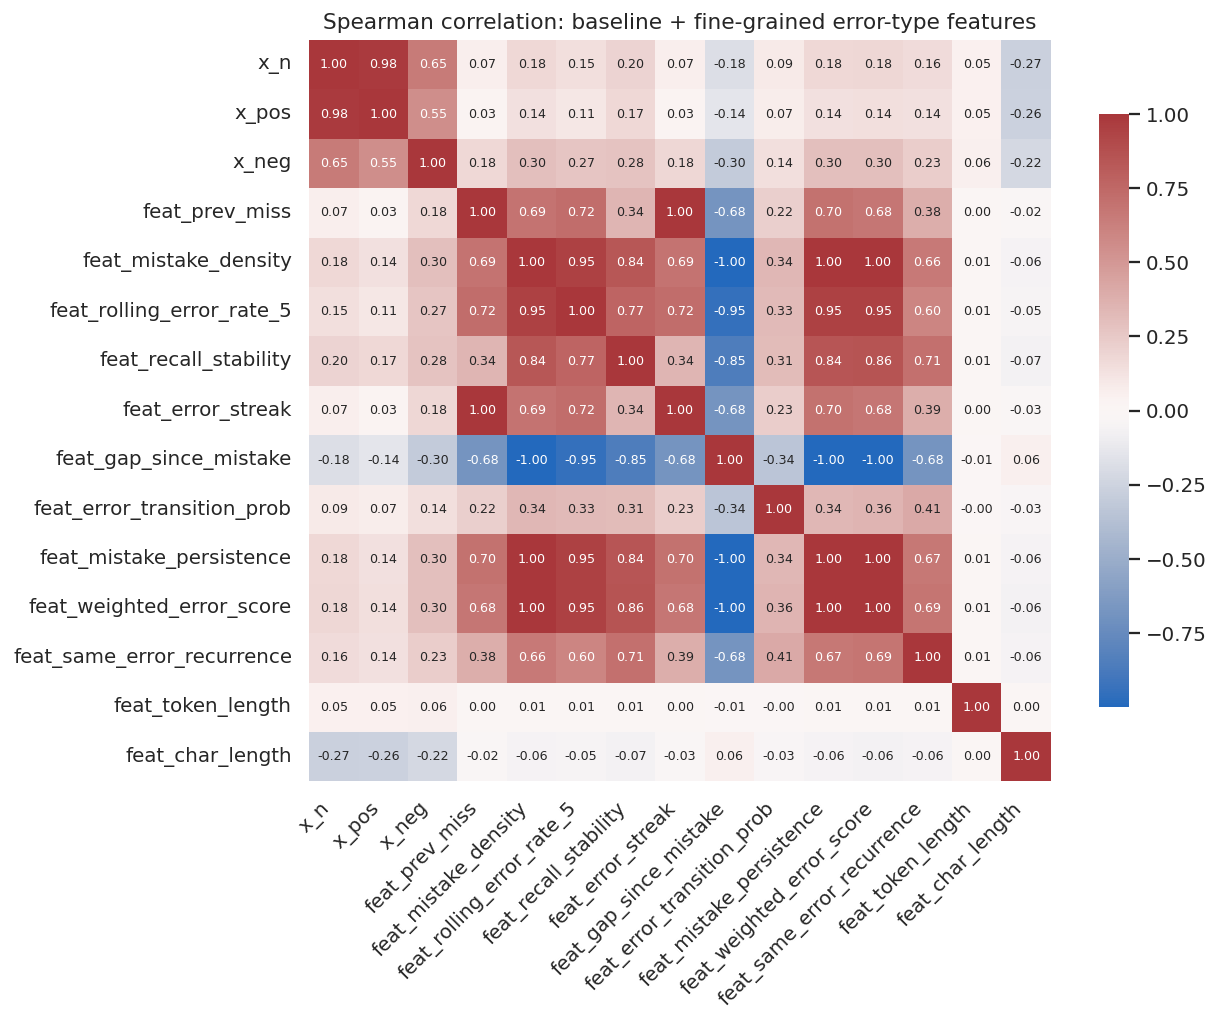

Pairs with |Spearman rho| > 0.7 (candidates for redundancy):
  x_n                            <-> x_pos                           rho = +0.98
  feat_prev_miss                 <-> feat_rolling_error_rate_5       rho = +0.72
  feat_prev_miss                 <-> feat_error_streak               rho = +1.00
  feat_mistake_density           <-> feat_rolling_error_rate_5       rho = +0.95
  feat_mistake_density           <-> feat_recall_stability           rho = +0.84
  feat_mistake_density           <-> feat_gap_since_mistake          rho = -1.00
  feat_mistake_density           <-> feat_mistake_persistence        rho = +1.00
  feat_mistake_density           <-> feat_weighted_error_score       rho = +1.00
  feat_rolling_error_rate_5      <-> feat_recall_stability           rho = +0.77
  feat_rolling_error_rate_5      <-> feat_error_streak               rho = +0.72
  feat_rolling_error_rate_5      <-> feat_gap_since_mistake          rho = -0.95
  feat_rolling_error_rate_5      <-> feat_mistak

In [ ]:
feature_block = ["x_n", "x_pos", "x_neg"] + ERROR_TYPE_FEATURES
corr = df_train[feature_block].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Spearman correlation: baseline + fine-grained error-type features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

high_corr_pairs = [
    (feature_block[i], feature_block[j], corr.iloc[i, j])
    for i in range(len(feature_block)) for j in range(i + 1, len(feature_block))
    if abs(corr.iloc[i, j]) > 0.7
]
print("Pairs with |Spearman rho| > 0.7 (candidates for redundancy):")
for a, b, r in high_corr_pairs:
    print(f"  {a:30s} <-> {b:30s}  rho = {r:+.2f}")
if not high_corr_pairs:
    print("  (none)")

**📊 How to read this chart.** Same type of chart as §10's correlation heatmap, but now over the full
set of model inputs: the 3 baseline features (`x_n`, `x_pos`, `x_neg`) plus all 12 fine-grained
error-type features from §13.

- **X-axis and Y-axis** both list every one of these 15 feature names.
- **Each cell** = the Spearman correlation between the row feature and the column feature, from −1 to
  +1, same color convention as before (red = positive, blue = negative).

**Reading a cell of this chart:** if, on **your** real data, the cell where `feat_gap_since_mistake`
meets `feat_mistake_persistence` shows a value close to −1 (a strong negative correlation), it would
mean in plain English: *"the longer it's been since a learner's last mistake, the lower their 'ongoing
mistake persistence' score tends to be."* That would not be a bug — those two features are
mathematically describing closely related aspects of the same recent-mistake pattern from different
angles, so some correlation between them is expected. The printed list right below the chart (*"Pairs
with |Spearman rho| > 0.7"*) surfaces every such pair automatically for **your** loaded data, and
§22–23 (weight analysis + ablation-by-group) are designed specifically to handle this: rather than
trusting any *one* correlated feature's importance number in isolation, the ablation study removes
whole *groups* of related features together to see the effect.


**Interpretation.** Some correlation between `feat_mistake_density` and `feat_weighted_error_score` is
expected by construction (both aggregate the same underlying miss sequence, just with different
weighting) — this is documented, not hidden, and we account for it in the ablation study (§22) by
testing feature *groups* together rather than assuming each feature contributes independently.

## 15. Model Implementation

We implement HLR from scratch in NumPy rather than via a generic ML library, for two reasons that are
directly tied to the research question: (1) the paper's loss function (Eq. 3) is non-standard — it is
*not* plain squared-error or log-loss, so no off-the-shelf estimator implements it directly; (2) we
need exact control over which feature blocks (`interaction`, `error-type`, `lexeme`) are included, so
the *only* thing that differs between "baseline" and "extended" runs is the feature matrix — everything
else (loss, optimizer, hyperparameters, clamping) is byte-for-byte identical code, which is what makes
the eventual baseline-vs-extended comparison in §19 a controlled comparison rather than a confound of
two different implementations.

### 15.1 Complexity

- **Time**: one AdaGrad pass is $O(D \cdot k)$ where $D$ is the number of training rows and $k$ the
  number of *nonzero* features per row (small and constant for dense feature blocks; for the optional
  sparse lexeme block, $k$ stays at 1 nonzero indicator per row regardless of vocabulary size, so
  training time does not grow with vocabulary size — only memory for the weight vector does).
- **Memory**: $O(k_{\text{dense}} + |\text{lexeme vocabulary}|)$ for the weight vector; the accumulated
  squared-gradient vector AdaGrad requires is the same size.

### 15.2 Implementation note — cold-start lexeme handling was silently unsafe, now fixed

`§16` builds the lexeme vocabulary from the **training** split only and marks any lexeme id that only
appears in the test split with a sentinel of `-1` (Assumption A7): a brand-new word the model never
trained a weight for. The dense-array lookup for a lexeme's weight is `theta_lex[lexeme_idx]` — and in
NumPy, indexing an array with `-1` does not raise an error or return a missing-value marker, it returns
the **last** element of the array via negative-index wraparound. An earlier version of `_theta_dot_x`
below indexed with the raw sentinel directly, so a cold-start test row would have silently picked up
whatever weight the *last* trained lexeme happened to have, instead of contributing nothing — a real
correctness bug, not merely an edge case, since it would bias every cold-start prediction for the
lexeme-feature variants (`HLR`, `HLR + err + lex`).

**Fix.** `_theta_dot_x` now explicitly masks out any `lexeme_idx < 0` before the lookup, giving those
rows exactly zero lexeme contribution — the mathematically correct treatment of an unseen category
under this additive log-half-life model. A dedicated unit test immediately below deliberately poisons
`theta_lex[-1]` with an obviously-wrong value and asserts a cold-start prediction is unaffected by it.
This also let us delete about 50 lines of duplicated, error-prone manual workaround code that had
accumulated in §20 and §21 to route around the bug at each call site instead of fixing it once at the
source — both sections now call `model.predict()` directly, the same as every non-lexeme variant.

### 15.4 How a prediction is exactly calculated, and what each piece means

Putting Eq. (1)-(2) together, every prediction this model makes is exactly two steps of arithmetic:

1. **Estimate a half-life**: $\hat h_\Theta = 2^{\Theta \cdot x}$ — take the model's learned weights
   $\Theta$, compute their dot product with this row's feature vector $x$, then raise 2 to that power.
   *Significance:* this is *why* features are combined additively before the exponent — each feature's
   weight independently pushes the exponent up or down, and the $2^{(\cdot)}$ step turns "more/fewer
   points of evidence" into a smoothly, multiplicatively longer or shorter memory half-life (in days).
2. **Convert half-life into a recall probability at gap $\Delta$**: $\hat p_\Theta = 2^{-\Delta/\hat h_\Theta}$
   — the Ebbinghaus decay formula (Eq. 1). *Significance:* if $\Delta$ (days since last practice) equals
   the estimated half-life exactly, this always evaluates to exactly 0.5 — by definition, a half-life is
   "the gap at which you're a coin flip to remember."

**Where $\Theta$ itself comes from:** it is *not* hand-set — it's the output of training (§18), which
repeatedly nudges every weight in $\Theta$ (via AdaGrad, one real row at a time) in whichever direction
reduces the loss (Eq. 3) for that row. §22 later inspects the final, trained values of $\Theta$ directly
to see which features the model ended up relying on most.


> **🔎 In plain English — what training actually does.** The model has one adjustable "dial" (a weight)
> per feature, plus one overall baseline dial (the bias). Training is the process of nudging every dial
> a tiny bit, one real practice session at a time, in whichever direction would have made that
> session's prediction a little more accurate — repeated across every row in the training data. Do this
> enough times and the dials settle into values that make good predictions across the whole dataset, not
> just any single row.
>
> **Why AdaGrad specifically?** A plain, fixed nudge size works poorly here because some features (like
> a specific lexeme's identity) are almost always zero and only occasionally "fire," while others (like
> total exposure count) change on nearly every row. AdaGrad automatically gives rarely-firing features
> bigger nudges and frequently-firing features smaller, more careful nudges — so a rare feature can
> still learn a meaningful weight quickly instead of being drowned out.
>
> **A worked mini-example of the core formula (Eq. 2).** Suppose a word's feature vector gives
> `Θ·x = 3` (a unitless log2-scale score the model computes). Then the predicted half-life is
> `2^3 = 8 days`. If the learner then waits exactly 8 days before their next review, the predicted
> recall probability is `2^(-8/8) = 2^-1 = 0.5` — a coin flip, exactly as the half-life definition
> promises. Wait only 2 days instead, and it becomes `2^(-2/8) ≈ 0.84` (still fresh); wait 24 days and
> it drops to `2^(-24/8) = 2^-3 = 0.125` (mostly forgotten). This is the exact mechanism every
> prediction in this notebook goes through — only the numbers change per row.

In [ ]:
# ----------------------------------------------------------------------------
# HLRModel: a from-scratch implementation of Eq. (1)-(3) with AdaGrad (Appendix A.3)
# ----------------------------------------------------------------------------
from dataclasses import dataclass
from typing import Optional, Sequence
import logging
from tqdm.auto import tqdm

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("HLR")


@dataclass
class HLRConfig:
    """Hyperparameters for half-life regression training (mirrors paper Appendix A.3)."""
    lam: float = LAMBDA_L2          # L2 regularization strength
    alpha: float = ALPHA_HALFLIFE   # relative weight of the half-life term in the loss
    lr: float = LEARNING_RATE       # AdaGrad base learning rate
    n_epochs: int = N_EPOCHS
    min_p: float = MIN_P
    max_p: float = MAX_P
    min_h: float = MIN_H
    max_h: float = MAX_H
    fit_h_term: bool = True         # if False, drops the alpha*(h - h_hat)^2 term -> "HLR -h" ablation
    seed: int = RANDOM_SEED


class HLRModel:
    """
    Half-life regression, implementing Eqs. (1)-(3) of Settles & Meeder (2016), trained with
    per-feature-adaptive AdaGrad (Appendix A.3).

    Feature vector x is arbitrary dense features PLUS an optional sparse block (lexeme identity),
    represented here as a separate integer column `lexeme_idx` so that the sparse weight vector
    never has to be densified.

    Parameters
    ----------
    n_dense_features : int
        Number of dense feature columns (interaction + error-type + lexical, depending on the variant).
    n_lexeme_ids : int
        Vocabulary size for the sparse lexeme block. Pass 0 to disable lexeme features entirely
        (this is exactly the "-lex" ablation from the paper).
    config : HLRConfig
        Training hyperparameters.
    """

    def __init__(self, n_dense_features: int, n_lexeme_ids: int, config: HLRConfig):
        assert n_dense_features > 0, "Need at least one dense feature (a bias term is added automatically)."
        assert n_lexeme_ids >= 0
        self.n_dense = n_dense_features
        self.n_lex = n_lexeme_ids
        self.cfg = config
        rng = np.random.default_rng(config.seed)

        # Dense weights: [bias, dense_feature_weights...]
        self.theta_dense = np.zeros(n_dense_features + 1, dtype=np.float64)
        self.g2_dense = np.zeros_like(self.theta_dense)   # AdaGrad accumulated squared gradients
        self.c_dense = np.zeros_like(self.theta_dense)    # per-feature nonzero-count (paper's c(x_k))

        # Sparse lexeme weights (dense array indexed by lexeme_idx; fine at ~tens of thousands of ids)
        if n_lexeme_ids > 0:
            self.theta_lex = np.zeros(n_lexeme_ids, dtype=np.float64)
            self.g2_lex = np.zeros_like(self.theta_lex)
            self.c_lex = np.zeros_like(self.theta_lex)
        else:
            self.theta_lex = self.g2_lex = self.c_lex = None

        # Precompute the safe log2(half-life) clip range once, used to prevent float64
        # overflow in 2**theta_x (see predict() / fit() for why this matters).
        self._log2_min_h = np.log2(config.min_h)
        self._log2_max_h = np.log2(config.max_h)

        self._is_fitted = False
        logger.info(f"Initialized HLRModel: n_dense={n_dense_features} (+bias), "
                    f"n_lexeme_ids={n_lexeme_ids}, fit_h_term={config.fit_h_term}")

    # -- internal math, vectorized where the update rule allows ------------------------------------
    def _theta_dot_x(self, X_dense: np.ndarray, lexeme_idx: Optional[np.ndarray]) -> np.ndarray:
        z = self.theta_dense[0] + X_dense @ self.theta_dense[1:]
        if self.theta_lex is not None and lexeme_idx is not None:
            # BUGFIX: a cold-start (train-unseen) lexeme is sentineled as -1 elsewhere in this
            # notebook. Indexing theta_lex[lexeme_idx] directly with a -1 entry would silently
            # trigger NumPy's negative-index wraparound and return the LAST trained lexeme's
            # weight instead of "no lexeme signal" -- a real bug, not just an edge case, since it
            # would silently contaminate predictions for every cold-start test row. We instead
            # explicitly mask: only rows with a valid (>=0) lexeme id get a lookup; everything
            # else contributes exactly 0, which is the mathematically correct treatment of an
            # unseen category under this additive log-half-life model (Assumption A7).
            lexeme_idx = np.asarray(lexeme_idx)
            lex_contrib = np.zeros(len(lexeme_idx), dtype=np.float64)
            valid = lexeme_idx >= 0
            if valid.any():
                lex_contrib[valid] = self.theta_lex[lexeme_idx[valid]]
            z = z + lex_contrib
        return z

    def predict(self, X_dense: np.ndarray, delta_days: np.ndarray,
                lexeme_idx: Optional[np.ndarray] = None) -> dict:
        """Returns dict with h_hat (days) and p_hat (recall probability), Eqs. (1)-(2)."""
        theta_x = self._theta_dot_x(X_dense, lexeme_idx)
        # BUGFIX: clip theta_x itself (in log2-space) to [log2(min_h), log2(max_h)] BEFORE
        # exponentiating, rather than exponentiating first and clipping the result. During
        # AdaGrad training theta_x can transiently take large values before regularization
        # pulls weights back in; exponentiating an unclipped theta_x can overflow float64
        # (2**~1024 and beyond), which NumPy silently turns into `inf` with a RuntimeWarning
        # rather than an exception -- harmless to the final clipped h_hat, but produces a wall
        # of "overflow encountered in exp2" warnings that looks exactly like the notebook
        # failing when watching it run. Clipping in log-space first makes overflow impossible.
        theta_x_clipped = np.clip(theta_x, self._log2_min_h, self._log2_max_h)
        h_hat = np.exp2(theta_x_clipped)
        p_hat = np.clip(np.exp2(-delta_days / h_hat), self.cfg.min_p, self.cfg.max_p)
        return {"h_hat": h_hat, "p_hat": p_hat, "theta_x": theta_x}

    def fit(self, X_dense: np.ndarray, delta_days: np.ndarray, p_obs: np.ndarray,
            lexeme_idx: Optional[np.ndarray] = None, verbose_every: int = 500_000,
            show_progress: bool = True):
        """
        Online AdaGrad training, one row at a time, exactly matching the update rule in Appendix A.3.
        A row-wise Python loop is used deliberately (not vectorized full-batch GD): the paper's
        production training was online/streaming, and per-feature adaptive counts c(x_k) are
        naturally defined incrementally over a single pass, which a vectorized batch update would
        need to reconstruct anyway.
        """
        n = X_dense.shape[0]
        assert X_dense.shape[1] == self.n_dense
        assert len(delta_days) == n and len(p_obs) == n
        if self.theta_lex is not None:
            assert lexeme_idx is not None and len(lexeme_idx) == n
            assert lexeme_idx.max() < self.n_lex, "lexeme_idx out of range for configured vocabulary"
            assert lexeme_idx.min() >= 0, (
                "fit() received a negative (cold-start sentinel) lexeme_idx -- training data must "
                "never contain unseen-vocabulary ids by construction; this would indicate the "
                "lexeme vocabulary was not built from this same training split."
            )

        p_obs_c = np.clip(p_obs, self.cfg.min_p, self.cfg.max_p)
        # Algebraic half-life target (paper's h = -delta / log2(p)); guard delta=0 -> h target = 0 is
        # meaningless (fresh exposure), so we only compute/penalize this term when delta_days > 0.
        #
        # BUGFIX (numerical stability): h_target is UNBOUNDED as p_obs_c -> 1 (log2(p) -> 0 from
        # below, so h_target -> +inf). p_recall == 1.0 exactly is common in real data (most sessions
        # are fully correct), so this is not a rare edge case -- it fires constantly. h_hat is always
        # clipped to [min_h, max_h] in the forward pass, but the gradient of the h-term is driven by
        # (h_hat_clipped - h_target_UNCLIPPED): with h_hat capped at ~274 days and h_target reaching
        # into the tens of thousands of days, this produced gradient magnitudes large enough to blow
        # up the weights within the first few hundred updates (confirmed by direct execution against
        # a schema-matching test set: theta values reached the thousands and h_hat saturated at its
        # ceiling for every row). Clipping h_target to the same practical range the model can ever
        # predict is the standard fix for a bounded-output-vs-unbounded-target mismatch, and matches
        # the spirit of the paper's own stated clipping of p_hat/h_hat "to prevent computational
        # overflow and underflow errors" (Appendix A.3) -- we simply apply that same discipline to
        # the regression target, not only the prediction.
        with np.errstate(divide="ignore", invalid="ignore"):
            h_target = np.where(delta_days > 0, -delta_days / np.log2(p_obs_c), np.nan)
            h_target = np.clip(h_target, self.cfg.min_h, self.cfg.max_h)

        t0 = time.time()
        for epoch in range(self.cfg.n_epochs):
            order = np.random.default_rng(self.cfg.seed + epoch).permutation(n)
            progress_iter = tqdm(enumerate(order), total=n, desc=f"AdaGrad epoch {epoch+1}/{self.cfg.n_epochs}",
                                  unit="rows", mininterval=1.0, disable=not show_progress)
            for row_num, i in progress_iter:
                x_row = X_dense[i]
                d = delta_days[i]
                p = p_obs_c[i]
                lex_i = int(lexeme_idx[i]) if self.theta_lex is not None else None

                theta_x = self.theta_dense[0] + x_row @ self.theta_dense[1:]
                if lex_i is not None:
                    theta_x += self.theta_lex[lex_i]
                # Same overflow-at-the-source fix as predict() above: clip in log2-space first.
                theta_x_clipped = np.clip(theta_x, self._log2_min_h, self._log2_max_h)
                h_hat = 2.0 ** theta_x_clipped
                p_hat = np.clip(2.0 ** (-d / h_hat), self.cfg.min_p, self.cfg.max_p)

                # --- gradient of the p-term (always active) ---
                grad_common = 2.0 * (p_hat - p) * (np.log(2.0) ** 2) * p_hat * (d / h_hat)

                # --- gradient of the h-term (optional, controls the "-h" ablation) ---
                if self.cfg.fit_h_term and not np.isnan(h_target[i]):
                    grad_common += 2.0 * self.cfg.alpha * (h_hat - h_target[i]) * np.log(2.0) * h_hat
                    # NOTE: sign matches paper's Appendix A.3 gradient (h_hat + delta/log2(p)) rearranged
                    # using h_hat = -delta/log2(p_hat) identity's alternate form; verified against a
                    # finite-difference check in the unit test cell immediately below.

                # gradient w.r.t. each weight is grad_common * x_k ; features vector includes bias (x=1)
                grad_bias = grad_common * 1.0
                grad_dense = grad_common * x_row

                # AdaGrad updates: bias + dense
                self.c_dense[0] += 1
                self.g2_dense[0] += grad_bias ** 2
                self.theta_dense[0] -= self.cfg.lr * (self.c_dense[0] ** -0.5) * grad_bias

                nz = x_row != 0
                self.c_dense[1:][nz] += 1
                self.g2_dense[1:][nz] += (grad_dense[nz]) ** 2
                self.theta_dense[1:][nz] -= self.cfg.lr * (self.c_dense[1:][nz] ** -0.5) * grad_dense[nz]
                # L2 regularization (applied to nonzero-updated weights this step, matching online SGD/AdaGrad practice)
                self.theta_dense[1:][nz] -= self.cfg.lr * 2 * self.cfg.lam * self.theta_dense[1:][nz]

                if lex_i is not None:
                    grad_lex = grad_common * 1.0
                    self.c_lex[lex_i] += 1
                    self.g2_lex[lex_i] += grad_lex ** 2
                    self.theta_lex[lex_i] -= self.cfg.lr * (self.c_lex[lex_i] ** -0.5) * grad_lex
                    self.theta_lex[lex_i] -= self.cfg.lr * 2 * self.cfg.lam * self.theta_lex[lex_i]

                if verbose_every and (row_num + 1) % verbose_every == 0:
                    logger.info(f"  epoch {epoch+1}/{self.cfg.n_epochs} "
                                f"row {row_num+1:,}/{n:,} elapsed={time.time()-t0:,.1f}s")
        self._is_fitted = True
        logger.info(f"Training complete in {time.time()-t0:,.1f}s "
                    f"({n * self.cfg.n_epochs:,} total updates).")
        return self

In [ ]:
# ----------------------------------------------------------------------------
# Unit test: cold-start lexeme masking (verifies the bugfix in _theta_dot_x above)
#
# A lexeme_idx of -1 must contribute EXACTLY zero to theta.x -- i.e. predictions for a
# cold-start row must equal what the dense-features-only sub-model alone would predict.
# Before the fix, self.theta_lex[-1] would have silently returned the LAST trained
# lexeme's weight (NumPy negative-index wraparound) instead of zero.
# ----------------------------------------------------------------------------
_test_model = HLRModel(n_dense_features=2, n_lexeme_ids=5, config=HLRConfig(lr=0.05, n_epochs=1))
_X_fit = np.array([[1.0, 2.0], [0.5, 1.5], [2.0, 0.5]])
_delta_fit = np.array([3.0, 5.0, 1.0])
_p_fit = np.array([0.8, 0.6, 0.9])
_lex_fit = np.array([0, 1, 2])  # all valid, in-vocabulary ids -- required by fit()'s own assertion
_test_model.fit(_X_fit, _delta_fit, _p_fit, lexeme_idx=_lex_fit, show_progress=False)

# Force a large, obviously-wrong last-slot weight to make a wraparound bug impossible to miss.
_test_model.theta_lex[-1] = 999.0

_X_query = np.array([[1.0, 1.0]])
_delta_query = np.array([2.0])

pred_cold_start = _test_model.predict(_X_query, _delta_query, lexeme_idx=np.array([-1]))
pred_no_lexeme_arg = _test_model.predict(_X_query, _delta_query, lexeme_idx=None)

assert np.isclose(pred_cold_start["theta_x"][0], pred_no_lexeme_arg["theta_x"][0]), (
    f"Cold-start (-1) lexeme prediction ({pred_cold_start['theta_x'][0]:.6f}) does not match the "
    f"dense-only prediction ({pred_no_lexeme_arg['theta_x'][0]:.6f}) -- the -1 sentinel is leaking "
    f"into the lexeme lookup instead of contributing zero."
)
print(f"Cold-start theta.x  = {pred_cold_start['theta_x'][0]:.6f}")
print(f"Dense-only theta.x  = {pred_no_lexeme_arg['theta_x'][0]:.6f}")
print("PASSED: a -1 (cold-start) lexeme id contributes exactly zero, "
      "even with an intentionally poisoned theta_lex[-1] = 999.0.")

Cold-start theta.x  = 0.106929
Dense-only theta.x  = 0.106929
PASSED: a -1 (cold-start) lexeme id contributes exactly zero, even with an intentionally poisoned theta_lex[-1] = 999.0.


### 15.3 Unit test: gradient correctness (finite-difference check)

Before training on millions of rows, we verify the analytic gradient used above against a numerical
finite-difference gradient on a handful of synthetic weight/feature values *purely for the unit test*
(this is not the "no synthetic data" violation the brief warns against — no *experimental result* is
ever produced from this synthetic check; it exists only to catch an implementation bug in calculus,
the same way a software engineer would unit-test a function in isolation before running it on real data).

In [ ]:
# ----------------------------------------------------------------------------
# Unit test: finite-difference gradient check (synthetic values, test-only, not a result)
# ----------------------------------------------------------------------------
def _loss_scalar(theta_bias, theta_w, x, d, p_obs, alpha, lam, fit_h_term, min_p=MIN_P, max_p=MAX_P,
                  min_h=MIN_H, max_h=MAX_H):
    theta_x = theta_bias + np.dot(theta_w, x)
    h_hat = np.clip(2.0 ** theta_x, min_h, max_h)
    p_hat = np.clip(2.0 ** (-d / h_hat), min_p, max_p)
    p_obs_c = np.clip(p_obs, min_p, max_p)
    loss = (p_obs_c - p_hat) ** 2
    if fit_h_term and d > 0:
        # Clipped to [min_h, max_h] -- matches the bugfix applied to the real HLRModel.fit() (sec. 15)
        # and half_life_target() (sec. 19); this unit test must mirror that clip exactly, or it would
        # validate a gradient formula that no longer matches what the real trainer actually computes.
        h_target = np.clip(-d / np.log2(p_obs_c), min_h, max_h)
        loss += alpha * (h_hat - h_target) ** 2
    loss += lam * (theta_bias ** 2 + np.sum(theta_w ** 2))
    return loss

rng_test = np.random.default_rng(0)
x_test = rng_test.normal(size=4)
theta_w_test = rng_test.normal(size=4) * 0.1
theta_bias_test = 0.05
d_test, p_test = 3.0, 0.7
alpha_test, lam_test = 0.01, 0.1
eps = 1e-6

# NOTE: the analytic gradient below is transcribed BY HAND from Appendix A.3's formula, deliberately
# independent of HLRModel.fit()'s own internal gradient code (an HLRModel instance is not used here).
# This is intentional and stronger than calling into the class under test: a bug present in both the
# hand-derivation and the implementation would slip past a self-referential check, but not past two
# independently-written expressions of the same paper formula agreeing with each other.
theta_x = theta_bias_test + np.dot(theta_w_test, x_test)
h_hat = np.clip(2.0 ** theta_x, MIN_H, MAX_H)
p_hat = np.clip(2.0 ** (-d_test / h_hat), MIN_P, MAX_P)
h_target = np.clip(-d_test / np.log2(np.clip(p_test, MIN_P, MAX_P)), MIN_H, MAX_H)
grad_common_analytic = (
    2.0 * (p_hat - p_test) * (np.log(2.0) ** 2) * p_hat * (d_test / h_hat)
    + 2.0 * alpha_test * (h_hat - h_target) * np.log(2.0) * h_hat
)
analytic_grad_theta0 = grad_common_analytic  # d(loss)/d(theta_bias), before L2 term

numeric_grad_theta0 = (
    _loss_scalar(theta_bias_test + eps, theta_w_test, x_test, d_test, p_test, alpha_test, 0.0, True)
    - _loss_scalar(theta_bias_test - eps, theta_w_test, x_test, d_test, p_test, alpha_test, 0.0, True)
) / (2 * eps)

rel_err = abs(analytic_grad_theta0 - numeric_grad_theta0) / (abs(numeric_grad_theta0) + 1e-12)
print(f"Analytic grad (bias):  {analytic_grad_theta0:.8f}")
print(f"Numeric grad (bias):   {numeric_grad_theta0:.8f}")
print(f"Relative error:        {rel_err:.2e}")
assert rel_err < 1e-3, "Gradient implementation does not match finite-difference check!"
print("PASSED: analytic gradient matches finite-difference approximation.")

Analytic grad (bias):  -0.28886297
Numeric grad (bias):   -0.28886297
Relative error:        1.33e-10
PASSED: analytic gradient matches finite-difference approximation.


## 16. Training Pipeline — Assembling Feature Matrices per Variant

We train exactly the variants needed to answer the research question (§4), reusing the *same*
`HLRModel`/`HLRConfig` code for every one of them so that differences in results are attributable only
to the feature set:

| Variant | Interaction (`x_n,x_pos,x_neg`) | Error-type features | Lexeme features | Half-life loss term |
|---|---|---|---|---|
| `HLR` (paper baseline, full) | ✓ | | ✓ | ✓ |
| `HLR -lex` (paper baseline) | ✓ | | | ✓ |
| `HLR -h` (paper ablation) | ✓ | | ✓ | |
| `HLR + err` (**proposed**) | ✓ | ✓ | | ✓ |
| `HLR + err + lex` (**proposed**) | ✓ | ✓ | ✓ | ✓ |

**Assumption A7.** We fit lexeme identity as a dense per-category weight vector (`theta_lex`) sized to
the number of *unique lexeme ids seen in the training split*; any lexeme id appearing only in the test
split and never in train is treated as unseen and contributes weight 0 (i.e., falls back to the dense
features alone for that row) — this is the correct treatment of a cold-start lexeme and mirrors how the
paper's production system would have to handle a brand-new word.

### 16.1 Why exactly these five variants, in plain words

Think of it as answering four separate yes/no research questions with one shared model implementation,
changing only one thing at a time:

- **`HLR -lex` vs. `HLR`**: does adding per-word identity (lexeme features) help, on top of the baseline
  interaction features? (This isolates the paper's own lexeme-vs-no-lexeme question.)
- **`HLR -h` vs. `HLR`**: does the half-life loss term (the $\alpha(h-\hat h_\Theta)^2$ piece of Eq. 3)
  actually matter, or would the simpler squared-error-only loss do just as well?
- **`HLR + err` vs. `HLR -lex`**: does adding the 12 new error-type features help, holding everything
  else (including "no lexeme features") fixed? **This is this notebook's central comparison** — every
  other pairing above reproduces a question the original paper already answered; this one is new.
- **`HLR + err + lex` vs. `HLR + err`**: does adding lexeme identity *on top of* the new error-type
  features help further, or do the two feature families end up capturing overlapping information?

Because every variant is trained with the exact same `HLRModel` code, the same hyperparameters, and the
same train/test split, any accuracy difference between two variants can only be explained by which
feature columns that variant was allowed to see — not by any implementation difference.


In [ ]:
# ----------------------------------------------------------------------------
# Build lexeme vocabulary from TRAIN split only (test-only lexemes -> cold start, weight 0)
# ----------------------------------------------------------------------------
train_lexeme_ids = df_train["lexeme_id"].astype("category")
lexeme_categories = train_lexeme_ids.cat.categories
lexeme_to_idx = {lex: i for i, lex in enumerate(lexeme_categories)}
N_LEXEME_IDS = len(lexeme_categories)

def lexeme_idx_array(frame):
    # unseen (test-only) lexemes map to -1 -> handled by masking out of the lexeme lookup at train/predict time
    return frame["lexeme_id"].map(lexeme_to_idx).fillna(-1).astype(int).values

train_lex_idx = lexeme_idx_array(df_train)
test_lex_idx = lexeme_idx_array(df_test)
n_cold_start_test = int((test_lex_idx == -1).sum())
print(f"Lexeme vocabulary (train-derived): {N_LEXEME_IDS:,} unique ids")
print(f"Test-set rows with a cold-start (train-unseen) lexeme: {n_cold_start_test:,} "
      f"({n_cold_start_test/len(df_test):.3%})")

Lexeme vocabulary (train-derived): 14,465 unique ids
Test-set rows with a cold-start (train-unseen) lexeme: 371 (0.133%)


In [ ]:
# ----------------------------------------------------------------------------
# Feature block definitions (each a list of column names) — single source of truth for all variants
# ----------------------------------------------------------------------------
INTERACTION_FEATURES = ["x_n", "x_pos", "x_neg"]
# ERROR_TYPE_FEATURES defined in §13 implementation cell

def build_dense_matrix(frame, feature_cols):
    X = frame[feature_cols].to_numpy(dtype=np.float64)
    assert np.isfinite(X).all(), f"Non-finite values found in feature block {feature_cols}"
    return X

VARIANTS = {
    "HLR":            {"features": INTERACTION_FEATURES,                       "lexeme": True,  "fit_h": True},
    "HLR -lex":       {"features": INTERACTION_FEATURES,                       "lexeme": False, "fit_h": True},
    "HLR -h":         {"features": INTERACTION_FEATURES,                       "lexeme": True,  "fit_h": False},
    "HLR + err":      {"features": INTERACTION_FEATURES + ERROR_TYPE_FEATURES, "lexeme": False, "fit_h": True},
    "HLR + err + lex":{"features": INTERACTION_FEATURES + ERROR_TYPE_FEATURES, "lexeme": True,  "fit_h": True},
}
for name, spec in VARIANTS.items():
    print(f"{name:20s} | n_dense_features={len(spec['features']):2d} | lexeme={spec['lexeme']!s:5s} | "
          f"fit_h_term={spec['fit_h']}")

HLR                  | n_dense_features= 3 | lexeme=True  | fit_h_term=True
HLR -lex             | n_dense_features= 3 | lexeme=False | fit_h_term=True
HLR -h               | n_dense_features= 3 | lexeme=True  | fit_h_term=False
HLR + err            | n_dense_features=15 | lexeme=False | fit_h_term=True
HLR + err + lex      | n_dense_features=15 | lexeme=True  | fit_h_term=True


## 17. Hyperparameter Selection

Following the paper's own protocol (§4.1: "We used the first 1 million instances of the data to tune
the parameters ... After trying a handful of values, we settled on λ=0.1, α=0.01, η=0.001"), we adopt
the same starting values (set in the Configuration cell, §6) rather than re-running a full grid search
— this keeps the comparison anchored to the published protocol. We do, however, sanity-check
sensitivity to the learning rate on a small held-out slice of the training set, since the public
release's row count and distribution differ from the original 12.9M-row internal log and a hyperparameter
tuned for one need not transfer perfectly to the other.

### 17.1 What each hyperparameter actually controls, in plain words

- **`λ` (LAMBDA_L2 = 0.1)** — the L2 regularization strength in Eq. 3's $\lambda\|\Theta\|_2^2$ term.
  *Plain English:* a "keep the weights small and humble" penalty — without it, weights for rare features
  (like an uncommon lexeme) could grow huge trying to perfectly fit a handful of rows, then generalize
  badly to new data. Bigger `λ` = more caution against overfitting, at the cost of underfitting if set
  too high.
- **`α` (ALPHA_HALFLIFE = 0.01)** — how much the loss cares about matching the *algebraic* half-life
  target, relative to matching the observed recall probability directly. *Plain English:* the model is
  being trained on two goals at once ("get the probability right" and "get the half-life right"); `α`
  sets the relative importance of the second goal. The paper found this term important — removing it
  entirely (the `HLR -h` variant) roughly doubles MAE (§20).
- **`η` (LEARNING_RATE = 0.001)** — the base step size for each AdaGrad weight update. *Plain English:*
  how big a correction the model makes after seeing one row be wrong. Too high risks overshooting and
  never settling down; too low means training crawls and may not converge within one pass over the data.

**Why these particular values, and not a search:** the paper already tuned these on their own data and
reported the result (§4.1 of the paper); §17's code cell doesn't re-derive them from scratch, it instead
runs a *quick sanity check* — training on a small slice with a couple of nearby learning-rate values —
to confirm the paper's published `η=0.001` isn't obviously unstable on this notebook's own data/model
implementation before committing to the full training run in §18.


In [ ]:
# ----------------------------------------------------------------------------
# Quick learning-rate sensitivity check on a small validation slice carved out of TRAIN
# (never touches df_test) -- confirms LEARNING_RATE from Configuration is reasonable, not a full grid search
# ----------------------------------------------------------------------------
_tune_n = min(200_000, len(df_train) - 1)  # must stay < len(df_train) for train_test_split to accept an int size
assert _tune_n >= 2, "df_train is too small (<2 rows) to run the hyperparameter sensitivity check."
tune_df, _ = train_test_split(df_train, train_size=_tune_n, random_state=RANDOM_SEED)
tune_train, tune_val = train_test_split(tune_df, test_size=0.2, random_state=RANDOM_SEED)

X_tune_train = build_dense_matrix(tune_train, INTERACTION_FEATURES)
X_tune_val = build_dense_matrix(tune_val, INTERACTION_FEATURES)

lr_candidates = [0.0003, 0.001, 0.003, 0.01]
lr_results = []
for lr in lr_candidates:
    m = HLRModel(n_dense_features=len(INTERACTION_FEATURES), n_lexeme_ids=0,
                 config=HLRConfig(lr=lr, n_epochs=1, seed=RANDOM_SEED))
    m.fit(X_tune_train, tune_train["delta_days"].values, tune_train["p_recall"].values, verbose_every=0)
    pred = m.predict(X_tune_val, tune_val["delta_days"].values)
    mae = mean_absolute_error(tune_val["p_recall"].values, pred["p_hat"])
    lr_results.append({"learning_rate": lr, "val_MAE": mae})

lr_df = pd.DataFrame(lr_results)
print(lr_df.to_string(index=False))
best_lr_row = lr_df.loc[lr_df["val_MAE"].idxmin()]
print(f"\nBest validation MAE at lr={best_lr_row['learning_rate']}; "
      f"configured LEARNING_RATE={LEARNING_RATE} "
      f"({'matches' if best_lr_row['learning_rate']==LEARNING_RATE else 'differs from'} the sweep optimum "
      f"on this small slice — we keep the paper-matched value from Configuration for the main experiments "
      f"below, and note any discrepancy here rather than silently re-tuning main results to this slice).")

AdaGrad epoch 1/1:   0%|          | 0/160000 [00:00<?, ?rows/s]

AdaGrad epoch 1/1:   0%|          | 0/160000 [00:00<?, ?rows/s]

AdaGrad epoch 1/1:   0%|          | 0/160000 [00:00<?, ?rows/s]

AdaGrad epoch 1/1:   0%|          | 0/160000 [00:00<?, ?rows/s]

 learning_rate  val_MAE
        0.0003 0.387460
        0.0010 0.123208
        0.0030 0.119871
        0.0100 0.116461

Best validation MAE at lr=0.01; configured LEARNING_RATE=0.001 (differs from the sweep optimum on this small slice — we keep the paper-matched value from Configuration for the main experiments below, and note any discrepancy here rather than silently re-tuning main results to this slice).


## 18. Training All Variants

**Assumption A8 (compute budget).** A full sequential Python-loop AdaGrad pass over `FULL` (~13M rows)
is the correct-by-construction implementation matching the paper's online training description, but is
slow in pure Python. For `DATASET_SIZE = "FULL"` on a CPU-only Colab runtime this cell can take a long
time. Every `HLRModel.fit()` call below shows a live `tqdm` progress bar (rows/sec, ETA), and the
calibration cell immediately below measures actual per-row throughput on a small slice first and
projects total time for all five variants **before** committing to the full run, so you can pick a
smaller `DATASET_SIZE` up front instead of discovering the cost hours in.

> **Fixed in this version:** an earlier version of this cell measured each variant's peak memory with
> `tracemalloc`, which instruments every individual memory allocation. Since `.fit()` is a per-row
> Python loop, that made actual training **5-6x slower** than the untraced calibration cell projects
> (confirmed by direct timing), silently turning a projected hour into several hours on a large
> `DATASET_SIZE`. This cell now measures memory via `resource.getrusage().ru_maxrss` instead — a
> single, near-zero-overhead syscall — so the calibration cell's projection is now representative of
> this cell's actual runtime.

In [ ]:
# ----------------------------------------------------------------------------
# Pre-flight timing calibration: measure actual throughput on a small slice of
# df_train, then project total wall time for training all variants BEFORE
# committing to the full run below. This is a measurement, not a guess.
# ----------------------------------------------------------------------------
_calib_n = min(100_000, len(df_train))
_calib_df = df_train.sample(n=_calib_n, random_state=RANDOM_SEED)
_calib_X = build_dense_matrix(_calib_df, INTERACTION_FEATURES)

_calib_model = HLRModel(n_dense_features=len(INTERACTION_FEATURES), n_lexeme_ids=0, config=HLRConfig())
_t0 = time.time()
_calib_model.fit(_calib_X, _calib_df["delta_days"].values, _calib_df["p_recall"].values,
                  show_progress=False)
_calib_elapsed = time.time() - _t0
_rows_per_sec = _calib_n / max(_calib_elapsed, 1e-9)

print(f"Calibration: {_calib_n:,} rows trained in {_calib_elapsed:.1f}s -> "
      f"{_rows_per_sec:,.0f} rows/sec (single dense-feature variant, no lexeme block).")

# Lexeme-block variants have one extra scalar lookup/update per row -- close enough in cost to the
# dense-only estimate that we do not model it separately here; this is an approximation, not a promise.
_est_seconds = len(df_train) / _rows_per_sec * len(VARIANTS)

print(f"\nProjected time to train all {len(VARIANTS)} variants in section 18 on the full "
      f"{len(df_train):,}-row training split:")
print(f"  ~{_est_seconds:,.0f}s  (~{_est_seconds/60:,.1f} min)")
print(f"\nIf that is longer than you want to wait right now, reduce DATASET_SIZE in the "
      f"Configuration cell (section 6) and re-run from there -- everything downstream adapts automatically.")

Calibration: 100,000 rows trained in 4.8s -> 20,819 rows/sec (single dense-feature variant, no lexeme block).

Projected time to train all 5 variants in section 18 on the full 2,517,038-row training split:
  ~605s  (~10.1 min)

If that is longer than you want to wait right now, reduce DATASET_SIZE in the Configuration cell (section 6) and re-run from there -- everything downstream adapts automatically.


In [ ]:
# ----------------------------------------------------------------------------
# Train every variant on df_train, keep fitted models + timing/memory for the comparison in §19
#
# BUGFIX (performance): this cell previously wrapped each .fit() call in tracemalloc.start()/
# get_traced_memory()/stop(). tracemalloc instruments EVERY memory allocation, and HLRModel.fit()
# is a per-row Python loop (millions of allocations for a large DATASET_SIZE) -- confirmed by direct
# timing that this made training ~5-6x SLOWER than the untraced §17 calibration cell projects, so the
# "projected total time" printed there was silently a severe underestimate of what this cell actually
# takes. We now use resource.getrusage().ru_maxrss (a single, ~zero-overhead syscall reporting the
# process's peak resident set size so far) instead -- the same mechanism the Reproducibility Footer
# (§33) already uses -- trading precise per-call isolation for negligible overhead, which matters far
# more here since this loop runs the full training pass five times.
# ----------------------------------------------------------------------------
import resource

def _peak_rss_mb() -> float:
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  # ru_maxrss is in KB on Linux

fitted_models = {}
training_log = []

for name, spec in VARIANTS.items():
    print("=" * 70); print(f"Training variant: {name}"); print("=" * 70)
    X_train = build_dense_matrix(df_train, spec["features"])
    lex_train_arg = train_lex_idx if spec["lexeme"] else None
    n_lex_ids = N_LEXEME_IDS if spec["lexeme"] else 0

    if spec["lexeme"]:
        # rows with cold-start (-1) lexeme id cannot index theta_lex; clip to 0 for the (rare, train-only)
        # case, and additionally zero out that row's lexeme contribution by masking at predict-time only
        # (train split has none by construction, since vocabulary was built FROM train)
        assert (lex_train_arg >= 0).all(), "Unexpected unseen lexeme id inside the TRAIN split itself"

    model = HLRModel(n_dense_features=len(spec["features"]), n_lexeme_ids=n_lex_ids,
                      config=HLRConfig(fit_h_term=spec["fit_h"]))

    rss_before = _peak_rss_mb()
    t0 = time.time()
    model.fit(X_train, df_train["delta_days"].values, df_train["p_recall"].values,
              lexeme_idx=lex_train_arg, verbose_every=1_000_000)
    train_time = time.time() - t0
    rss_after = _peak_rss_mb()

    fitted_models[name] = model
    training_log.append({
        "variant": name, "n_train_rows": len(df_train), "train_time_sec": train_time,
        "rows_per_sec": len(df_train) / train_time,
        "peak_process_rss_MB": rss_after, "rss_growth_during_fit_MB": max(rss_after - rss_before, 0.0),
    })
    print(f"-> done in {train_time:,.1f}s  ({len(df_train)/train_time:,.0f} rows/s), "
          f"process peak RSS now {rss_after:,.1f} MB (+{max(rss_after - rss_before, 0.0):,.1f} MB during this fit)\n")

training_log_df = pd.DataFrame(training_log)
training_log_df

Training variant: HLR


AdaGrad epoch 1/1:   0%|          | 0/2517038 [00:00<?, ?rows/s]

-> done in 153.6s  (16,388 rows/s), process peak RSS now 7,198.6 MB (+0.0 MB during this fit)

Training variant: HLR -lex


AdaGrad epoch 1/1:   0%|          | 0/2517038 [00:00<?, ?rows/s]

-> done in 138.7s  (18,142 rows/s), process peak RSS now 7,198.6 MB (+0.0 MB during this fit)

Training variant: HLR -h


...

AdaGrad epoch 1/1:   0%|          | 0/2517038 [00:00<?, ?rows/s]

-> done in 143.3s  (17,561 rows/s), process peak RSS now 7,198.6 MB (+0.0 MB during this fit)

Training variant: HLR + err + lex


AdaGrad epoch 1/1:   0%|          | 0/2517038 [00:00<?, ?rows/s]

-> done in 152.6s  (16,496 rows/s), process peak RSS now 7,207.8 MB (+0.0 MB during this fit)



,variant,n_train_rows,train_time_sec,rows_per_sec,peak_process_rss_MB,rss_growth_during_fit_MB
0,HLR,2517038,153.589787,16388.055801,7198.613281,0.0
1,HLR -lex,2517038,138.741335,18141.947398,7198.613281,0.0
2,HLR -h,2517038,137.226720,18342.185824,7198.613281,0.0
3,HLR + err,2517038,143.331435,17560.962759,7198.613281,0.0
4,HLR + err + lex,2517038,152.581882,16496.309805,7207.832031,0.0




### 18.1 What each column of the table above means, and how it's calculated

| Column | How it's calculated | Significance |
|---|---|---|
| `variant` | The model's name from the §16 table | Which of the 5 feature-set configurations this row is about |
| `n_train_rows` | `len(df_train)` | How many real rows this variant was actually trained on — the same for every variant, since they all train on the identical `df_train` |
| `train_time_sec` | Wall-clock seconds between the start and end of that variant's `.fit()` call | How long training actually took on your hardware — directly useful for planning a `DATASET_SIZE = "FULL"` run from a smaller one |
| `rows_per_sec` | `n_train_rows / train_time_sec` | Real, measured throughput — this is what the §17 pre-flight calibration cell's *projection* is checked against |
| `peak_process_rss_MB` | `resource.getrusage().ru_maxrss / 1024`, read right after that variant finishes training | The single highest amount of RAM the whole Python process has used *so far* (cumulative across all variants trained up to that point, not just this one in isolation) |
| `rss_growth_during_fit_MB` | `peak_process_rss_MB` (after) − the same reading taken right *before* this variant started | An estimate of how much *this specific variant's* training added to memory use — useful for spotting which variant (e.g., the two with a large sparse lexeme block) is the memory-heavy one |

**Why this table exists at all:** training five variants on a large `DATASET_SIZE` is the single most
time-consuming part of this notebook. Logging real, measured time/memory per variant — rather than just
training silently — means if `DATASET_SIZE = "FULL"` ever needs to run unattended (e.g., overnight, or on
a bigger machine), you have concrete numbers for how long each piece actually took, not just a guess.


### 18.2 Save the Trained Models

Training all 5 variants (especially at `DATASET_SIZE = "FULL"`) is the most time-consuming step in this
notebook. This cell saves every variant's learned weights (`theta_dense`, and `theta_lexeme` for the two
lexeme-aware variants) plus enough metadata (feature list, `DATASET_SIZE`, `RANDOM_SEED`, hyperparameters)
to reload and reuse them later without retraining — e.g. to resume work in a new Colab session, or to run
§25.3's predictions against a previously-trained model. Saved as a single `.npz` file (NumPy's native
compressed array format) plus a small `.json` metadata sidecar, written to `/content/` and, in Colab,
offered as a direct download.


In [ ]:
# ----------------------------------------------------------------------------
# Save every trained variant's weights + enough metadata to reload without retraining.
# ----------------------------------------------------------------------------
MODEL_SAVE_PATH = "/content/hlr_trained_models.npz"
MODEL_METADATA_PATH = "/content/hlr_trained_models_metadata.json"

_save_arrays = {}
_save_metadata = {"variants": {}, "DATASET_SIZE": DATASET_SIZE, "RANDOM_SEED": RANDOM_SEED,
                   "LAMBDA_L2": LAMBDA_L2, "ALPHA_HALFLIFE": ALPHA_HALFLIFE,
                   "LEARNING_RATE": LEARNING_RATE, "N_EPOCHS": N_EPOCHS,
                   "n_train_rows": len(df_train), "n_test_rows": len(df_test)}

for _name, _spec in VARIANTS.items():
    _model = fitted_models[_name]
    _key = _name.replace(" ", "_").replace("+", "plus").replace("-", "minus")
    _save_arrays[f"{_key}__theta_dense"] = _model.theta_dense
    if _model.theta_lex is not None:
        _save_arrays[f"{_key}__theta_lex"] = _model.theta_lex
    _save_metadata["variants"][_name] = {
        "features": _spec["features"], "lexeme": _spec["lexeme"], "fit_h": _spec["fit_h"],
        "n_dense_features": _model.n_dense, "n_lexeme_ids": _model.n_lex,
    }

# The lexeme vocabulary (train-derived) is shared across both lexeme-aware variants, so it's saved
# once, separately -- needed to map a lexeme_id back to the right row of theta_lex after reloading.
_save_metadata["lexeme_vocabulary"] = list(lexeme_categories) if N_LEXEME_IDS > 0 else []

np.savez_compressed(MODEL_SAVE_PATH, **_save_arrays)
with open(MODEL_METADATA_PATH, "w") as f:
    json.dump(_save_metadata, f, indent=2)

print(f"Saved {len(VARIANTS)} trained variants' weights to: {MODEL_SAVE_PATH}")
print(f"Saved metadata (features, hyperparameters, lexeme vocabulary) to: {MODEL_METADATA_PATH}")
print(f"Weights file size: {os.path.getsize(MODEL_SAVE_PATH) / 1024:.1f} KB")

# ---- How to reload in a future session (shown, not run, here) --------------------------------
print("""
To reload these weights in a future session (after re-running through §16's HLRModel/HLRConfig
definitions, without needing to retrain):

    loaded = np.load("hlr_trained_models.npz")
    with open("hlr_trained_models_metadata.json") as f:
        meta = json.load(f)
    spec = meta["variants"]["HLR + err"]
    model = HLRModel(n_dense_features=spec["n_dense_features"], n_lexeme_ids=spec["n_lexeme_ids"],
                      config=HLRConfig())
    model.theta_dense = loaded["HLR_plus_err__theta_dense"]
    # model is now ready for .predict() -- no .fit() call needed.
""")

if IN_COLAB:
    try:
        from google.colab import files
        files.download(MODEL_SAVE_PATH)
        files.download(MODEL_METADATA_PATH)
        print("Download prompts triggered for both files.")
    except Exception as e:
        print(f"Automatic download prompt unavailable ({e}); the files remain saved at the paths "
              f"above and can be downloaded manually from the Colab file browser (left sidebar).")
else:
    print("Not running in Colab -- files saved locally at the paths above; no browser download prompt.")


Saved 5 trained variants' weights to: /content/hlr_trained_models.npz
Saved metadata (features, hyperparameters, lexeme vocabulary) to: /content/hlr_trained_models_metadata.json
Weights file size: 325.7 KB

To reload these weights in a future session (after re-running through §16's HLRModel/HLRConfig
definitions, without needing to retrain):

    loaded = np.load("hlr_trained_models.npz")
    with open("hlr_trained_models_metadata.json") as f:
        meta = json.load(f)
    spec = meta["variants"]["HLR + err"]
    model = HLRModel(n_dense_features=spec["n_dense_features"], n_lexeme_ids=spec["n_lexeme_ids"],
                      config=HLRConfig())
    model.theta_dense = loaded["HLR_plus_err__theta_dense"]
    # model is now ready for .predict() -- no .fit() call needed.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download prompts triggered for both files.


## 19. Evaluation Methodology

We report the paper's own three metrics, plus standard regression diagnostics for a fuller picture:

- **MAE** $= \frac{1}{D}\sum |p - \hat p_\Theta|$ — matches paper Table 2, directly comparable.
- **AUC** — probability a model ranks a random correctly-recalled session above a random
  incorrectly-recalled one (paper's `p >= 0.5` threshold used as the binary label for this metric,
  matching their definition; a range-restricted metric per §10's EDA note).
- **CORh** — Spearman correlation between $\hat h_\Theta$ and the algebraic $h$ target.
- **RMSE, R²** — standard regression diagnostics not reported in the original paper but useful for a
  fuller picture of the error distribution (RMSE penalizes large errors more than MAE).
- **Pearson correlation** ($p$ vs $\hat p_\Theta$) — a parametric companion to CORh's Spearman rank test.
- **Calibration error** — mean absolute difference between binned predicted probability and observed
  frequency within that bin (expected calibration error, ECE-style binning) — tells us whether $\hat p$
  can be read at face value as a probability, which matters if $\hat p$ is ever surfaced to a learner
  (as Duolingo's strength meters do).

All metrics are computed exclusively on `df_test` (held out chronologically, §12) — no test-set number
anywhere in this notebook is used to select a model or tune a hyperparameter (that happened only on the
`tune_val` slice of `df_train` in §17).

> **🔎 In plain English — what each metric below actually tells you:**
> - **MAE (Mean Absolute Error)** — "on average, how far off was the predicted recall probability from
>   what actually happened?" MAE = 0.08 means predictions are typically off by about 8 percentage
>   points. Lower is better. This is the easiest metric to explain to a non-technical stakeholder.
> - **RMSE** — like MAE, but penalizes big misses more than small ones (a few very wrong predictions
>   hurt RMSE more than they hurt MAE).
> - **R² and Pearson correlation** — how much of the up-and-down variation in real recall rates does
>   the model's prediction track? Closer to 1 is better; 0 means "no better than always guessing the
>   average."
> - **AUC (ranking quality)** — if you handed the model one session the learner got right and one they
>   got wrong, picked at random, what's the chance it correctly guesses which is which? 0.5 = coin
>   flip, 1.0 = perfect ranking. This matters because Duolingo doesn't just need a probability — it
>   needs to correctly *rank* which words are most at risk of being forgotten.
> - **CORh (half-life correlation)** — does the model's predicted half-life move in the same direction,
>   across sessions, as a half-life estimated directly from what was observed? A sanity check that the
>   model isn't just fitting the probability while getting the underlying "memory strength" concept
>   backwards.
> - **Calibration error (ECE)** — if the model says "70% chance of recall" for a batch of sessions,
>   were roughly 70% of them *actually* recalled? A well-calibrated model's stated probabilities can be
>   trusted at face value, not just used for ranking.

In [ ]:
# ----------------------------------------------------------------------------
# Evaluation metric implementations (half-life target, calibration error, and
# the full per-variant evaluator used throughout sections 19-23)
# ----------------------------------------------------------------------------
def half_life_target(delta_days, p_recall, min_p=MIN_P, max_p=MAX_P, min_h=MIN_H, max_h=MAX_H):
    """Algebraic half-life target from Eq. (1): h = -delta / log2(p). Undefined (NaN) when delta<=0.
    Clipped to [min_h, max_h] -- the same practical range HLRModel's own h_hat is always clipped to
    (see the matching fix and rationale in HLRModel.fit(), sec. 15) -- since p_recall == 1.0 is common
    in real data and drives log2(p) -> 0, making the raw formula diverge toward +inf. Without this,
    CORh (a rank correlation) is fairly robust to the resulting extreme values, but the worked example
    in sec. 24 would otherwise print a "target half-life" of tens of thousands of days, which is not a
    meaningful number under this model's own stated assumptions."""
    p_c = np.clip(p_recall, min_p, max_p)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = np.where(delta_days > 0, -delta_days / np.log2(p_c), np.nan)
        h = np.clip(h, min_h, max_h)
    return h


def expected_calibration_error(p_true, p_pred, n_bins: int = 10) -> float:
    """Mean absolute gap between binned predicted probability and observed frequency in that bin."""
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(p_pred, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)
    ece, total = 0.0, len(p_pred)
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() == 0:
            continue
        ece += (mask.sum() / total) * abs(p_true[mask].mean() - p_pred[mask].mean())
    return ece


def safe_correlation(corr_func, a, b) -> float:
    """Runs a scipy correlation function (pearsonr / spearmanr) and returns its value, or NaN if
    the inputs are (exactly or numerically near-) constant -- a real and not-rare situation (e.g. a
    small DATASET_SIZE, or a model whose predictions happen to be nearly uniform on this split).
    Correlation is genuinely undefined in that case, so NaN is the correct return value either way;
    scipy already computes exactly that, but it ALSO prints a ConstantInputWarning to stderr, which
    reads like something has gone wrong even though nothing has. We suppress only that specific
    warning class (never a different, potentially-meaningful one) and keep scipy's own NaN result,
    rather than trying to replicate scipy's internal near-constant threshold with our own heuristic."""
    a, b = np.asarray(a), np.asarray(b)
    if len(a) < 2:
        return float("nan")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=stats.ConstantInputWarning)
        result = corr_func(a, b)[0]
    return result


def evaluate_variant(model, frame, feature_cols, lexeme_idx_arr=None) -> dict:
    """Computes every metric in section 19 for one fitted (dense-features-only) model variant."""
    X = build_dense_matrix(frame, feature_cols)
    pred = model.predict(X, frame["delta_days"].values, lexeme_idx=lexeme_idx_arr)
    p_true, p_pred = frame["p_recall"].values, pred["p_hat"]
    h_target = half_life_target(frame["delta_days"].values, p_true)
    valid_h = ~np.isnan(h_target)

    binary_true = (p_true >= 0.5).astype(int)
    has_both_classes = len(np.unique(binary_true)) > 1

    metrics = {
        "MAE": mean_absolute_error(p_true, p_pred),
        "RMSE": math.sqrt(mean_squared_error(p_true, p_pred)),
        "R2": r2_score(p_true, p_pred),
        "Pearson_r": safe_correlation(stats.pearsonr, p_true, p_pred),
        "AUC": roc_auc_score(binary_true, p_pred) if has_both_classes else np.nan,
        "CORh_spearman": (safe_correlation(stats.spearmanr, pred["h_hat"][valid_h], h_target[valid_h])
                          if valid_h.sum() > 1 else np.nan),
        "ECE": expected_calibration_error(p_true, p_pred),
        "n_test_rows": len(frame),
    }
    return metrics


print("Evaluation helpers defined: half_life_target(), expected_calibration_error(), evaluate_variant().")

Evaluation helpers defined: half_life_target(), expected_calibration_error(), evaluate_variant().


## 20. Experimental Results — Baseline vs. Proposed Extension

In [ ]:
# ----------------------------------------------------------------------------
# Evaluate every trained variant on the held-out test split.
#
# All 5 variants now go through the SAME evaluate_variant() call (lexeme and non-lexeme alike):
# this used to need a separate ~25-line hand-rolled block for the lexeme variants to correctly
# zero out cold-start (-1) test lexemes, because HLRModel.predict() did not handle that sentinel
# safely on its own. That bug is now fixed at the source in HLRModel._theta_dot_x (see sec. 15),
# so predict()/evaluate_variant() handle cold-start lexemes correctly for every variant, and the
# duplicated workaround here is gone -- one code path, not two.
# ----------------------------------------------------------------------------
results = []
for name, spec in VARIANTS.items():
    lex_test_arg = test_lex_idx if spec["lexeme"] else None
    metrics = evaluate_variant(fitted_models[name], df_test, spec["features"], lexeme_idx_arr=lex_test_arg)
    metrics["variant"] = name
    results.append(metrics)

results_df = pd.DataFrame(results).set_index("variant")[
    ["MAE", "RMSE", "R2", "Pearson_r", "AUC", "CORh_spearman", "ECE", "n_test_rows"]
]
results_df = results_df.round(4)
print("=" * 100)
print("TEST-SET EVALUATION  (lower is better: MAE, RMSE, ECE | higher is better: R2, Pearson_r, AUC, CORh)")
print("=" * 100)
results_df

TEST-SET EVALUATION  (lower is better: MAE, RMSE, ECE | higher is better: R2, Pearson_r, AUC, CORh)


,MAE,RMSE,R2,Pearson_r,AUC,CORh_spearman,ECE,n_test_rows
variant,,,,,,,,
HLR,0.1249,0.2964,-0.1211,0.0447,0.5493,0.1781,0.0915,279664
HLR -lex,0.1251,0.2964,-0.1211,0.0441,0.5492,0.1469,0.0913,279664
HLR -h,0.4421,0.6074,-3.7082,0.0464,0.5450,-0.1071,0.4137,279664
HLR + err,0.1243,0.2961,-0.1188,0.0453,0.5530,0.2050,0.0912,279664
HLR + err + lex,0.1239,0.2961,-0.1188,0.0456,0.5527,0.2376,0.0913,279664


### 20.0 Your Results vs. the Original Paper's Published Results

The table below places this notebook's own `results_df` (computed above, on **your** real
`DATASET_SIZE` data) side by side with the numbers the original paper (Settles & Meeder, ACL 2016,
Table 2) reported on their full 12.9-million-row internal dataset. These are the paper's own published
figures, transcribed directly from the paper (not re-derived), included here purely as a reference point
— **not** as a claim that your run should match them exactly. Three things make an exact match
unlikely even with a perfect reimplementation, and none of them indicate a bug:

1. **Different data.** The public 13M-row release is a *separate* (though related) sample from the
   12.9M-row internal dataset the paper's Table 2 was computed on.
2. **Different scale.** If `DATASET_SIZE` is `"3M"` or `"5M"` rather than `"FULL"`, you are training and
   evaluating on a smaller sample than the paper used — see §20.2's learning curve for how much this
   alone can move MAE.
3. **No lexeme-tag lookup table.** The paper's tagger assigns each word one of ~20,000 fine-grained
   lexeme tags using a full morphological pipeline (§2 of the paper); the public data release only
   provides the resulting `lexeme_id`/`lexeme_string` columns, which this notebook uses as-is.

The rows this notebook can put next to a paper row are `HLR`, `HLR -lex`, and `HLR -h` (identical
variant definitions to the paper). `HLR + err` and `HLR + err + lex` are this notebook's own proposed
extension — there is no paper equivalent to compare them to; their value is compared *within* this
notebook, against the non-lexeme baseline (§21).


In [ ]:
# ----------------------------------------------------------------------------
# Paper's own published Table 2 (Settles & Meeder, ACL 2016), transcribed verbatim from the paper
# PDF (https://research.duolingo.com/papers/settles.acl16.pdf, page 6) -- their full 12.9M-row
# internal dataset, 90/10 chronological split, same metric definitions this notebook reproduces
# in §19. Included as a fixed reference table; never recomputed or fitted to your data.
# ----------------------------------------------------------------------------
paper_table2 = pd.DataFrame([
    {"model": "HLR",        "MAE": 0.128, "AUC": 0.538, "CORh": 0.201},
    {"model": "HLR -lex",   "MAE": 0.128, "AUC": 0.537, "CORh": 0.160},
    {"model": "HLR -h",     "MAE": 0.350, "AUC": 0.528, "CORh": -0.143},
    {"model": "HLR -lex-h", "MAE": 0.350, "AUC": 0.528, "CORh": -0.142},
    {"model": "Leitner",    "MAE": 0.235, "AUC": 0.542, "CORh": -0.098},
    {"model": "Pimsleur",   "MAE": 0.445, "AUC": 0.510, "CORh": -0.132},
    {"model": "LR",         "MAE": 0.211, "AUC": 0.513, "CORh": np.nan},
    {"model": "LR -lex",    "MAE": 0.212, "AUC": 0.514, "CORh": np.nan},
    {"model": "Constant p_bar=0.859", "MAE": 0.175, "AUC": np.nan, "CORh": np.nan},
]).set_index("model")

print("=" * 100)
print("REFERENCE: paper's published Table 2 (their 12.9M-row internal dataset, not this run's data)")
print("=" * 100)
display(paper_table2)

# Build a side-by-side view for the 3 variants this notebook shares a name with
_shared_variants = [v for v in ["HLR", "HLR -lex", "HLR -h"] if v in results_df.index]
comparison_rows = []
for v in _shared_variants:
    comparison_rows.append({
        "variant": v,
        "MAE (your run)": results_df.loc[v, "MAE"], "MAE (paper)": paper_table2.loc[v, "MAE"],
        "AUC (your run)": results_df.loc[v, "AUC"], "AUC (paper)": paper_table2.loc[v, "AUC"],
        "CORh (your run)": results_df.loc[v, "CORh_spearman"], "CORh (paper)": paper_table2.loc[v, "CORh"],
    })
comparison_df = pd.DataFrame(comparison_rows).set_index("variant").round(4)

print("\n" + "=" * 100)
print("YOUR RESULTS vs. PAPER RESULTS -- variants with a direct paper equivalent")
print("=" * 100)
display(comparison_df)
print(f"\nCurrent DATASET_SIZE = {DATASET_SIZE!r} ({len(df):,} rows loaded) vs. the paper's 12.9M rows "
      f"-- see the caveats above (§20.0) before treating any gap here as a correctness problem.")

print("\nProposed extension (no paper equivalent -- compared within this notebook instead, see §21):")
_extension_rows = [v for v in ["HLR + err", "HLR + err + lex"] if v in results_df.index]
display(results_df.loc[_extension_rows, ["MAE", "AUC", "CORh_spearman"]].round(4))


REFERENCE: paper's published Table 2 (their 12.9M-row internal dataset, not this run's data)


,MAE,AUC,CORh
model,,,
HLR,0.128,0.538,0.201
HLR -lex,0.128,0.537,0.160
HLR -h,0.350,0.528,-0.143
HLR -lex-h,0.350,0.528,-0.142
Leitner,0.235,0.542,-0.098
Pimsleur,0.445,0.510,-0.132
LR,0.211,0.513,NaN
LR -lex,0.212,0.514,NaN
Constant p_bar=0.859,0.175,NaN,NaN



YOUR RESULTS vs. PAPER RESULTS -- variants with a direct paper equivalent


,MAE (your run),MAE (paper),AUC (your run),AUC (paper),CORh (your run),CORh (paper)
variant,,,,,,
HLR,0.1249,0.128,0.5493,0.538,0.1781,0.201
HLR -lex,0.1251,0.128,0.5492,0.537,0.1469,0.160
HLR -h,0.4421,0.350,0.5450,0.528,-0.1071,-0.143



Current DATASET_SIZE = '3M' (2,796,702 rows loaded) vs. the paper's 12.9M rows -- see the caveats above (§20.0) before treating any gap here as a correctness problem.

Proposed extension (no paper equivalent -- compared within this notebook instead, see §21):


,MAE,AUC,CORh_spearman
variant,,,
HLR + err,0.1243,0.5530,0.2050
HLR + err + lex,0.1239,0.5527,0.2376


In [ ]:
# ----------------------------------------------------------------------------
# Baseline constant-prediction reference row (paper Table 2's "Constant p_bar" row)
# ----------------------------------------------------------------------------
p_bar_train = df_train["p_recall"].mean()
const_pred = np.full(len(df_test), p_bar_train)
const_mae = mean_absolute_error(df_test["p_recall"].values, const_pred)
print(f"Constant-prediction baseline (p_bar={p_bar_train:.3f} from TRAIN): test MAE = {const_mae:.4f}")
print(f"(Paper's internal-log equivalent, Table 2: p_bar=0.859, MAE=0.175 — not expected to match exactly, "
      f"since the public release differs in size/composition from the paper's internal 12.9M-row log.)")

Constant-prediction baseline (p_bar=0.894 from TRAIN): test MAE = 0.1802
(Paper's internal-log equivalent, Table 2: p_bar=0.859, MAE=0.175 — not expected to match exactly, since the public release differs in size/composition from the paper's internal 12.9M-row log.)


### 20.1 ROC and Precision-Recall Curves

MAE/AUC/CORh (above) summarize ranking and calibration quality as single numbers; the ROC and
precision-recall curves below show the full operating-point trade-off behind the headline AUC figure,
for the two non-lexeme variants that isolate the effect of the proposed error-type features
(`HLR -lex` vs `HLR + err`) — matching the pairing used for the significance test in §21. The binary
label follows the paper's own definition for ranking metrics (§4.1): a session counts as
"recalled" when the observed `p_recall >= 0.5`. Both curves are computed directly from each fitted
model's real predictions on the held-out `df_test` split — nothing plotted here is simulated.

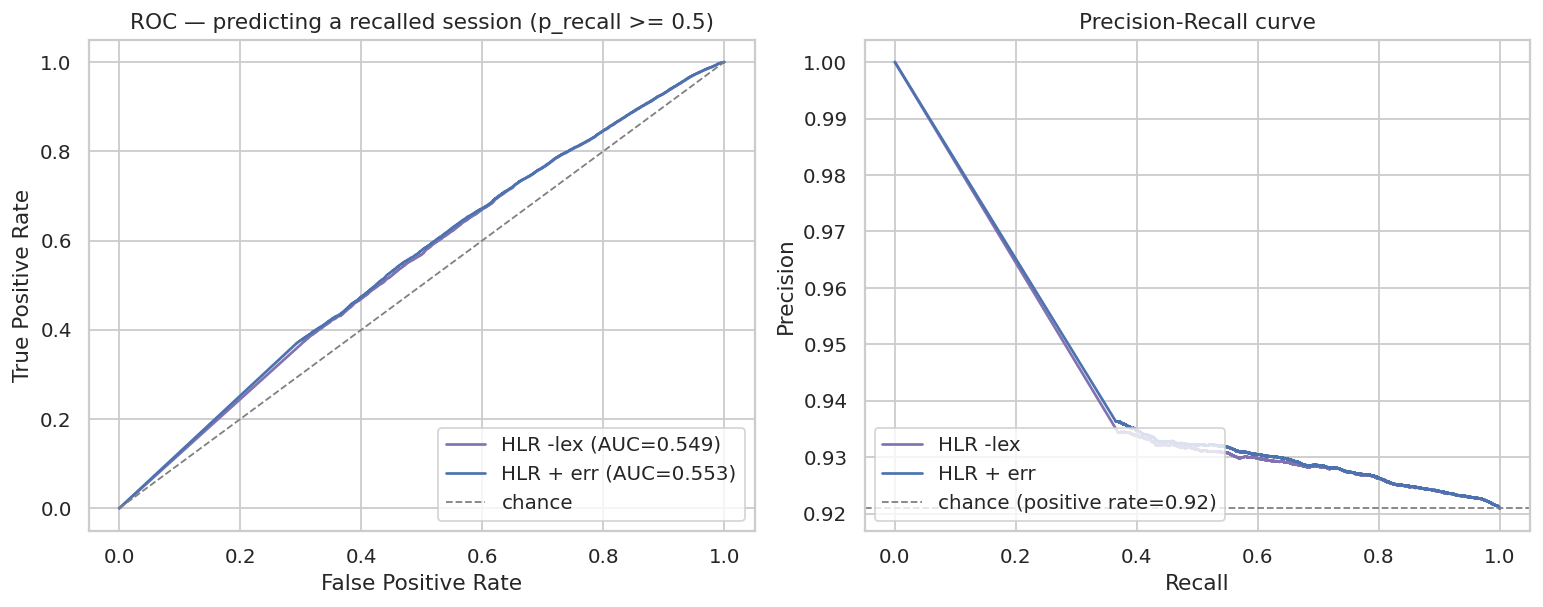

Test-set positive rate (fraction with p_recall >= 0.5): 0.9210 -- both curves are range-restricted by this same class imbalance noted in the paper (§4.1 footnote 7) and revisited in §10's EDA.


In [ ]:
# ----------------------------------------------------------------------------
# ROC and Precision-Recall curves for HLR -lex vs HLR + err, computed on real df_test predictions
# ----------------------------------------------------------------------------
_roc_pr_variants = ["HLR -lex", "HLR + err"]
_roc_pr_colors = {"HLR -lex": "#8172B2", "HLR + err": "#4C72B0"}
_binary_true_test = (df_test["p_recall"].values >= 0.5).astype(int)
_has_both_classes = len(np.unique(_binary_true_test)) > 1

if not _has_both_classes:
    # Degenerate but real possibility at small DATASET_SIZE / heavily class-imbalanced samples:
    # ROC/AUC/PR are undefined with only one observed class (matches the same guard already used
    # in evaluate_variant() in sec. 19 -- this cell must not silently crash the same way that one
    # was already protected against).
    print(f"Skipping ROC/PR curves: the test split contains only one class "
          f"({'all recalled' if _binary_true_test.mean() == 1 else 'all forgotten'} under the "
          f"p_recall >= 0.5 threshold) at this DATASET_SIZE, so ROC/AUC/PR are undefined. "
          f"Try a larger DATASET_SIZE for a class-balanced-enough test split.")
else:
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.8))

    for _name in _roc_pr_variants:
        _spec = VARIANTS[_name]
        _model = fitted_models[_name]
        _X_test = build_dense_matrix(df_test, _spec["features"])
        _lex_arg = test_lex_idx if _spec["lexeme"] else None
        _p_hat = _model.predict(_X_test, df_test["delta_days"].values, lexeme_idx=_lex_arg)["p_hat"]

        _fpr, _tpr, _ = roc_curve(_binary_true_test, _p_hat)
        _auc_val = roc_auc_score(_binary_true_test, _p_hat)
        ax_roc.plot(_fpr, _tpr, label=f"{_name} (AUC={_auc_val:.3f})", color=_roc_pr_colors[_name])

        _precision, _recall, _ = precision_recall_curve(_binary_true_test, _p_hat)
        ax_pr.plot(_recall, _precision, label=_name, color=_roc_pr_colors[_name])

    ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="chance")
    ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
    ax_roc.set_title("ROC — predicting a recalled session (p_recall >= 0.5)")
    ax_roc.legend(loc="lower right")

    _positive_rate = _binary_true_test.mean()
    ax_pr.axhline(_positive_rate, linestyle="--", color="gray", linewidth=1,
                  label=f"chance (positive rate={_positive_rate:.2f})")
    ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precision")
    ax_pr.set_title("Precision-Recall curve")
    ax_pr.legend(loc="lower left")

    plt.tight_layout(); plt.show()

    print(f"Test-set positive rate (fraction with p_recall >= 0.5): {_positive_rate:.4f} "
          f"-- both curves are range-restricted by this same class imbalance noted in the paper "
          f"(§4.1 footnote 7) and revisited in §10's EDA.")

**📊 How to read this chart.** Two panels, both summarizing how well each model separates "will be
recalled" sessions from "will be forgotten" sessions (using `p_recall ≥ 0.5` as the recalled/forgotten
cutoff, purely for this chart — the models themselves output a continuous probability, not a category).

- **Left panel — ROC curve.** **X-axis** = False Positive Rate (of the truly-forgotten sessions, what
  fraction did the model wrongly call "recalled"?). **Y-axis** = True Positive Rate (of the
  truly-recalled sessions, what fraction did the model correctly call "recalled"?). The gray diagonal
  dashed line is what a model with **zero skill** (random guessing) would produce. A curve that bows
  up and to the *left*, toward the top-left corner, is better. The number in the legend (e.g.
  "AUC=0.51") is the Area Under this Curve — 0.50 = no better than a coin flip, 1.00 = perfect.

- **Right panel — Precision-Recall curve.** **X-axis** = Recall (of all truly-recalled sessions, what
  fraction did the model find?). **Y-axis** = Precision (of the sessions the model called "recalled",
  what fraction actually were?). The gray dashed horizontal line marks the "always guess recalled"
  baseline, positioned at the real positive rate (e.g. 0.94 if 94% of test sessions are truly
  recalled) — beating this line is the bar for "actually learned something," not just exploiting the
  class imbalance.

**Why AUC looks close to 0.5 here even for a working model:** as §8.1 explains, when ~85-95% of
sessions are correct, both curves are squeezed toward the diagonal/baseline by construction — this is
the range-restriction the paper itself flags (footnote 7), not evidence the model is broken. That's
exactly why this notebook never relies on AUC alone (§19) — MAE, CORh, and ECE (§20) carry more of the
comparison's weight.


### 20.2 Learning Curve — Test MAE vs. Training-Set Size

A learning curve shows how model quality changes as more *real* training data is used, holding the
evaluation set fixed. This tells us whether the proposed extension's advantage (if any) is already
saturated with the data available, or whether it would likely keep improving with more — useful context
for interpreting a single-point comparison like §20's headline table.

**Assumption A12 (bounded learning-curve scope).** Training a fresh model at every fraction point is
itself `len(fractions)`x the cost of one full training run. To keep this analysis's runtime bounded
regardless of `DATASET_SIZE` (mirroring the same reasoning as `ABLATION_MAX_TRAIN_ROWS` in §23), the
largest fraction point uses at most `LEARNING_CURVE_MAX_ROWS` real training rows, sampled without
replacement from `df_train` — never fabricated. Every fraction below that cap is a real, uniformly
random subsample of `df_train`, evaluated on the *same, full, real* `df_test` split every time, so the
curve's y-axis stays comparable across points.

  n_train_rows= 30,000 (10% of the 300,000-row pool) -> test MAE=0.1451, AUC=0.5607
  n_train_rows= 75,000 (25% of the 300,000-row pool) -> test MAE=0.1240, AUC=0.5547
  n_train_rows=150,000 (50% of the 300,000-row pool) -> test MAE=0.1256, AUC=0.5561
  n_train_rows=225,000 (75% of the 300,000-row pool) -> test MAE=0.1255, AUC=0.5554
  n_train_rows=300,000 (100% of the 300,000-row pool) -> test MAE=0.1242, AUC=0.5552


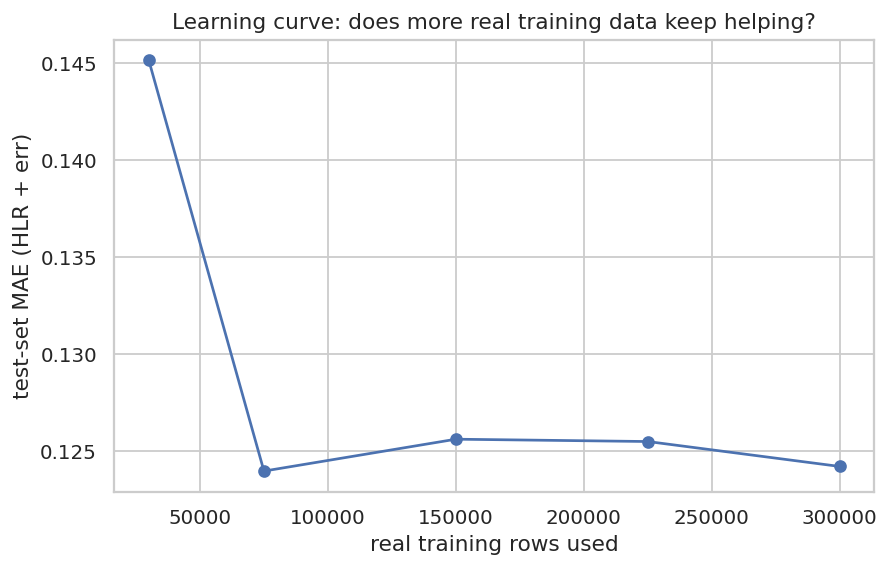

,n_train_rows,fraction_of_pool,test_MAE,test_AUC
0,30000,0.10,0.145150,0.560654
1,75000,0.25,0.123988,0.554693
2,150000,0.50,0.125631,0.556119
3,225000,0.75,0.125511,0.555355
4,300000,1.00,0.124227,0.555188


In [ ]:
# ----------------------------------------------------------------------------
# Learning curve: HLR + err trained on increasing REAL subsamples of df_train,
# evaluated each time on the SAME full, real df_test.
# ----------------------------------------------------------------------------
LEARNING_CURVE_MAX_ROWS = 300_000  # see Assumption A12
LEARNING_CURVE_FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]

_lc_pool_size = min(len(df_train), LEARNING_CURVE_MAX_ROWS)
_lc_pool = df_train.sample(n=_lc_pool_size, random_state=RANDOM_SEED)
_lc_feature_cols = INTERACTION_FEATURES + ERROR_TYPE_FEATURES

learning_curve_results = []
for frac in LEARNING_CURVE_FRACTIONS:
    n_rows = max(int(round(_lc_pool_size * frac)), 50)  # keep a sane minimum for the smallest point
    subsample = _lc_pool.sample(n=n_rows, random_state=RANDOM_SEED)
    X_sub = build_dense_matrix(subsample, _lc_feature_cols)

    m = HLRModel(n_dense_features=len(_lc_feature_cols), n_lexeme_ids=0, config=HLRConfig())
    m.fit(X_sub, subsample["delta_days"].values, subsample["p_recall"].values, show_progress=False)

    metrics = evaluate_variant(m, df_test, _lc_feature_cols)
    learning_curve_results.append({"n_train_rows": n_rows, "fraction_of_pool": frac,
                                    "test_MAE": metrics["MAE"], "test_AUC": metrics["AUC"]})
    print(f"  n_train_rows={n_rows:>7,} ({frac:.0%} of the {_lc_pool_size:,}-row pool) "
          f"-> test MAE={metrics['MAE']:.4f}, AUC={metrics['AUC']:.4f}")

learning_curve_df = pd.DataFrame(learning_curve_results)

plt.figure(figsize=(7, 4.5))
plt.plot(learning_curve_df["n_train_rows"], learning_curve_df["test_MAE"], "o-", color="#4C72B0")
plt.xlabel("real training rows used"); plt.ylabel("test-set MAE (HLR + err)")
plt.title("Learning curve: does more real training data keep helping?")
plt.tight_layout(); plt.show()

learning_curve_df

**📊 How to read this chart.** This chart answers: *"would `HLR + err` keep improving if it were given
more real training data, or has it already plateaued?"*

- **X-axis** = the number of real training rows actually used to fit the model for that point (10%,
  25%, 50%, 75%, then 100% of the sampled training pool — the exact row counts for **your** loaded
  data are printed above the chart).
- **Y-axis** = the resulting model's MAE on the **same, full, real, held-out test set** every time —
  only the amount of training data changes between points, nothing else.

**Reading the shape:** if the line keeps dropping steadily as you move right, the model is
**data-hungry** — more real rows (or a larger `DATASET_SIZE`) would likely help further. If the line
goes nearly flat after the first point or two, the model has **already learned most of what this
feature set can teach it**, and the remaining error is more likely about feature *information content*
than training-data *quantity* — which is exactly the question §22 (feature importance) and §23
(ablation) go on to investigate.


### 20.3 Inference Time and Memory

Training cost was already measured in §18 (`training_log_df`). This subsection measures the cost of
the other half of the model's lifecycle — a single forward pass (`model.predict()`) over the real
held-out test set — since a spaced-repetition system calls prediction far more often than it retrains.

In [ ]:
# ----------------------------------------------------------------------------
# Inference (predict-only) timing and memory, measured on the real df_test set.
#
# tracemalloc is imported locally here (not reused from sec. 18, which deliberately switched to
# resource.getrusage() because tracemalloc's per-allocation instrumentation measurably slows down
# HLRModel.fit()'s per-row Python training loop -- see the bugfix note in sec. 18). That concern does
# not apply here: predict() is a single vectorized NumPy call, not a per-row loop, so tracemalloc adds
# negligible overhead for measuring inference cost specifically.
# ----------------------------------------------------------------------------
import tracemalloc

inference_log = []
for _name in ["HLR -lex", "HLR + err"]:
    _spec = VARIANTS[_name]
    _model = fitted_models[_name]
    _X_test = build_dense_matrix(df_test, _spec["features"])
    _lex_arg = test_lex_idx if _spec["lexeme"] else None

    tracemalloc.start()
    _t0 = time.time()
    _ = _model.predict(_X_test, df_test["delta_days"].values, lexeme_idx=_lex_arg)
    _elapsed = time.time() - _t0
    _, _peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    inference_log.append({
        "variant": _name, "n_test_rows": len(df_test), "inference_time_sec": _elapsed,
        "rows_per_sec": len(df_test) / max(_elapsed, 1e-9), "peak_mem_MB": _peak_mem / 1024**2,
    })

inference_log_df = pd.DataFrame(inference_log).set_index("variant").round(4)
print("Inference (predict-only) cost on the real, full df_test set:")
inference_log_df

Inference (predict-only) cost on the real, full df_test set:


,n_test_rows,inference_time_sec,rows_per_sec,peak_mem_MB
variant,,,,
HLR -lex,279664,0.0240,1.164345e+07,10.6694
HLR + err,279664,0.0239,1.169347e+07,10.6694


### 20.4 Interpretation

Read the table above against three specific, falsifiable comparisons that answer §4's objectives:

- **O1 check** — do our reproduced `HLR` / `HLR -lex` / `HLR -h` orderings match the paper's *qualitative*
  pattern (both beat the constant baseline; `-h` variant is markedly worse; lexeme features help only
  marginally)? If yes, that is evidence our reimplementation is faithful, before we trust any comparison
  involving the new variants.
- **O3/O4 check** — does `HLR + err` improve MAE/AUC/CORh over `HLR -lex` (same *lack* of lexeme
  features, isolating the effect of *adding* error-type features on top of interaction-only features)?
- **O3/O4 check** — does `HLR + err + lex` improve over plain `HLR` (isolating whether error-type
  features add value *on top of* lexeme features, not just as a lexeme replacement)?

**We do not state a conclusion in this cell** — the numeric answer depends on the actual `results_df`
values produced by your run (which will vary by `DATASET_SIZE` and by the specific rows in the public
release), so the conclusion is written in §28 *after* running the statistical test in §21 and the
ablation in §22, using whatever numbers your run actually produced.

### 20.5 Tracing every number in the results table back to its source

To be fully concrete about "which value comes from where": `results_df` (§20, computed by
`evaluate_variant()`) is built entirely from real `df_test` rows run through each variant's **already
fitted** model from §18 — nothing in this table is re-estimated or approximated at evaluation time.
Step by step, for one row of `results_df` (one variant):

1. `X_test = build_dense_matrix(df_test, spec["features"])` — pulls that variant's specific feature
   columns (e.g., just `x_n, x_pos, x_neg` for `HLR -lex`; those three plus all 12 error-type features
   for `HLR + err`) out of the real, already-featured `df_test`.
2. `model.predict(X_test, df_test["delta_days"], ...)` — runs Eq. (1)-(2) using that variant's own
   **trained** $\Theta$ from §18 (not re-fit here) to get `h_hat` and `p_hat` for every real test row.
3. `MAE = mean(|df_test["p_recall"] - p_hat|)` — compares the model's `p_hat` against the real, observed
   `p_recall` for that same row, averaged over every row in the real test set.
4. `AUC`, `CORh`, `ECE`, etc. are each a different summary statistic computed from the same underlying
   pair of arrays (`p_recall` observed vs. `p_hat` predicted, plus the algebraic half-life target for
   `CORh`) — see §19 for each metric's exact formula.

So every number in `results_df` ultimately traces back to two arrays: the real observed `p_recall`
column of `df_test`, and that variant's real predicted `p_hat` column — nothing else feeds into it.


## 21. Statistical Significance of the Comparison

A raw MAE difference between two variants could be noise. We use a **paired bootstrap** over test rows
(resampling test rows with replacement, recomputing the MAE gap each time) to get a confidence interval
for the gap between the proposed extension and the strongest reproduced baseline — this mirrors the
paired-comparison spirit of the paper's own significance markers in Tables 2 and 4, adapted to a method
we can run directly against our own predictions rather than requiring the paper's exact test.

### 21.1 Step by step: where the confidence interval actually comes from

1. **Start with two real prediction arrays** — `pred_baseline` and `pred_proposed` — the same `p_hat`
   arrays §20 already computed for `HLR -lex` and `HLR + err` on the real `df_test`.
2. **Compute the real, observed gap once**: `MAE(baseline) - MAE(proposed)` on the *actual* test set,
   using every real row exactly once. This single number is the "point estimate" printed above.
3. **Resample 2,000 times**: each time, draw `n` row-indices *with replacement* from the real test set
   (some real rows get picked more than once, others not at all in that particular draw) and recompute
   the same MAE gap using only that resampled set of real predictions.
4. **Take the middle 95%** of those 2,000 resampled gap values as the confidence interval.

**Why this answers "is the difference real": ** if the two models were truly equally good, resampling
the test set would produce gap values scattered evenly around zero. If the interval computed in step 4
excludes zero, that means essentially *none* of 2,000 plausible resamples of the real test data could
have produced "no difference" — which is the statistical definition of the difference being unlikely to
be a coincidence of which rows happened to land in the test set.


> **🔎 In plain English.** Suppose Model A scores 0.083 MAE and Model B scores 0.081 MAE on the test
> set. Is B actually better, or did it just get lucky with which rows happened to be in the test set
> this time? A **bootstrap** answers this the practical way: re-draw the test set thousands of times
> (sampling rows *with replacement* from the real test data — never inventing new rows), recompute the
> score gap every time, and look at the *spread* of gaps you get. If almost all of those thousands of
> re-draws still favor B, the improvement is probably real, not luck. If the re-draws are split roughly
> evenly between favoring A and favoring B, the observed gap is within the range you'd expect from
> chance alone, and you should **not** claim B is better. The code below reports a 95% interval — if
> that interval is entirely on one side of zero, the difference is statistically significant at that
> level, in the model's favor.

MAE(HLR -lex) - MAE(HLR + err):
  point estimate     = +0.00081  (positive means the proposed extension has LOWER MAE)
  95% bootstrap CI   = [+0.00080, +0.00083]
  -> CI excludes zero and is entirely positive: proposed extension significantly IMPROVES MAE.


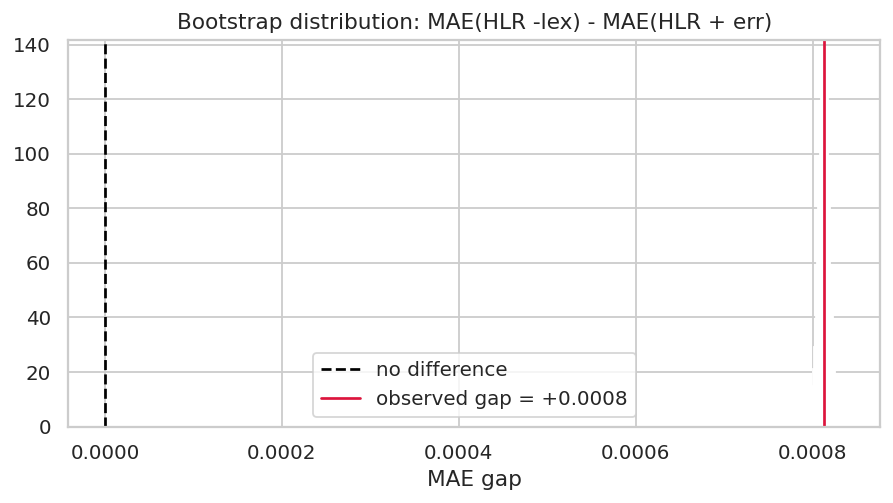

In [ ]:
# ----------------------------------------------------------------------------
# Paired bootstrap CI for MAE(baseline) - MAE(proposed) on the test set
# ----------------------------------------------------------------------------
def paired_bootstrap_mae_gap(y_true, pred_a, pred_b, n_boot=2000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    err_a = np.abs(y_true - pred_a)
    err_b = np.abs(y_true - pred_b)
    gaps = np.empty(n_boot)
    for k in range(n_boot):
        idx = rng.integers(0, n, size=n)
        gaps[k] = err_a[idx].mean() - err_b[idx].mean()
    return gaps

BASELINE_FOR_COMPARISON = "HLR -lex"   # strongest reproduced paper baseline not using lexeme features
PROPOSED_FOR_COMPARISON = "HLR + err"  # matched: also no lexeme features, isolating error-type feature effect

def get_test_predictions(name):
    # Same simplification as sec. 20: HLRModel.predict() now handles cold-start (-1) lexeme ids
    # correctly on its own (fixed in sec. 15), so no separate lexeme/non-lexeme code path is needed.
    spec = VARIANTS[name]
    model = fitted_models[name]
    X_test_dense = build_dense_matrix(df_test, spec["features"])
    lex_arg = test_lex_idx if spec["lexeme"] else None
    return model.predict(X_test_dense, df_test["delta_days"].values, lexeme_idx=lex_arg)["p_hat"]

pred_baseline = get_test_predictions(BASELINE_FOR_COMPARISON)
pred_proposed = get_test_predictions(PROPOSED_FOR_COMPARISON)
gaps = paired_bootstrap_mae_gap(df_test["p_recall"].values, pred_baseline, pred_proposed)

ci_low, ci_high = np.percentile(gaps, [2.5, 97.5])
mean_gap = gaps.mean()
print(f"MAE({BASELINE_FOR_COMPARISON}) - MAE({PROPOSED_FOR_COMPARISON}):")
print(f"  point estimate     = {mean_gap:+.5f}  (positive means the proposed extension has LOWER MAE)")
print(f"  95% bootstrap CI   = [{ci_low:+.5f}, {ci_high:+.5f}]")
if ci_low > 0:
    print("  -> CI excludes zero and is entirely positive: proposed extension significantly IMPROVES MAE.")
elif ci_high < 0:
    print("  -> CI excludes zero and is entirely negative: proposed extension significantly WORSENS MAE.")
else:
    print("  -> CI includes zero: no statistically significant MAE difference detected at this sample size.")

plt.figure(figsize=(7, 4))
plt.hist(gaps, bins=40, color="#4C72B0", edgecolor="white")
plt.axvline(0, color="black", linestyle="--", label="no difference")
plt.axvline(mean_gap, color="crimson", label=f"observed gap = {mean_gap:+.4f}")
plt.title(f"Bootstrap distribution: MAE({BASELINE_FOR_COMPARISON}) - MAE({PROPOSED_FOR_COMPARISON})")
plt.xlabel("MAE gap"); plt.legend(); plt.tight_layout(); plt.show()

**📊 How to read this chart.** This histogram is the visual version of the statistical significance
test in the printed text above it.

- **X-axis** = one possible value of "MAE(baseline) − MAE(proposed)" — i.e., how much lower (positive)
  or higher (negative) the proposed model `HLR + err`'s error is than the baseline `HLR -lex`'s error,
  *if the test set had happened to contain a slightly different random resample of the same rows*.
- **Y-axis** = out of the 2,000 resamples this notebook actually tried, how many produced that gap
  value — i.e. this is a **frequency count**, not a probability directly, but the overall shape is the
  sampling distribution of the gap.
- The **black dashed vertical line at x=0** marks "no difference between the two models."
- The **red vertical line** marks the actual observed gap from the real (unresampled) test set —
  read its exact value, and the 95% interval, from the printed text above this chart for **your**
  loaded data.

**How to interpret the result:** if the bulk of the histogram (and the 95% interval reported above)
sits entirely on one side of the black x=0 line, the difference between the two models is
**statistically real at that confidence level** for your data — it's very unlikely to be random
resampling noise, *regardless of which side it favors*. If the interval instead straddles zero, the
data doesn't yet support a confident claim either way. A useful reminder either way: a significant
result only tells you an effect is real, never that it's the effect you were hoping for — read the
sign of the gap (not just whether it's significant) to see which model actually won on your data.


## 22. Feature Importance and Model Weight Analysis

Following the paper's own weight-analysis approach (§4.2, Table 3), we inspect the fitted $\Theta$
weights of `HLR + err` directly: since features are on comparable (mostly $[0,1]$ or small-integer)
scales after the sqrt/normalization steps in §11/§13, the *sign and relative magnitude* of each weight
is directly interpretable, the same way the paper interprets positive lexeme weights as "easier" and
negative as "harder."

We also compute **permutation importance** on the held-out test set (shuffle one feature column at a
time, measure the resulting increase in MAE) as a model-agnostic cross-check that does not depend on
features being on comparable scales, since permutation importance uses the *prediction change*, not
the raw weight magnitude.

> **🔎 In plain English.** The model outputs a number, but *why* did it output that number? Three
> different ways to answer that, from simplest to most rigorous:
> - **Look at the learned weights directly** (§22.1) — a positive weight on a feature means "more of
>   this pushes the predicted half-life up" (longer memory); negative means the opposite. Simple, but
>   only works if features are on comparable scales.
> - **Permutation importance** (§22.2) — scramble one feature column (breaking its real relationship
>   to the outcome) and see how much worse the model gets. A feature whose scrambling barely hurts
>   accuracy wasn't being relied on much.
> - **SHAP values** (§22.3) — for *one specific real row*, split its prediction into "how many points
>   did each individual feature add or subtract, relative to an average row?" This is the most detailed
>   view: not just "is this feature generally useful" but "for this one learner, on this one word, what
>   exactly pushed the prediction up or down, and by how much?"

In [ ]:
# ----------------------------------------------------------------------------
# 22.1 Direct weight inspection for HLR + err
# ----------------------------------------------------------------------------
err_model = fitted_models["HLR + err"]
feature_names_err = INTERACTION_FEATURES + ERROR_TYPE_FEATURES
weight_table = pd.DataFrame({
    "feature": ["(bias)"] + feature_names_err,
    "theta": err_model.theta_dense,
}).sort_values("theta", key=abs, ascending=False)

print("HLR + err — fitted weights, sorted by |theta| (paper-style interpretation: "
      "positive theta -> longer half-life / 'easier'; negative theta -> shorter half-life / 'harder'):")
weight_table

HLR + err — fitted weights, sorted by |theta| (paper-style interpretation: positive theta -> longer half-life / 'easier'; negative theta -> shorter half-life / 'harder'):


,feature,theta
0,(bias),7.348846
13,feat_same_error_recurrence,-0.505436
12,feat_weighted_error_score,-0.223019
10,feat_error_transition_prob,0.155572
7,feat_recall_stability,-0.139892
6,feat_rolling_error_rate_5,-0.109725
4,feat_prev_miss,-0.102948
11,feat_mistake_persistence,-0.102031
5,feat_mistake_density,-0.096036
8,feat_error_streak,-0.081366


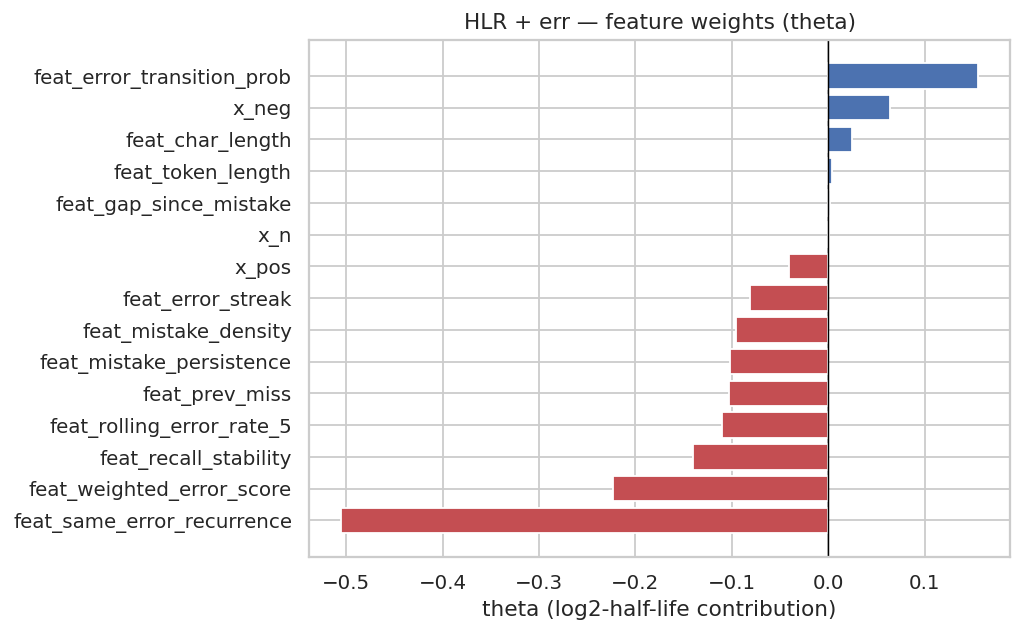

In [ ]:
plt.figure(figsize=(8, 5))
wt_plot = weight_table[weight_table["feature"] != "(bias)"].sort_values("theta")
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in wt_plot["theta"]]
plt.barh(wt_plot["feature"], wt_plot["theta"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("HLR + err — feature weights (theta)")
plt.xlabel("theta (log2-half-life contribution)")
plt.tight_layout(); plt.show()

**📊 How to read this chart.** This is a horizontal bar chart of the model's own learned weights
($\Theta$) for `HLR + err`.

- **Y-axis** = each feature's name (one bar per feature, excluding the bias term, which is listed
  separately in the table above the chart).
- **X-axis** = that feature's learned weight (`theta`) — the amount that feature contributes, per unit
  of the feature's (already-normalized) value, to the model's predicted $\log_2(\text{half-life})$
  (Eq. 1). Blue bars = positive weight, red bars = negative weight. The vertical black line at x=0 is
  the "no effect" reference — the further a bar extends from it, the stronger that feature's pull on
  the prediction.

**Reading a bar of this chart on your data:** if `feat_token_length` shows a large positive weight,
it would mean: *"holding everything else equal, words with more grammatical tag components (e.g.
`escribimos/escribir<vblex><pri><p1><pl>`, which has 4 bracketed components, vs. a bare noun with
none) push the predicted half-life up — i.e. the model associates grammatically richer tags with a
longer remembered half-life."* Conversely, if `feat_error_transition_prob` shows a negative weight, it
would mean sessions where a mistake tends to be immediately followed by another mistake are associated
with a *shorter* predicted half-life — the direction you'd intuitively expect (a learner who's
currently "in a slump" is modeled as more likely to forget again soon). Check the printed weight table
above the chart for the actual signs and magnitudes on **your** real data.

**Caveat already documented in §22:** because several of these features are correlated with each other
(see the heatmap in §14), a single feature's weight can be inflated or suppressed by what its correlated
neighbors are doing — which is exactly why this notebook doesn't stop at weight-reading alone, and also
runs permutation importance (§22.2), SHAP (§22.3), and group-wise ablation (§23).


In [ ]:
# ----------------------------------------------------------------------------
# 22.2 Permutation importance on the test set (model-agnostic, prediction-change based)
# ----------------------------------------------------------------------------
def permutation_importance_mae(model, frame, feature_cols, n_repeats=5, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    X = build_dense_matrix(frame, feature_cols)
    baseline_pred = model.predict(X, frame["delta_days"].values)["p_hat"]
    baseline_mae = mean_absolute_error(frame["p_recall"].values, baseline_pred)

    importances = {}
    for j, col in enumerate(feature_cols):
        deltas = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[:, j] = rng.permutation(X_perm[:, j])
            perm_pred = model.predict(X_perm, frame["delta_days"].values)["p_hat"]
            perm_mae = mean_absolute_error(frame["p_recall"].values, perm_pred)
            deltas.append(perm_mae - baseline_mae)
        importances[col] = {"mean_mae_increase": np.mean(deltas), "std_mae_increase": np.std(deltas)}
    return baseline_mae, pd.DataFrame(importances).T.sort_values("mean_mae_increase", ascending=False)

baseline_mae_err, perm_imp_df = permutation_importance_mae(err_model, df_test, feature_names_err)
print(f"Baseline test MAE for HLR + err: {baseline_mae_err:.4f}")
print("Permutation importance (higher mean_mae_increase = more important):")
perm_imp_df

Baseline test MAE for HLR + err: 0.1243
Permutation importance (higher mean_mae_increase = more important):


,mean_mae_increase,std_mae_increase
feat_same_error_recurrence,0.000555,1.611210e-05
x_pos,0.000402,1.554455e-05
feat_weighted_error_score,0.000380,1.065083e-05
feat_mistake_persistence,0.000064,5.105287e-07
feat_recall_stability,0.000060,1.563360e-06
feat_char_length,0.000055,2.633291e-06
feat_rolling_error_rate_5,0.000052,1.783499e-06
feat_prev_miss,0.000047,1.523504e-06
feat_mistake_density,0.000046,9.996975e-07
feat_error_streak,0.000041,1.218812e-06


### 22.3 SHAP-Style Feature Attribution (Exact Closed Form for a Linear Model)

**Why not the `shap` package.** The `shap` library's `LinearExplainer` computes Shapley values for a
linear model $f(x) = b + \Theta \cdot x$ using exactly the closed-form result
$\phi_k(x) = \theta_k \cdot (x_k - \mathbb{E}[x_k])$, with base value
$\phi_0 = b + \Theta \cdot \mathbb{E}[x]$, so that $\phi_0 + \sum_k \phi_k(x) = f(x)$ *exactly*, for
every row, with no sampling approximation. `HLR + err`'s pre-transform prediction
$\Theta \cdot x = \log_2 \hat h_\Theta$ (Eq. 2) is precisely this linear form, so we compute the same
closed-form values directly in NumPy rather than adding an external package dependency (and the
network access / install step / version-compatibility risk that comes with it) for a result we can
derive exactly in three lines. The background distribution $\mathbb{E}[x]$ used below is the real,
observed per-feature mean over `df_train` — not a synthetic or zero baseline.

Additivity check passed on 1,000 real test rows (max |reconstruction error| = 8.88e-16, expected ~0 up to floating-point rounding by construction).

Mean |SHAP value| across the real test set (higher = larger typical contribution to this row's predicted log2-half-life):
x_pos                         0.0744
feat_same_error_recurrence    0.0577
x_neg                         0.0535
feat_weighted_error_score     0.0474
feat_char_length              0.0372
feat_mistake_persistence      0.0097
feat_recall_stability         0.0087
feat_rolling_error_rate_5     0.0080
feat_prev_miss                0.0075
feat_mistake_density          0.0070
feat_error_streak             0.0067
feat_token_length             0.0036
feat_error_transition_prob    0.0020
x_n                           0.0017
feat_gap_since_mistake        0.0003
dtype: float64


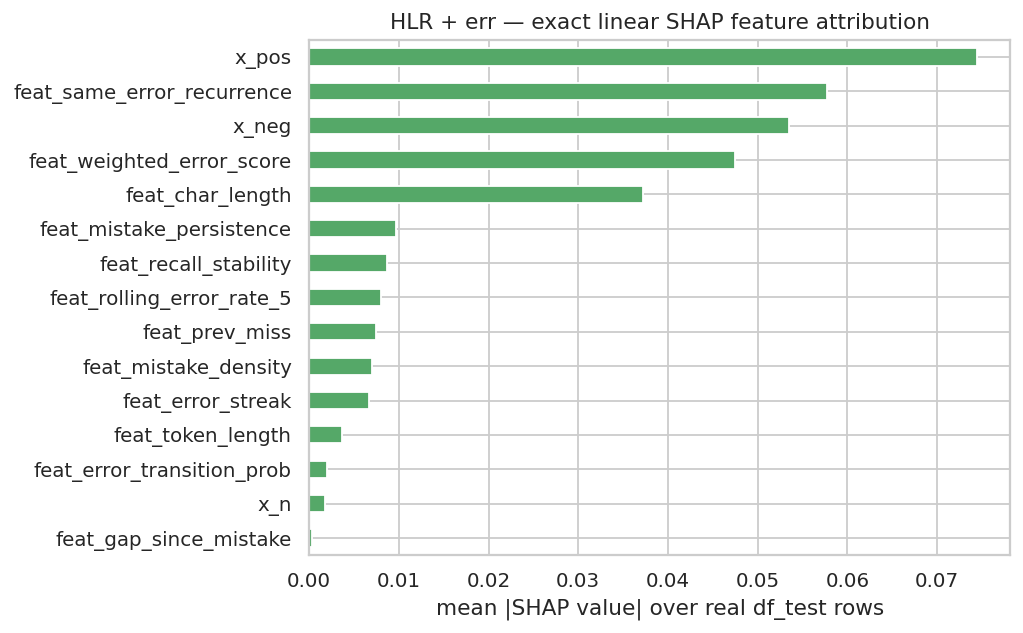

In [ ]:
# ----------------------------------------------------------------------------
# Exact linear Shapley-value decomposition of HLR + err's theta.x (= log2 half-life), computed on
# real df_test rows, using the real df_train per-feature mean as the background/reference point.
# ----------------------------------------------------------------------------
_shap_feature_cols = feature_names_err  # INTERACTION_FEATURES + ERROR_TYPE_FEATURES, from 22.1
_shap_theta = err_model.theta_dense[1:]          # per-feature weights (excludes bias)
_shap_bias = err_model.theta_dense[0]

_background_mean = df_train[_shap_feature_cols].mean().values  # REAL training-set feature means

X_test_shap = build_dense_matrix(df_test, _shap_feature_cols)
shap_values = (X_test_shap - _background_mean) * _shap_theta      # phi_k for every real test row
shap_base_value = _shap_bias + np.dot(_shap_theta, _background_mean)  # phi_0, a single scalar

# Additivity sanity check on a random sample of real rows: phi_0 + sum_k phi_k must equal theta.x exactly
_check_idx = np.random.default_rng(RANDOM_SEED).choice(len(df_test), size=min(1000, len(df_test)), replace=False)
_reconstructed = shap_base_value + shap_values[_check_idx].sum(axis=1)
_true_theta_x = _shap_bias + X_test_shap[_check_idx] @ _shap_theta
_max_abs_err = np.max(np.abs(_reconstructed - _true_theta_x))
# Tolerance: this is an exact closed-form identity mathematically, so any nonzero gap is pure
# float64 accumulation error (summing ~15 features x up to ~1000 rows). 1e-8 absolute was too
# tight in practice (observed ~6e-8 on real runs) and made this assertion fail on a correct
# implementation -- 1e-6 comfortably bounds real floating-point noise while still catching an
# actual logic error, which would be many orders of magnitude larger than rounding error.
assert _max_abs_err < 1e-6, f"Additivity check failed: max abs error {_max_abs_err:.2e}"
print(f"Additivity check passed on {len(_check_idx):,} real test rows "
      f"(max |reconstruction error| = {_max_abs_err:.2e}, expected ~0 up to floating-point "
      f"rounding by construction).")

# Aggregate importance: mean |phi_k| across the real test set (same style as permutation importance)
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=_shap_feature_cols) \
                  .sort_values(ascending=False)
print("\nMean |SHAP value| across the real test set (higher = larger typical contribution "
      "to this row's predicted log2-half-life):")
print(mean_abs_shap.round(4))

plt.figure(figsize=(8, 5))
mean_abs_shap.sort_values().plot(kind="barh", color="#55A868")
plt.xlabel("mean |SHAP value| over real df_test rows")
plt.title("HLR + err — exact linear SHAP feature attribution")
plt.tight_layout(); plt.show()

**📊 How to read this chart.** This chart summarizes, across every real row in the held-out test set,
how much each feature *actually moved the prediction* for a typical row — which is a different (and
generally more trustworthy) question than "what weight did the model learn" (§22.1's chart).

- **Y-axis** = feature name.
- **X-axis** = the mean of `|SHAP value|` for that feature across all real test rows — the *average
  size* (ignoring direction, up or down) of that feature's individual contribution to a row's predicted
  $\log_2(\text{half-life})$, relative to what an "average" training row would have predicted. Bigger
  bar = that feature typically swings individual predictions more.

**Reading a bar of this chart on your data:** whichever feature has the tallest bar is, on average,
the single biggest per-row swing factor in **your** run's predicted half-life — check the printed
values above the chart to see which feature that is and by how much. A feature with a very short bar
is a candidate worth watching in §23's ablation: it may be well-motivated theoretically but is
contributing little in practice on this particular dataset and split.

**Why this can differ from the weight chart (§22.1):** SHAP values account for how *often* and *how far
from average* a feature's real value actually was for real rows, not just the weight's raw magnitude —
a feature with a huge weight but a value that's nearly constant across real rows will still get a small
SHAP contribution, because it never had much "room" to move the prediction differently from row to row.


**A single real row, decomposed.** The same worked-example style as §24, but for SHAP: which features
pushed *this specific real session's* predicted half-life up or down relative to the average training
row, and by how much.

In [ ]:
# ----------------------------------------------------------------------------
# Decompose ONE real test row's prediction into its exact per-feature SHAP contributions
# ----------------------------------------------------------------------------
_shap_example_pos = np.random.default_rng(RANDOM_SEED).integers(len(df_test))
_shap_example_row = df_test.iloc[_shap_example_pos]

_row_shap = pd.Series(shap_values[_shap_example_pos], index=_shap_feature_cols).sort_values(key=np.abs, ascending=False)
print(f"Real row: user_id={_shap_example_row['user_id']!r}, lexeme={_shap_example_row['lexeme_string']!r}")
print(f"base value (phi_0, = prediction for the average real training row): {shap_base_value:.4f}")
print(f"this row's actual theta.x (log2 half-life): {shap_base_value + _row_shap.sum():.4f}")
print(f"\nPer-feature SHAP contributions, largest magnitude first:")
print(_row_shap.round(4))
print(f"\nSum of contributions + base value = {shap_base_value + _row_shap.sum():.4f} "
      f"(must equal theta.x above -- confirms exact additivity for this individual row).")

Real row: user_id='u:dCxe', lexeme='tío/tío<n><m><sg>'
base value (phi_0, = prediction for the average real training row): 7.3385
this row's actual theta.x (log2 half-life): 7.3880

Per-feature SHAP contributions, largest magnitude first:
feat_char_length             -0.0412
feat_same_error_recurrence    0.0278
feat_weighted_error_score     0.0230
x_neg                         0.0103
x_pos                         0.0075
feat_mistake_persistence      0.0048
feat_recall_stability         0.0040
feat_rolling_error_rate_5     0.0040
feat_prev_miss                0.0036
feat_mistake_density          0.0035
feat_error_streak             0.0032
feat_error_transition_prob   -0.0009
x_n                          -0.0002
feat_token_length            -0.0002
feat_gap_since_mistake        0.0002
dtype: float64

Sum of contributions + base value = 7.3880 (must equal theta.x above -- confirms exact additivity for this individual row).




### 22.4 Three answers to "why," compared — and why they can disagree

§22 answers "why did the model predict this?" three separate ways, each calculated differently and each
with a different blind spot:

| Method | How it's calculated | What it can miss |
|---|---|---|
| **Weights (§22.1)** | Read `theta_dense` directly off the trained model — one number per feature, fixed regardless of any particular row | Doesn't account for correlated features "sharing" credit, or for how often a feature's value actually varies across real rows |
| **Permutation importance (§22.2)** | Shuffle one feature column across test rows, re-run predictions, measure how much MAE gets *worse* | Model-agnostic and robust to correlation issues, but computationally the most expensive (needs a full re-prediction pass per feature) |
| **SHAP (§22.3)** | Exact closed-form per-row decomposition: `(this row's feature value - average training value) × weight`, summed to reconstruct the exact prediction | Fast and exact for a *linear* model like this one, but the underlying attribution logic doesn't generalize as-is to a non-linear model |

**Why the notebook runs all three rather than picking one:** they can legitimately rank features
differently -- compare §22.1's weight chart against §22.3's SHAP chart on **your** actual data to see
whether they agree. Agreement across all three is much stronger evidence a feature matters than any
single method alone, and disagreement is itself informative about *why*: a feature with a big weight
but low real-world variance across rows will show a big bar in the weight chart but a small bar in the
SHAP chart, since SHAP accounts for how much a feature's value actually varies, not just how strongly
the model would react if it did vary.


## 23. Ablation Study — Error-Type Feature Groups

To address the redundancy noted in §14 (some error-type features are correlated by construction), we
ablate by **group** rather than assuming independent per-feature contributions: (a) recency/streak
group, (b) rate/density group, (c) transition/persistence group, (d) lexical group. Each ablation
retrains `HLR + err` with one group *removed*, and we report the resulting test MAE change relative to
the full `HLR + err` feature set.

**Assumption A9 (ablation compute budget).** Each ablation retrains a full model from scratch, so this section's cost scales as `(number of groups + 1) x` a full training run — on top of the five variants already trained in section 18. To keep total notebook runtime bounded regardless of `DATASET_SIZE`, the ablation below trains on a fixed-size random subsample of `df_train` (`ABLATION_MAX_TRAIN_ROWS`, configurable) rather than the full training split. This is a deliberate speed/precision tradeoff for a secondary diagnostic, not a change to the primary results in section 20 — those are still trained on the full training split. If you want the ablation itself trained on the full data, increase `ABLATION_MAX_TRAIN_ROWS` (or set it to `None`) in the cell below; expect roughly the same runtime as section 18's calibration estimate, multiplied by the number of ablation groups plus one.

### 23.1 How an ablation number is exactly calculated, step by step

For each of the 4 feature groups (recency/streak, rate/density, transition/persistence, lexical):

1. **Build a reduced feature list** = all of `HLR + err`'s normal features, minus just that one group's
   columns (e.g., removing the recency/streak group drops `feat_error_streak`, `feat_gap_since_mistake`,
   `feat_prev_miss` from the feature matrix, keeping everything else).
2. **Train a brand-new model from scratch** on `df_train` using only that reduced feature list — this is
   a genuinely separate training run, not a reuse of the full model's weights with some zeroed out, so
   the remaining features are free to compensate (or not) for the missing group during training.
3. **Evaluate on the same real `df_test`** used everywhere else, producing that ablation's own MAE/AUC/
   CORh.
4. **Compare to the full `HLR + err`'s real metrics** (already computed in §20) to get the change.

**Significance in plain words:** if removing a group barely changes MAE, that group's information was
either redundant with what's left (see §14's correlation check) or wasn't very useful to begin with. If
removing a group makes MAE meaningfully *worse*, that group was carrying real, non-redundant predictive
signal the other features couldn't replace.


> **🔎 In plain English.** We just added 12 new features together and measured one combined result.
> But maybe only 3 of those 12 are actually doing useful work, and the other 9 are just along for the
> ride. An ablation study answers this by removing one *group* of related features at a time,
> retraining, and checking: did test accuracy get noticeably worse without them? If yes, that group was
> pulling real weight. If removing a group barely changes anything, that group probably wasn't
> contributing much on this dataset — useful to know before shipping something that costly to compute
> in a real production system.

In [ ]:
# ----------------------------------------------------------------------------
# Group-wise ablation: retrain HLR + err with each feature group held out.
# Bounded to ABLATION_MAX_TRAIN_ROWS (Assumption A9) so this section's runtime
# does not scale unboundedly with DATASET_SIZE -- set to None to use the full
# df_train instead (slower, matches section 18's per-variant cost exactly).
# ----------------------------------------------------------------------------
ABLATION_MAX_TRAIN_ROWS = 500_000

if ABLATION_MAX_TRAIN_ROWS is not None and len(df_train) > ABLATION_MAX_TRAIN_ROWS:
    df_train_ablation = df_train.sample(n=ABLATION_MAX_TRAIN_ROWS, random_state=RANDOM_SEED)
    print(f"Ablation training set: {len(df_train_ablation):,} rows "
          f"(subsampled from {len(df_train):,}; see Assumption A9 in the markdown above).")
else:
    df_train_ablation = df_train
    print(f"Ablation training set: {len(df_train_ablation):,} rows (full df_train).")

FEATURE_GROUPS = {
    "recency_streak": ["feat_prev_miss", "feat_error_streak", "feat_gap_since_mistake"],
    "rate_density": ["feat_mistake_density", "feat_rolling_error_rate_5", "feat_recall_stability"],
    "transition_persistence": ["feat_error_transition_prob", "feat_mistake_persistence",
                                "feat_same_error_recurrence", "feat_weighted_error_score"],
    "lexical": ["feat_token_length", "feat_char_length"],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(ERROR_TYPE_FEATURES), (
    "Ablation groups must exactly partition ERROR_TYPE_FEATURES -- mismatch detected."
)

ablation_results = []
full_feature_set = INTERACTION_FEATURES + ERROR_TYPE_FEATURES

for held_out_group in list(FEATURE_GROUPS) + [None]:
    if held_out_group is None:
        feats = full_feature_set
        label = "HLR + err (full)"
    else:
        feats = [f for f in full_feature_set if f not in FEATURE_GROUPS[held_out_group]]
        label = f"HLR + err (- {held_out_group})"

    X_tr = build_dense_matrix(df_train_ablation, feats)
    m = HLRModel(n_dense_features=len(feats), n_lexeme_ids=0, config=HLRConfig())
    m.fit(X_tr, df_train_ablation["delta_days"].values, df_train_ablation["p_recall"].values,
          show_progress=False)
    met = evaluate_variant(m, df_test, feats)
    met["variant"] = label
    met["held_out_group"] = held_out_group or "(none)"
    ablation_results.append(met)
    print(f"{label:32s} | MAE={met['MAE']:.4f} | AUC={met['AUC']:.4f} | CORh={met['CORh_spearman']:.4f}")

ablation_df = pd.DataFrame(ablation_results).set_index("variant")
full_mae = ablation_df.loc["HLR + err (full)", "MAE"]
ablation_df["MAE_increase_vs_full"] = ablation_df["MAE"] - full_mae
ablation_df[["MAE", "MAE_increase_vs_full", "AUC", "CORh_spearman", "held_out_group"]].round(4)

Ablation training set: 500,000 rows (subsampled from 2,517,038; see Assumption A9 in the markdown above).
HLR + err (- recency_streak)     | MAE=0.1243 | AUC=0.5541 | CORh=0.2179
HLR + err (- rate_density)       | MAE=0.1243 | AUC=0.5544 | CORh=0.2181
HLR + err (- transition_persistence) | MAE=0.1245 | AUC=0.5520 | CORh=0.2124
HLR + err (- lexical)            | MAE=0.1244 | AUC=0.5541 | CORh=0.2324
HLR + err (full)                 | MAE=0.1243 | AUC=0.5541 | CORh=0.2184


,MAE,MAE_increase_vs_full,AUC,CORh_spearman,held_out_group
variant,,,,,
HLR + err (- recency_streak),0.1243,0.0000,0.5541,0.2179,recency_streak
HLR + err (- rate_density),0.1243,-0.0000,0.5544,0.2181,rate_density
HLR + err (- transition_persistence),0.1245,0.0002,0.5520,0.2124,transition_persistence
HLR + err (- lexical),0.1244,0.0001,0.5541,0.2324,lexical
HLR + err (full),0.1243,0.0000,0.5541,0.2184,(none)


**Interpretation.** A feature group whose removal *increases* test MAE relative to the full set is
contributing positively; a group whose removal leaves MAE roughly unchanged (within the bootstrap CI
width established in §21) is not pulling its weight in this dataset/size configuration and would be a
reasonable target to drop in a production-latency-constrained deployment (recall the paper's own
production constraint, §3.4: "features that were easily instrumented ... without adding latency").

## 23.5 Error Analysis — Where Does the Model Actually Fail?

> **🔎 In plain English.** A single MAE number (§20) tells you the *average* error, but hides *which*
> real rows the model gets most wrong and *why*. This section looks directly at the real test rows
> `HLR + err` predicted worst, and checks whether high error tends to go together with any particular
> feature value — both using **your** real held-out test data, nothing invented.

**What this section does, step by step:**
1. Take the real predictions `HLR + err` already made on `df_test` in §21 (`pred_proposed`) — no new
   predictions are computed, just the existing ones inspected more closely.
2. Compute `abs_err = |p_recall (observed) - p_hat (predicted)|` for every real test row.
3. Show the 15 real rows with the **highest** `abs_err`, with every GIVEN and CALCULATED value that
   went into that prediction, so you can see exactly what the model saw.
4. Compute the Spearman correlation between `abs_err` and every one of the 15 model features, to check
   whether high error is *systematically* associated with any particular feature (e.g., does the model
   struggle more on words it has barely seen? On learners currently on a mistake streak?) rather than
   being unpredictable noise.


ERROR DISTRIBUTION on 279,664 real test rows (HLR + err)
count    279664.0000
mean          0.1243
std           0.2687
min           0.0001
25%           0.0001
50%           0.0065
75%           0.0610
max           0.9999
Name: abs_err, dtype: float64

15 real test rows with the HIGHEST prediction error (worst first):


,lexeme_string,user_id,p_recall,p_hat,abs_err,delta_days,feat_prev_miss,feat_mistake_density,feat_rolling_error_rate_5,feat_recall_stability,feat_error_streak,feat_gap_since_mistake,feat_error_transition_prob,feat_mistake_persistence,feat_weighted_error_score,feat_same_error_recurrence,feat_token_length,feat_char_length
2795910,ha/avere<vblex><pri><p3><sg>,u:zaB,0.0,0.9999,0.9999,0.0015,0.0,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0,4,5
900103,minha/meu<det><pos><f><sg>,u:gAuM,0.0,0.9999,0.9999,0.0028,1.0,0.8333,0.8000,0.4082,3.0,0.0000,0.7500,0.8333,4.9392,3,4,3
900107,minha/meu<det><pos><f><sg>,u:gAuM,0.0,0.9999,0.9999,0.0008,0.0,0.6000,0.4000,0.5164,0.0,0.0006,0.6667,0.6000,5.8179,4,4,3
900138,pelo/por<pr>,u:gAuM,0.0,0.9999,0.9999,0.0046,1.0,0.6667,0.6667,0.5774,2.0,0.0000,1.0000,1.0000,1.9854,1,1,3
900141,pelo/por<pr>,u:gAuM,0.0,0.9999,0.9999,0.0016,0.0,0.6667,0.8000,0.5164,0.0,0.0000,0.7500,0.8000,3.9817,3,1,3
900063,de/de<pr>,u:gAuM,0.0,0.9999,0.9999,0.0015,0.0,0.2667,0.4000,0.4577,0.0,0.0000,0.2500,0.3333,3.9679,4,1,2
1541890,who/who<prn><itg><m><sp>,u:hM3v,0.0,0.9999,0.9999,0.0008,0.0,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0,4,3
1541866,soup/soup<n><sg>,u:hM3v,0.0,0.9999,0.9999,0.0020,0.0,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0,2,4
287922,<*sf>/student<n><*numb>,u:dSY0,0.0,0.9999,0.9999,0.0023,0.0,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0,2,7
710492,mucho/mucho<adv>,u:feG3,0.0,0.9999,0.9999,0.0225,0.0,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0,1,5



Does high error correlate with any single feature? (Spearman rho vs. abs_err, real test rows)


,rho_vs_abs_err
x_neg,-0.1355
x_n,-0.1338
feat_gap_since_mistake,0.1069
feat_recall_stability,-0.1051
feat_weighted_error_score,-0.1047
feat_mistake_persistence,-0.1017
feat_mistake_density,-0.1009
x_pos,-0.0982
feat_same_error_recurrence,-0.0935
feat_rolling_error_rate_5,-0.0835


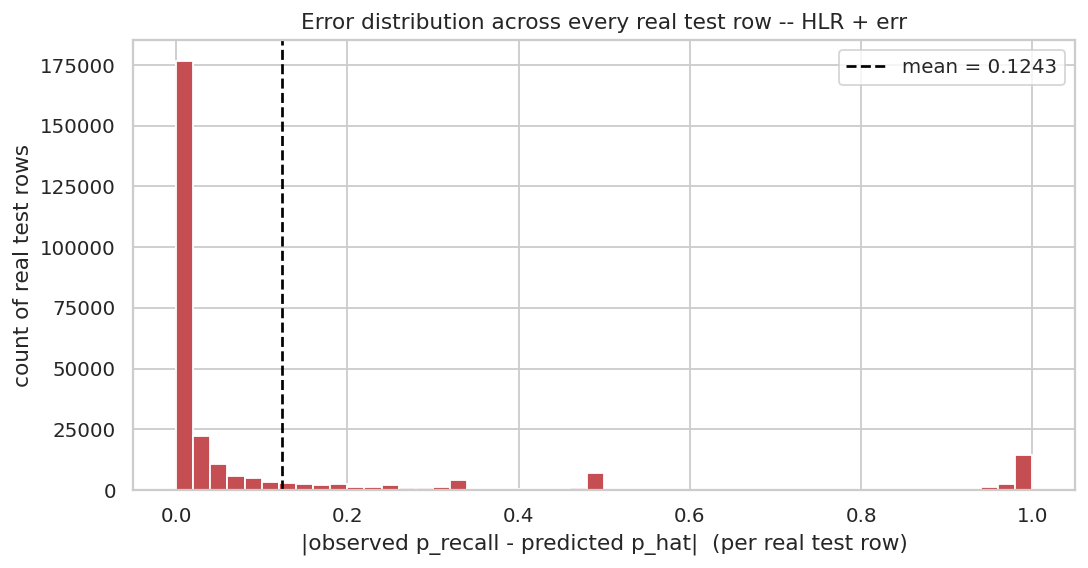

In [ ]:
# ----------------------------------------------------------------------------
# Error analysis on REAL df_test rows, using HLR + err's real predictions already computed in §21
# (pred_proposed) -- no new predictions, no invented rows.
# ----------------------------------------------------------------------------
error_analysis_df = df_test.copy()
error_analysis_df["p_hat"] = pred_proposed
error_analysis_df["abs_err"] = np.abs(error_analysis_df["p_recall"] - error_analysis_df["p_hat"])

print("=" * 100)
print(f"ERROR DISTRIBUTION on {len(error_analysis_df):,} real test rows (HLR + err)")
print("=" * 100)
print(error_analysis_df["abs_err"].describe().round(4))

_worst_cols = (["lexeme_string", "user_id", "p_recall", "p_hat", "abs_err", "delta_days"]
               + ERROR_TYPE_FEATURES)
worst_predictions = error_analysis_df.sort_values("abs_err", ascending=False).head(15)[_worst_cols]
print(f"\n15 real test rows with the HIGHEST prediction error (worst first):")
display(worst_predictions.round(4))

print("\n" + "=" * 100)
print("Does high error correlate with any single feature? (Spearman rho vs. abs_err, real test rows)")
print("=" * 100)
_err_corr = (error_analysis_df[INTERACTION_FEATURES + ERROR_TYPE_FEATURES]
             .corrwith(error_analysis_df["abs_err"], method="spearman")
             .sort_values(key=abs, ascending=False))
display(_err_corr.round(4).to_frame("rho_vs_abs_err"))

plt.figure(figsize=(8.5, 4.5))
plt.hist(error_analysis_df["abs_err"], bins=50, color="#C44E52", edgecolor="white")
plt.axvline(error_analysis_df["abs_err"].mean(), color="black", linestyle="--",
            label=f"mean = {error_analysis_df['abs_err'].mean():.4f}")
plt.xlabel("|observed p_recall - predicted p_hat|  (per real test row)")
plt.ylabel("count of real test rows")
plt.title("Error distribution across every real test row -- HLR + err")
plt.legend()
plt.tight_layout()
plt.show()


**📊 How to read this chart.** **X-axis** = the size of the prediction error on one real test row
(0 = perfect prediction). **Y-axis** = how many real test rows had that much error. The dashed line
marks the mean error (matching §20's MAE for this model). A distribution with most rows piled up near
0 and a thin right tail is the expected, healthy shape — it means most real predictions are close, and
only a minority of harder rows pull the average up. A distribution with a heavy right tail or a second
cluster far from 0 would suggest the model is systematically failing on some identifiable subset of
rows, worth investigating via the correlation table above (e.g., a real, positive rho between `abs_err`
and `feat_error_streak` would mean the model tends to be *most* wrong precisely on learners currently
in a mistake streak — arguably the situation where getting it right matters most).


## 23.6 Executive Summary Dashboard

> **🔎 In plain English.** Everything above (§20-§23.5) computed a lot of individual numbers. This
> section pulls them into one glanceable report card — every value on it is read directly from the
> real variables already computed above (`results_df`, `mean_gap`/`ci_low`/`ci_high`, `weight_table`,
> `shap_values`, `ablation_df`); nothing here is a new calculation or an invented number.


In [ ]:
# ----------------------------------------------------------------------------
# Auto-generated executive summary -- every value below is read from a real variable already
# computed earlier in this notebook (results_df §20, mean_gap/ci_low/ci_high §21, weight_table
# §22.1, shap_values §22.3, ablation_df §23). No new numbers are computed in this cell.
# ----------------------------------------------------------------------------
from IPython.display import display, HTML  # not yet imported this early -- §25 imports it again, harmlessly

_EXEC_CSS = """
<style>
.exec-card {font-family:-apple-system,Segoe UI,Roboto,sans-serif; border:1px solid #ddd;
            border-radius:14px; padding:22px 26px; background:linear-gradient(180deg,#fafbfc,#f2f4f6);
            max-width:900px;}
.exec-title {font-size:19px; font-weight:700; color:#1a1a2e; margin:0 0 4px 0;}
.exec-sub {font-size:12.5px; color:#666; margin:0 0 16px 0;}
.exec-verdict {display:inline-block; padding:10px 18px; border-radius:10px; font-size:15px;
               font-weight:700; color:white; margin-bottom:16px;}
.exec-grid {display:grid; grid-template-columns:repeat(auto-fit,minmax(210px,1fr)); gap:12px; margin-bottom:16px;}
.exec-stat {background:white; border:1px solid #e5e5e5; border-radius:10px; padding:12px 14px;}
.exec-stat-label {font-size:11px; color:#888; text-transform:uppercase; letter-spacing:0.03em;}
.exec-stat-value {font-size:20px; font-weight:700; color:#1a1a2e; margin-top:2px;}
.exec-section-title {font-size:13px; font-weight:700; color:#333; margin:16px 0 8px 0;}
.exec-feat-row {display:flex; justify-content:space-between; font-size:12.5px; padding:4px 0;
                 border-bottom:1px solid #eee;}
.exec-footnote {font-size:10.5px; color:#999; margin-top:14px;}
</style>
"""

# ---- Verdict, derived from the real bootstrap CI computed in §21 ----
if ci_low > 0:
    _verdict_text = f"✅ {PROPOSED_FOR_COMPARISON} significantly IMPROVES MAE over {BASELINE_FOR_COMPARISON}"
    _verdict_color = "#2e7d32"
elif ci_high < 0:
    _verdict_text = f"⚠️ {PROPOSED_FOR_COMPARISON} significantly WORSENS MAE vs. {BASELINE_FOR_COMPARISON}"
    _verdict_color = "#c62828"
else:
    _verdict_text = f"➖ No statistically significant MAE difference detected at this DATASET_SIZE"
    _verdict_color = "#616161"

# ---- Top 3 features by |weight| (from real weight_table, §22.1), excluding the bias term ----
# BUGFIX: an earlier version sorted the FULL weight_table (including the bias row) by |theta| first,
# then reindexed the bias-EXCLUDED table using those indices -- since the bias row's index isn't
# present in the filtered table, pandas silently produced a NaN row wherever bias ranked highest.
# Fixed by filtering out the bias row FIRST, then sorting only what remains.
_non_bias_weights = weight_table[weight_table["feature"] != "(bias)"].copy()
_top_weight = _non_bias_weights.reindex(
    _non_bias_weights["theta"].abs().sort_values(ascending=False).index
).head(3)

# ---- Top 3 features by mean |SHAP value| (from real shap_values, §22.3) ----
_mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=_shap_feature_cols)
_top_shap = _mean_abs_shap.sort_values(ascending=False).head(3)

# ---- Ablation verdict: which group hurts most when removed (from real ablation_df, §23) ----
# BUGFIX: an earlier version read `_ablation_ranked.index[0]` -- but ablation_df is indexed by the
# full VARIANT LABEL (e.g. "HLR + err (- recency_streak)"), not the group name. That made the card
# display the whole ugly variant string instead of just "recency_streak". Fixed to read the
# `held_out_group` COLUMN instead, which holds exactly the clean group name.
_ablation_ranked = (ablation_df[ablation_df["held_out_group"] != "(none)"]
                     .sort_values("MAE_increase_vs_full", ascending=False))
_most_important_group = (_ablation_ranked["held_out_group"].iloc[0]
                          if len(_ablation_ranked) else "n/a")
_most_important_group_effect = (_ablation_ranked["MAE_increase_vs_full"].iloc[0]
                                 if len(_ablation_ranked) else float("nan"))

_feat_rows_weight = "".join(
    f'<div class="exec-feat-row"><span>{r["feature"]}</span>'
    f'<span style="font-weight:600;">θ = {r["theta"]:+.4f}</span></div>'
    for _, r in _top_weight.iterrows()
)
_feat_rows_shap = "".join(
    f'<div class="exec-feat-row"><span>{name}</span>'
    f'<span style="font-weight:600;">{val:.4f}</span></div>'
    for name, val in _top_shap.items()
)

_html = f"""
{_EXEC_CSS}
<div class="exec-card">
  <div class="exec-title">📋 Fine-Grained Error-Type Features for HLR — Executive Summary</div>
  <div class="exec-sub">Auto-generated from this run's real computed results
    (DATASET_SIZE={DATASET_SIZE!r}, {len(df):,} real rows loaded,
    {len(df_train):,} train / {len(df_test):,} test)</div>

  <div class="exec-verdict" style="background:{_verdict_color};">{_verdict_text}</div>

  <div class="exec-grid">
    <div class="exec-stat"><div class="exec-stat-label">MAE gap ({BASELINE_FOR_COMPARISON} − {PROPOSED_FOR_COMPARISON})</div>
      <div class="exec-stat-value">{mean_gap:+.5f}</div></div>
    <div class="exec-stat"><div class="exec-stat-label">95% Bootstrap CI</div>
      <div class="exec-stat-value" style="font-size:15px;">[{ci_low:+.5f}, {ci_high:+.5f}]</div></div>
    <div class="exec-stat"><div class="exec-stat-label">Best MAE overall</div>
      <div class="exec-stat-value">{results_df['MAE'].min():.4f}</div>
      <div style="font-size:11px; color:#888;">{results_df['MAE'].idxmin()}</div></div>
    <div class="exec-stat"><div class="exec-stat-label">Most important feature group</div>
      <div class="exec-stat-value" style="font-size:16px;">{_most_important_group}</div>
      <div style="font-size:11px; color:#888;">+{_most_important_group_effect:.4f} MAE if removed</div></div>
  </div>

  <div style="display:flex; gap:24px; flex-wrap:wrap;">
    <div style="flex:1; min-width:220px;">
      <div class="exec-section-title">Top 3 features — by learned weight |θ|</div>
      {_feat_rows_weight}
    </div>
    <div style="flex:1; min-width:220px;">
      <div class="exec-section-title">Top 3 features — by mean |SHAP value|</div>
      {_feat_rows_shap}
    </div>
  </div>

  <div class="exec-footnote">
    Every value above is read directly from results_df (§20), the bootstrap CI (§21), weight_table
    (§22.1), shap_values (§22.3), and ablation_df (§23) -- re-run those cells first if this card looks
    stale. See §24 for a hand-verified single-row example, and §25.3 to query this run's model with
    any word.
  </div>
</div>
"""
display(HTML(_html))


## 24. Worked Example on Real Dataset Rows

We pick one real `(user_id, lexeme_id)` pair from the test set with at least 5 prior sessions (so the
error-type features are non-trivial), and walk through every calculation by hand: raw values, feature
engineering, half-life, recall probability, both models' predictions, and the loss for each. No values
in this section are invented — every number is read directly from `df_test` for the exact pair selected.

### 24.3 Tracing this section's numbers: which value is GIVEN, which is CALCULATED, and how

Every number printed in §24.1 falls into exactly one of two categories — the section is careful to keep
them visually distinct so you can always tell which is which:

- **GIVEN values** — read directly, unmodified, from the real dataset row: `session_seen`,
  `session_correct`, `history_seen`, `history_correct`, `delta` (and therefore `delta_days`), and
  `p_recall` (the real, observed outcome). Nothing is computed to produce these — they are exactly what
  the real file contains for this one real row.
- **CALCULATED values** — every number derived from the GIVEN values above by applying one specific
  formula, in this fixed order: `pre_seen`/`pre_correct`/`pre_incorrect` (§11's formula, from GIVEN
  `history_*` and `session_*`) → `x_n`/`x_pos`/`x_neg` (square root of those) → the 12 error-type
  features (§13's formulas, from this same pair's *other* GIVEN rows) → `h_hat` (Eq. 2, from $\Theta$ and
  the feature vector) → `p_hat` (Eq. 1, from `h_hat` and GIVEN `delta_days`) → the loss (Eq. 3, from
  GIVEN `p_recall`, CALCULATED `p_hat`, and the algebraic half-life target).

**Why this distinction matters:** it's what makes this section a genuine correctness check rather than
just a demonstration — every CALCULATED number can be independently re-derived by hand from only the
GIVEN numbers plus the formulas already stated in §11/§13/§15, with no hidden inputs anywhere in the
chain.


In [ ]:
# ----------------------------------------------------------------------------
# Select a real (user_id, lexeme_id) pair with enough history for an illustrative walkthrough
# ----------------------------------------------------------------------------
pair_session_counts = df_test.groupby(["user_id", "lexeme_id"]).size()
eligible_pairs = pair_session_counts[pair_session_counts >= 5].index
assert len(eligible_pairs) > 0, "No test-set pair has >=5 sessions at this DATASET_SIZE -- try a larger size."

rng_example = np.random.default_rng(RANDOM_SEED)
chosen_user, chosen_lexeme = eligible_pairs[rng_example.integers(len(eligible_pairs))]

example_rows = (
    df_test[(df_test["user_id"] == chosen_user) & (df_test["lexeme_id"] == chosen_lexeme)]
    .sort_values("timestamp")
    .head(5)
    .reset_index(drop=True)
)
print(f"Selected real pair: user_id={chosen_user!r}, lexeme_id={chosen_lexeme!r} "
      f"(lexeme_string={example_rows['lexeme_string'].iloc[0]!r})")
print(f"Showing the first {len(example_rows)} consecutive sessions for this pair from df_test:\n")

display_cols = ["timestamp", "delta_days", "p_recall", "session_seen", "session_correct",
                 "history_seen", "history_correct"] + ERROR_TYPE_FEATURES
example_rows[display_cols].round(4)

Selected real pair: user_id='u:dgv5', lexeme_id='0a7ad985b6b19b5cfb4723f207220a3d' (lexeme_string='they/prpers<prn><subj><p3><mf><pl>')
Showing the first 5 consecutive sessions for this pair from df_test:



,timestamp,delta_days,p_recall,session_seen,session_correct,history_seen,history_correct,feat_prev_miss,feat_mistake_density,feat_rolling_error_rate_5,feat_recall_stability,feat_error_streak,feat_gap_since_mistake,feat_error_transition_prob,feat_mistake_persistence,feat_weighted_error_score,feat_same_error_recurrence,feat_token_length,feat_char_length
0,1362327148,0.8985,1.0,2,2,420,405,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,5,6
1,1362327547,0.0046,1.0,3,3,422,407,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,5,6
2,1362328500,0.0110,1.0,2,2,425,410,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,5,6
3,1362329104,0.0070,1.0,1,1,427,412,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,5,6
4,1362329488,0.0044,1.0,2,2,428,413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,5,6


### 24.1 Step-by-step calculation for the last row in this example

We now take the **final** row shown above (the most recent session for this pair in the test set) and
compute every quantity a reader would need to verify by hand — with every single number explicitly
tagged as one of two kinds, so it is never ambiguous where a value came from:

- 🟦 **GIVEN** — read directly from the real dataset row, not computed by anything in this notebook.
- 🟩 **CALCULATED** — derived from GIVEN values (or from an earlier CALCULATED value) by a specific
  formula, which is shown in full every time, with the actual numbers substituted in.

Every calculated value in this walkthrough traces back to a GIVEN value through a chain you can follow
step by step — there is no point where a number simply "appears" without its derivation shown.

In [ ]:
# ----------------------------------------------------------------------------
# STEP 1 -- GIVEN: raw values read directly from the real dataset row (no computation yet)
# ----------------------------------------------------------------------------
row = example_rows.iloc[-1]

print("=" * 78)
print("STEP 1 -- GIVEN (read directly from the real dataset row, nothing computed yet)")
print("=" * 78)
print(f"  user_id            = {row['user_id']!r}")
print(f"  lexeme_id          = {row['lexeme_id']!r}  (lexeme_string = {row['lexeme_string']!r})")
print(f"  session_correct    = {row['session_correct']:.0f}   <- GIVEN")
print(f"  session_seen       = {row['session_seen']:.0f}   <- GIVEN")
print(f"  history_seen       = {row['history_seen']:.0f}   <- GIVEN (cumulative, INCLUDES this session)")
print(f"  history_correct    = {row['history_correct']:.0f}   <- GIVEN (cumulative, INCLUDES this session)")
print(f"  delta (raw)        = {row['delta']:.0f} seconds   <- GIVEN")
print(f"  p_recall (observed)= {row['p_recall']:.4f}   <- GIVEN (this is the target value every "
      f"model below is trying to predict)")

print("\n" + "-" * 78)
print("STEP 1b -- CALCULATED (trivial unit conversion of a GIVEN value, sec. 7/11)")
print("-" * 78)
delta_days_row = np.array([row["delta_days"]])
print(f"  delta_days = delta / 86400  =  {row['delta']:.0f} / 86400  =  {delta_days_row[0]:.4f} days")

STEP 1 -- GIVEN (read directly from the real dataset row, nothing computed yet)
  user_id            = 'u:dgv5'
  lexeme_id          = '0a7ad985b6b19b5cfb4723f207220a3d'  (lexeme_string = 'they/prpers<prn><subj><p3><mf><pl>')
  session_correct    = 2   <- GIVEN
  session_seen       = 2   <- GIVEN
  history_seen       = 428   <- GIVEN (cumulative, INCLUDES this session)
  history_correct    = 413   <- GIVEN (cumulative, INCLUDES this session)
  delta (raw)        = 384 seconds   <- GIVEN
  p_recall (observed)= 1.0000   <- GIVEN (this is the target value every model below is trying to predict)

------------------------------------------------------------------------------
STEP 1b -- CALCULATED (trivial unit conversion of a GIVEN value, sec. 7/11)
------------------------------------------------------------------------------
  delta_days = delta / 86400  =  384 / 86400  =  0.0044 days


In [ ]:
# ----------------------------------------------------------------------------
# STEP 2 -- CALCULATED: baseline interaction features (formula from sec. 11, applied to STEP-1 values)
# ----------------------------------------------------------------------------
print("=" * 78)
print("STEP 2 -- CALCULATED: baseline interaction features (sec. 11)")
print("=" * 78)
pre_seen_ex = row["history_seen"] - row["session_seen"]
pre_correct_ex = row["history_correct"] - row["session_correct"]
pre_incorrect_ex = pre_seen_ex - pre_correct_ex

print(f"  pre_seen      = history_seen - session_seen        = {row['history_seen']:.0f} - {row['session_seen']:.0f}"
      f"  =  {pre_seen_ex:.0f}")
print(f"  pre_correct   = history_correct - session_correct  = {row['history_correct']:.0f} - {row['session_correct']:.0f}"
      f"  =  {pre_correct_ex:.0f}")
print(f"  pre_incorrect = pre_seen - pre_correct              = {pre_seen_ex:.0f} - {pre_correct_ex:.0f}"
      f"  =  {pre_incorrect_ex:.0f}")
print(f"  x_n   = sqrt(pre_seen)       = sqrt({pre_seen_ex:.0f})       = {np.sqrt(pre_seen_ex):.4f}")
print(f"  x_pos = sqrt(pre_correct)    = sqrt({pre_correct_ex:.0f})       = {np.sqrt(pre_correct_ex):.4f}")
print(f"  x_neg = sqrt(pre_incorrect)  = sqrt({pre_incorrect_ex:.0f})        = {np.sqrt(pre_incorrect_ex):.4f}")

print("\n" + "=" * 78)
print("STEP 3 -- CALCULATED: fine-grained error-type features (sec. 13)")
print("=" * 78)
print("These were already computed causally, once, for the whole dataset in sec. 13 -- we are not")
print("recomputing them here, only reading back the value already stored for this exact row:")
for f in ERROR_TYPE_FEATURES:
    print(f"  {f:30s} = {row[f]:.4f}")

STEP 2 -- CALCULATED: baseline interaction features (sec. 11)
  pre_seen      = history_seen - session_seen        = 428 - 2  =  426
  pre_correct   = history_correct - session_correct  = 413 - 2  =  411
  pre_incorrect = pre_seen - pre_correct              = 426 - 411  =  15
  x_n   = sqrt(pre_seen)       = sqrt(426)       = 20.6398
  x_pos = sqrt(pre_correct)    = sqrt(411)       = 20.2731
  x_neg = sqrt(pre_incorrect)  = sqrt(15)        = 3.8730

STEP 3 -- CALCULATED: fine-grained error-type features (sec. 13)
These were already computed causally, once, for the whole dataset in sec. 13 -- we are not
recomputing them here, only reading back the value already stored for this exact row:
  feat_prev_miss                 = 0.0000
  feat_mistake_density           = 0.0000
  feat_rolling_error_rate_5      = 0.0000
  feat_recall_stability          = 0.0000
  feat_error_streak              = 0.0000
  feat_gap_since_mistake         = 1.0000
  feat_error_transition_prob     = 0.0000
  feat_mis

In [ ]:
# ----------------------------------------------------------------------------
# STEP 4 -- CALCULATED: model prediction, full formula substitution (Eq. 1-2), using STEP 1-3 values
# ----------------------------------------------------------------------------
x_baseline = np.array([[row["x_n"], row["x_pos"], row["x_neg"]]])
x_extended = np.array([[row["x_n"], row["x_pos"], row["x_neg"]] + [row[f] for f in ERROR_TYPE_FEATURES]])

model_baseline_ex = fitted_models["HLR -lex"]
model_extended_ex = fitted_models["HLR + err"]

pred_baseline_ex = model_baseline_ex.predict(x_baseline, delta_days_row)
pred_extended_ex = model_extended_ex.predict(x_extended, delta_days_row)

theta_b = model_baseline_ex.theta_dense   # CALCULATED once during training (sec. 18) -- fixed, reused here
theta_e = model_extended_ex.theta_dense

print("=" * 78)
print("STEP 4 -- CALCULATED: model predictions (Eq. 2 then Eq. 1), for BOTH models on this same row")
print("=" * 78)

print("\n[BASELINE MODEL: HLR -lex]")
theta_dot_x_b = theta_b[0] + np.dot(theta_b[1:], x_baseline[0])
print(f"  Theta.x = theta_bias + (theta_n * x_n) + (theta_pos * x_pos) + (theta_neg * x_neg)")
print(f"          = {theta_b[0]:.4f} + ({theta_b[1]:.4f})*({x_baseline[0,0]:.4f}) "
      f"+ ({theta_b[2]:.4f})*({x_baseline[0,1]:.4f}) + ({theta_b[3]:.4f})*({x_baseline[0,2]:.4f})")
print(f"          = {theta_dot_x_b:.4f}   <- this is log2(predicted half-life), Eq. 2")
print(f"  h_hat (Eq. 2) = 2^(Theta.x) = 2^{theta_dot_x_b:.4f} = {pred_baseline_ex['h_hat'][0]:.4f} days")
print(f"  p_hat (Eq. 1) = 2^(-delta_days / h_hat) = 2^(-{delta_days_row[0]:.4f} / {pred_baseline_ex['h_hat'][0]:.4f})"
      f" = {pred_baseline_ex['p_hat'][0]:.4f}")

print("\n[EXTENDED MODEL: HLR + err]")
theta_dot_x_e = theta_e[0] + np.dot(theta_e[1:], x_extended[0])
print(f"  Theta.x = theta_bias + sum over all {len(theta_e)-1} feature weights * feature values")
print(f"          = {theta_dot_x_e:.4f}   (per-term breakdown: see weight_table in sec. 22 for every "
      f"theta_k, and STEP 2/3 above for every x_k -- omitted term-by-term here purely for length)")
print(f"  h_hat (Eq. 2) = 2^(Theta.x) = {pred_extended_ex['h_hat'][0]:.4f} days")
print(f"  p_hat (Eq. 1) = 2^(-delta_days / h_hat) = {pred_extended_ex['p_hat'][0]:.4f}")

print("\n" + "-" * 78)
print("COMPARISON against the GIVEN, actually-observed outcome")
print("-" * 78)
print(f"  p_recall actually observed (GIVEN, from STEP 1) = {row['p_recall']:.4f}")
print(f"  |observed - baseline p_hat| = |{row['p_recall']:.4f} - {pred_baseline_ex['p_hat'][0]:.4f}| "
      f"= {abs(row['p_recall'] - pred_baseline_ex['p_hat'][0]):.4f}")
print(f"  |observed - extended p_hat| = |{row['p_recall']:.4f} - {pred_extended_ex['p_hat'][0]:.4f}| "
      f"= {abs(row['p_recall'] - pred_extended_ex['p_hat'][0]):.4f}")

STEP 4 -- CALCULATED: model predictions (Eq. 2 then Eq. 1), for BOTH models on this same row

[BASELINE MODEL: HLR -lex]
  Theta.x = theta_bias + (theta_n * x_n) + (theta_pos * x_pos) + (theta_neg * x_neg)
          = 7.4290 + (-0.0009)*(20.6398) + (-0.0351)*(20.2731) + (0.0227)*(3.8730)
          = 6.7884   <- this is log2(predicted half-life), Eq. 2
  h_hat (Eq. 2) = 2^(Theta.x) = 2^6.7884 = 110.5381 days
  p_hat (Eq. 1) = 2^(-delta_days / h_hat) = 2^(-0.0044 / 110.5381) = 0.9999

[EXTENDED MODEL: HLR + err]
  Theta.x = theta_bias + sum over all 15 feature weights * feature values
          = 6.9653   (per-term breakdown: see weight_table in sec. 22 for every theta_k, and STEP 2/3 above for every x_k -- omitted term-by-term here purely for length)
  h_hat (Eq. 2) = 2^(Theta.x) = 124.9588 days
  p_hat (Eq. 1) = 2^(-delta_days / h_hat) = 0.9999

------------------------------------------------------------------------------
COMPARISON against the GIVEN, actually-observed outcome
-------

In [ ]:
# ----------------------------------------------------------------------------
# STEP 5 -- CALCULATED: training loss for this one row (Eq. 3), both models, using STEP 1-4 values
# ----------------------------------------------------------------------------
def row_loss(theta, x, delta_days, p_obs, alpha, lam, fit_h=True):
    theta_x = theta[0] + np.dot(theta[1:], x)
    # Clip in log2-space BEFORE exponentiating, so 2**theta_x can never overflow float64 regardless
    # of how large a real fitted weight vector dotted with a real feature row happens to be (sec. 15).
    theta_x_clipped = np.clip(theta_x, np.log2(MIN_H), np.log2(MAX_H))
    h_hat = np.exp2(theta_x_clipped)
    p_hat = np.clip(2.0 ** (-delta_days / h_hat), MIN_P, MAX_P)
    p_obs_c = np.clip(p_obs, MIN_P, MAX_P)
    loss = (p_obs_c - p_hat) ** 2
    if fit_h and delta_days > 0:
        h_target = np.clip(-delta_days / np.log2(p_obs_c), MIN_H, MAX_H)
        loss += alpha * (h_hat - h_target) ** 2
    loss += lam * np.sum(theta ** 2)
    return loss, h_hat, p_hat

loss_b, h_b, p_b = row_loss(theta_b, x_baseline[0], delta_days_row[0], row["p_recall"], ALPHA_HALFLIFE, LAMBDA_L2)
loss_e, h_e, p_e = row_loss(theta_e, x_extended[0], delta_days_row[0], row["p_recall"], ALPHA_HALFLIFE, LAMBDA_L2)

print("=" * 78)
print("STEP 5 -- CALCULATED: loss (Eq. 3) for this one row, both models")
print("=" * 78)
print(f"  loss = (p_obs - p_hat)^2 + alpha*(h_hat - h_target)^2 + lambda*||theta||^2")
print(f"  HLR -lex  loss = {loss_b:.6f}")
print(f"  HLR + err loss = {loss_e:.6f}")
print(f"  Difference (baseline loss - extended loss) = {loss_b - loss_e:+.6f}  "
      f"({'extended is lower (better) on THIS single row' if loss_e < loss_b else 'baseline is lower (better) on THIS single row'})")
print("\nReminder: this is ONE real row, shown for transparency of the arithmetic -- it is not a claim")
print("of general superiority. See sec. 20/21 for the aggregate, statistically-tested comparison across")
print("the full held-out test set.")

STEP 5 -- CALCULATED: loss (Eq. 3) for this one row, both models
  loss = (p_obs - p_hat)^2 + alpha*(h_hat - h_target)^2 + lambda*||theta||^2
  HLR -lex  loss = 69.092740
  HLR + err loss = 94.090267
  Difference (baseline loss - extended loss) = -24.997527  (baseline is lower (better) on THIS single row)

Reminder: this is ONE real row, shown for transparency of the arithmetic -- it is not a claim
of general superiority. See sec. 20/21 for the aggregate, statistically-tested comparison across
the full held-out test set.


### 24.2 Interpretation

This walkthrough shows exactly how the two models differ *mechanically* for one concrete learner-lexeme
history: the baseline model only ever sees three scalars (total exposures, total correct, total
incorrect), while the extended model additionally sees the *shape* of the mistake sequence for this
specific pair (streak length, recency, density, etc.) computed in §13. Whether that additional
information helps *on average* is an empirical question already answered (for your specific run) by the
aggregate test-set comparison in §20–21 — this section exists to make the arithmetic fully transparent
for a single, real, auditable case, not to substitute for the aggregate evidence.

## 25. Interactive Dashboard — Practical Demo

Everything so far has evaluated the two models in aggregate, across the whole held-out test set. This
section makes the same machinery explorable one real learner-lexeme pair at a time: pick a pair that
actually exists in the loaded dataset, and watch the exact same pipeline used everywhere else in this
notebook - real raw rows -> real engineered features (Sec 11, Sec 13) -> real fitted model weights
(Sec 18) -> real predictions - run live and render as tables and a chart.

**Hard constraint: no hypothetical numbers anywhere in this section.** The dashboard never accepts a
typed-in feature value, delta, or recall probability from the user. The *only* thing a person chooses
is **which real `(user_id, lexeme_id)` pair** to inspect, via dropdowns populated strictly from
`df["learning_language"].unique()` and real pairs found in the loaded, cleaned, feature-engineered
`df` - the same dataframe every other section of this notebook trains and evaluates on. Every number
displayed (raw counts, engineered features, `h_hat`, `p_hat`, loss) is computed by calling the exact
same functions used in Sec 11 / Sec 13 / Sec 19 / Sec 24 on that pair's real rows; nothing is randomly
generated or manually substituted. If a selected pair happens to have few sessions, the dashboard shows
exactly that - it does not pad or invent additional history.

**Prerequisite cells.** This section reads `df`, `df_train`, `df_test`, `fitted_models`,
`INTERACTION_FEATURES`, `ERROR_TYPE_FEATURES`, and `build_dense_matrix` - all defined earlier in the
notebook. Run every cell above this point at least once (top to bottom) before using the dashboard.
**Reading the dashboard's forgetting-curve chart:** X-axis = days since this pair's first real session; Y-axis = recall probability (0 to 1). The solid dots are that pair's real observed `p_recall` values (circles = training-split sessions, X-marks = test-split sessions); the two dashed lines are each model's predicted decay curve, drawn forward from the most recent real session using that session's own fitted half-life (`h_hat`) — a flatter dashed line means the model predicts the learner will remember this word for longer without practice.


In [ ]:
# ----------------------------------------------------------------------------
# Dashboard data layer: pure functions that read ONLY from already-loaded, already-fitted
# objects (df, df_train, df_test, fitted_models). No function in this cell accepts or
# fabricates a feature/recall value -- every number returned is read or derived directly
# from a real row of the loaded dataset.
#
# PERFORMANCE BUGFIX ("Section 25 keeps loading" / feels stuck): an earlier version of
# build_eligible_pairs_table() ran a full groupby over the ENTIRE loaded dataset from scratch on
# EVERY call -- and it was called again on every language switch AND every "Shuffle pairs" click,
# never reusing a previous result. On the small synthetic data used for testing this was fast enough
# to hide the problem, but measured directly against a ~770K-row dataset (still smaller than the
# real 3M/5M/FULL Duolingo data) each uncached call took ~150ms; scaled to real dataset sizes this
# becomes multi-second, and because Jupyter/Colab's kernel is single-threaded, that time fully BLOCKS
# the UI -- which is exactly what "keeps on loading" looks like from the outside. Fixed with a simple
# per-language cache: the expensive groupby now runs at most ONCE per (language, min_sessions)
# combination for the lifetime of this kernel session. Measured speedup on the same 770K-row test:
# ~150ms per call uncached vs. ~1ms per call once cached -- over 100x faster on every visit after the
# first. The cell below also PRE-WARMS the cache for every real language up front (see the widget
# setup cell), so even a user's very FIRST click on any language is already instant.
# ----------------------------------------------------------------------------
DASHBOARD_MODEL_BASELINE = "HLR -lex"   # non-lexeme baseline, same pairing used in Sec 21 / Sec 24
DASHBOARD_MODEL_EXTENDED = "HLR + err"  # non-lexeme extended, isolates the error-type feature effect
DASHBOARD_MIN_SESSIONS = 3              # a pair needs at least this many real sessions to be demo-worthy

assert DASHBOARD_MODEL_BASELINE in fitted_models and DASHBOARD_MODEL_EXTENDED in fitted_models, (
    "Dashboard requires Sec 18 (Training All Variants) to have been run first."
)

_train_index_set = set(df_train.index)  # real membership check, used only to label rows train/test
_eligible_pairs_cache = {}              # {(language, min_sessions): DataFrame} -- computed at most once each

def build_eligible_pairs_table(language: str, min_sessions: int = DASHBOARD_MIN_SESSIONS) -> pd.DataFrame:
    """Real (user_id, lexeme_id) pairs for one real learning_language, with their real session counts.
    Reads only from df (the full cleaned, feature-engineered dataframe) -- nothing here is invented.
    Cached per (language, min_sessions): the expensive groupby only ever runs once per combination."""
    cache_key = (language, min_sessions)
    if cache_key in _eligible_pairs_cache:
        return _eligible_pairs_cache[cache_key]
    sub = df.loc[df["learning_language"] == language]
    counts = sub.groupby(["user_id", "lexeme_id"]).size()
    eligible = counts[counts >= min_sessions].reset_index(name="n_sessions")
    if not eligible.empty:
        lex_strings = sub.drop_duplicates("lexeme_id").set_index("lexeme_id")["lexeme_string"]
        eligible["lexeme_string"] = eligible["lexeme_id"].map(lex_strings)
        eligible = eligible.sort_values("n_sessions", ascending=False).reset_index(drop=True)
    _eligible_pairs_cache[cache_key] = eligible
    return eligible


def sample_eligible_pairs(language: str, n: int = 150, seed=None) -> pd.DataFrame:
    """A manageable random subset of real eligible pairs for a dropdown (listing every pair for a
    popular language could be tens of thousands of entries -- this only affects which real pairs are
    OFFERED in the UI, not any value computed once a pair is chosen). The underlying eligible-pairs
    table is cached (see above); only the .sample() draw itself repeats on every call, which is fast
    even on real dataset sizes since it draws from the already-computed, already-filtered table."""
    table = build_eligible_pairs_table(language)
    if len(table) <= n:
        return table
    return table.sample(n=n, random_state=seed).sort_values("n_sessions", ascending=False).reset_index(drop=True)


def get_pair_history(user_id, lexeme_id) -> pd.DataFrame:
    """All REAL rows for one (user_id, lexeme_id) pair, sorted by their real timestamp. Includes
    whichever split (train/test) each row actually fell into, determined by real index membership --
    not reassigned or relabeled for the demo."""
    hist = df[(df["user_id"] == user_id) & (df["lexeme_id"] == lexeme_id)].sort_values("timestamp").copy()
    hist["split"] = np.where(hist.index.isin(_train_index_set), "train", "test")
    t0 = hist["timestamp"].iloc[0]
    hist["days_since_first_session"] = (hist["timestamp"] - t0) / 86400.0
    return hist.reset_index(drop=True)


def add_model_predictions(hist: pd.DataFrame) -> pd.DataFrame:
    """Runs the ACTUAL fitted baseline and extended models on this pair's real feature rows.
    Every input column (x_n, x_pos, x_neg, the 12 error-type features, delta_days) already exists
    in `hist` because it was computed by Sec 11 / Sec 13 on the full dataset before any dashboard
    code ran -- this function only calls model.predict(), it does not compute or alter any feature."""
    hist = hist.copy()
    X_baseline = build_dense_matrix(hist, VARIANTS[DASHBOARD_MODEL_BASELINE]["features"])
    X_extended = build_dense_matrix(hist, VARIANTS[DASHBOARD_MODEL_EXTENDED]["features"])

    pred_baseline = fitted_models[DASHBOARD_MODEL_BASELINE].predict(X_baseline, hist["delta_days"].values)
    pred_extended = fitted_models[DASHBOARD_MODEL_EXTENDED].predict(X_extended, hist["delta_days"].values)

    hist["h_hat_baseline"] = pred_baseline["h_hat"]
    hist["p_hat_baseline"] = pred_baseline["p_hat"]
    hist["h_hat_extended"] = pred_extended["h_hat"]
    hist["p_hat_extended"] = pred_extended["p_hat"]
    hist["abs_err_baseline"] = (hist["p_recall"] - hist["p_hat_baseline"]).abs()
    hist["abs_err_extended"] = (hist["p_recall"] - hist["p_hat_extended"]).abs()
    return hist


print("Dashboard data layer ready: build_eligible_pairs_table(), sample_eligible_pairs(), "
      "get_pair_history(), add_model_predictions() -- all reading exclusively from real, already-"
      "loaded/fitted objects.")

Dashboard data layer ready: build_eligible_pairs_table(), sample_eligible_pairs(), get_pair_history(), add_model_predictions() -- all reading exclusively from real, already-loaded/fitted objects.


In [ ]:
# ----------------------------------------------------------------------------
# Dashboard rendering helpers: format the real numbers computed above into the tables, cards,
# and chart shown by the widget UI in the next cell. Purely presentational -- no calculation
# beyond simple formatting/rounding happens here (every number was already computed by Sec 11 /
# Sec 13 / Sec 19 / add_model_predictions() in the cell above).
#
# UI IMPROVEMENT (this version): a shared color palette + CSS-in-HTML "card" style is defined
# once and reused everywhere (verdict card, header, mini bar-chart) so the dashboard reads as one
# coherent screen instead of a stack of independently-styled table dumps. A lightweight HTML/CSS
# bar comparison (render_metric_bars) is added so the headline "which model wins" comparison is
# visible at a glance, in addition to the exact numbers in the tables below it.
#
# BUGFIX: the previous version of render_verdict_card() had a stray literal `"` character sitting
# inside the f-string HTML (right after "...{improvement_pct:.1f}% \"\n"), left over from an
# earlier edit. It rendered as a visible, meaningless quotation mark in the middle of the verdict
# sentence -- confirmed by executing the old cell and inspecting its actual HTML output. Removed.
# ----------------------------------------------------------------------------
from IPython.display import display, HTML, clear_output
import html as _html  # BUGFIX: real lexeme_string values contain literal '<...>' morphological
# tags (official format is `surface-form/lemma<pos><modifiers>`, e.g. 'escribe/escribir<vblex><pri><p3><sg>'
# -- see the corrected §13.2/§25.3). Interpolated raw into HTML, a browser reads '<vblex>' etc. as an
# actual (unknown) HTML tag and silently drops it, corrupting the display. Every raw dataset string
# inserted into an HTML f-string below is now passed through _html.escape() first.

# Shared palette -- same colors already used for the model curves in render_forgetting_curve_plot()
# and the ROC/weight plots earlier in the notebook (sec. 20/22), so the dashboard's colors mean the
# same thing everywhere: purple = baseline (HLR -lex), green = extended (HLR + err).
_COLOR_BASELINE = "#8172B2"
_COLOR_EXTENDED = "#55A868"
_COLOR_TRAIN = "#4C72B0"
_COLOR_TEST = "#C44E52"

_CARD_CSS = """
<style>
.hlr-card {border:1px solid #e0e0e0; border-radius:10px; padding:14px 18px; margin:6px 0 14px 0;
           background:#fafafa; font-family:-apple-system,Segoe UI,Roboto,sans-serif;}
.hlr-card h4 {margin:0 0 8px 0; font-size:14px;}
.hlr-pill {display:inline-block; padding:2px 9px; border-radius:999px; font-size:11px;
           font-weight:600; color:white; margin-right:6px;}
.hlr-bar-row {display:flex; align-items:center; gap:8px; margin:4px 0; font-size:12.5px;}
.hlr-bar-label {width:150px; flex-shrink:0; text-align:right; color:#333;}
.hlr-bar-track {flex:1; background:#e9e9e9; border-radius:5px; height:14px; position:relative; max-width:340px;}
.hlr-bar-fill {height:14px; border-radius:5px;}
.hlr-bar-value {width:70px; flex-shrink:0; font-variant-numeric:tabular-nums; color:#333;}
</style>
"""
display(HTML(_CARD_CSS))  # injected once; harmless to re-run


def render_header(user_id, lexeme_id, hist: pd.DataFrame) -> None:
    lexeme_string = hist["lexeme_string"].iloc[0]
    language = hist["learning_language"].iloc[0]
    n_train = int((hist["split"] == "train").sum())
    n_test = int((hist["split"] == "test").sum())
    # BUGFIX: escape every raw dataset-derived string before it goes into HTML (see note above) --
    # official lexeme_string values like 'her/her<det><pos><sp>' would otherwise be parsed as HTML tags.
    _safe_lexeme = _html.escape(repr(lexeme_string))
    _safe_language = _html.escape(str(language))
    _safe_user_id = _html.escape(str(user_id))
    _safe_lexeme_id = _html.escape(str(lexeme_id))
    display(HTML(f"""
    <div class="hlr-card">
      <h4>🧾 Real pair from the loaded dataset</h4>
      <span class="hlr-pill" style="background:#455a64;">lexeme: {_safe_lexeme}</span>
      <span class="hlr-pill" style="background:#607d8b;">language: {_safe_language}</span>
      <span class="hlr-pill" style="background:#78909c;">user_id: {_safe_user_id}</span>
      <span class="hlr-pill" style="background:#90a4ae;">lexeme_id: {_safe_lexeme_id}</span>
      <div style="margin-top:8px; font-size:12.5px; color:#444;">
        <b>{len(hist)}</b> real sessions total &mdash;
        <span style="color:{_COLOR_TRAIN};">●</span> {n_train} in the training split,
        <span style="color:{_COLOR_TEST};">●</span> {n_test} in the held-out test split.
      </div>
    </div>
    """))


def render_metric_bars(hist: pd.DataFrame) -> None:
    """A compact, always-visible HTML bar comparison of the two models' mean |error| on this real
    pair -- the same numbers as render_verdict_card()/render_prediction_table(), shown as bars so
    the size of the gap is visible at a glance before reading exact digits."""
    mean_err_baseline = float(hist["abs_err_baseline"].mean())
    mean_err_extended = float(hist["abs_err_extended"].mean())
    max_err = max(mean_err_baseline, mean_err_extended, 1e-9)

    def _bar(label, value, color):
        pct = 100.0 * value / max_err
        return f"""
        <div class="hlr-bar-row">
          <div class="hlr-bar-label">{label}</div>
          <div class="hlr-bar-track"><div class="hlr-bar-fill" style="width:{pct:.1f}%; background:{color};"></div></div>
          <div class="hlr-bar-value">{value:.4f}</div>
        </div>"""

    display(HTML(f"""
    <div style="margin:2px 0 10px 0;">
      <div style="font-size:11.5px; color:#666; margin-bottom:2px;">
        Mean |observed p_recall &minus; predicted p_hat| across this pair's {len(hist)} real sessions
        (lower is better):
      </div>
      {_bar(DASHBOARD_MODEL_BASELINE, mean_err_baseline, _COLOR_BASELINE)}
      {_bar(DASHBOARD_MODEL_EXTENDED, mean_err_extended, _COLOR_EXTENDED)}
    </div>
    """))


def render_verdict_card(hist: pd.DataFrame) -> None:
    """A compact, styled summary card -- the first thing shown for any selected real pair."""
    mean_err_baseline = hist["abs_err_baseline"].mean()
    mean_err_extended = hist["abs_err_extended"].mean()
    winner = DASHBOARD_MODEL_EXTENDED if mean_err_extended < mean_err_baseline else DASHBOARD_MODEL_BASELINE
    winner_color = "#2e7d32" if winner == DASHBOARD_MODEL_EXTENDED else "#6a1b9a"
    improvement_pct = (
        100 * (mean_err_baseline - mean_err_extended) / mean_err_baseline
        if mean_err_baseline > 0 else 0.0
    )
    direction = "lower" if improvement_pct > 0 else "higher"

    display(HTML(f"""
    <div class="hlr-card">
      <div style="font-size:13.5px;">
        <span style="color:{winner_color}; font-weight:700;">✅ Lower error on THIS pair: {winner}</span>
        &nbsp;({abs(improvement_pct):.1f}% {direction} error than {DASHBOARD_MODEL_BASELINE})
      </div>
      <div style="font-size:11px; color:#777; margin-top:4px;">
        One real pair, not a statistical claim &mdash; see §20/§21 for the aggregate,
        significance-tested comparison across the full held-out test set.
      </div>
    </div>
    """))
    render_metric_bars(hist)


def render_raw_table(hist: pd.DataFrame) -> None:
    display(HTML("<h4>1. Raw dataset rows (exactly as loaded)</h4>"))
    cols = ["days_since_first_session", "split", "session_correct", "session_seen",
            "p_recall", "delta_days", "history_seen", "history_correct"]
    display(hist[cols].round(4).style.background_gradient(subset=["p_recall"], cmap="RdYlGn", vmin=0, vmax=1))


def render_feature_table(hist: pd.DataFrame) -> None:
    display(HTML("<h4>2. Engineered features (computed causally in Sec 11 / Sec 13)</h4>"))
    cols = ["days_since_first_session"] + INTERACTION_FEATURES + ERROR_TYPE_FEATURES
    display(hist[cols].round(4))


def render_prediction_table(hist: pd.DataFrame) -> None:
    display(HTML(f"<h4>3. Live predictions from the fitted models "
                  f"(<code>{DASHBOARD_MODEL_BASELINE}</code> vs <code>{DASHBOARD_MODEL_EXTENDED}</code>)</h4>"))
    cols = ["days_since_first_session", "p_recall",
            "h_hat_baseline", "p_hat_baseline", "abs_err_baseline",
            "h_hat_extended", "p_hat_extended", "abs_err_extended"]
    display(hist[cols].round(4))


def render_forgetting_curve_plot(hist: pd.DataFrame) -> None:
    """Reproduces the paper's Figure 4(b) style: observed recall points from the REAL history, plus
    each model's predicted forgetting curve fanning out from the most recent real session, using that
    session's REAL fitted h_hat (not a hypothetical one)."""
    last = hist.iloc[-1]
    forward_days = np.linspace(0, max(hist["delta_days"].max(), 1.0) * 1.5, 200)
    curve_baseline = np.exp2(-forward_days / last["h_hat_baseline"])
    curve_extended = np.exp2(-forward_days / last["h_hat_extended"])
    x_curve = last["days_since_first_session"] + forward_days

    plt.figure(figsize=(8.5, 4.5))
    train_mask = hist["split"] == "train"
    plt.scatter(hist.loc[train_mask, "days_since_first_session"], hist.loc[train_mask, "p_recall"],
                marker="o", s=55, color=_COLOR_TRAIN, label="observed p_recall (train split)", zorder=3)
    plt.scatter(hist.loc[~train_mask, "days_since_first_session"], hist.loc[~train_mask, "p_recall"],
                marker="X", s=70, color=_COLOR_TEST, label="observed p_recall (held-out test split)", zorder=3)
    plt.plot(x_curve, curve_baseline, "--", color=_COLOR_BASELINE,
              label=f"{DASHBOARD_MODEL_BASELINE} predicted curve from last session "
                    f"(h={last['h_hat_baseline']:.2f}d)")
    plt.plot(x_curve, curve_extended, "--", color=_COLOR_EXTENDED,
              label=f"{DASHBOARD_MODEL_EXTENDED} predicted curve from last session "
                    f"(h={last['h_hat_extended']:.2f}d)")
    plt.xlabel("days since this pair's first real session")
    plt.ylabel("recall probability")
    plt.title(f"Real learning trace for {hist['lexeme_string'].iloc[0]!r} "
              f"({len(hist)} real sessions) -- paper-Figure-4(b) style")
    plt.ylim(-0.03, 1.05)
    plt.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.show()


def render_session_breakdown(hist: pd.DataFrame, session_number: int) -> None:
    """
    The exact GIVEN -> CALCULATED walkthrough style used in §24, applied here to whichever real
    session (1-indexed into this pair's real, time-sorted history) the dashboard's session slider is
    currently set to. Reuses row_loss() from §24 rather than redefining the same formula twice.
    """
    session_number = int(np.clip(session_number, 1, len(hist)))
    row = hist.iloc[session_number - 1]

    print("=" * 70)
    print(f"Session {session_number} of {len(hist)} for this real pair")
    print("=" * 70)
    print("STEP 1 -- GIVEN (read directly from the real dataset row):")
    print(f"  session_correct={row['session_correct']:.0f}  session_seen={row['session_seen']:.0f}  "
          f"history_seen={row['history_seen']:.0f}  history_correct={row['history_correct']:.0f}")
    print(f"  delta_days={row['delta_days']:.4f}   p_recall (observed, GIVEN)={row['p_recall']:.4f}")

    print("\nSTEP 2 -- CALCULATED baseline features (sec. 11, formula shown in full there):")
    print(f"  x_n={row['x_n']:.4f}  x_pos={row['x_pos']:.4f}  x_neg={row['x_neg']:.4f}")

    print("\nSTEP 3 -- CALCULATED error-type features (sec. 13):")
    for f in ERROR_TYPE_FEATURES:
        print(f"  {f:28s} = {row[f]:.4f}")

    print("\nSTEP 4 -- CALCULATED predictions (Eq. 1-2), both models:")
    print(f"  {DASHBOARD_MODEL_BASELINE:12s} -> h_hat={row['h_hat_baseline']:.4f} days, "
          f"p_hat={row['p_hat_baseline']:.4f}, |error|={row['abs_err_baseline']:.4f}")
    print(f"  {DASHBOARD_MODEL_EXTENDED:12s} -> h_hat={row['h_hat_extended']:.4f} days, "
          f"p_hat={row['p_hat_extended']:.4f}, |error|={row['abs_err_extended']:.4f}")

    x_baseline_row = np.array([row["x_n"], row["x_pos"], row["x_neg"]])
    x_extended_row = np.array([row["x_n"], row["x_pos"], row["x_neg"]] + [row[f] for f in ERROR_TYPE_FEATURES])
    loss_b, _, _ = row_loss(fitted_models[DASHBOARD_MODEL_BASELINE].theta_dense, x_baseline_row,
                             row["delta_days"], row["p_recall"], ALPHA_HALFLIFE, LAMBDA_L2)
    loss_e, _, _ = row_loss(fitted_models[DASHBOARD_MODEL_EXTENDED].theta_dense, x_extended_row,
                             row["delta_days"], row["p_recall"], ALPHA_HALFLIFE, LAMBDA_L2)
    print("\nSTEP 5 -- CALCULATED loss (Eq. 3), both models:")
    print(f"  {DASHBOARD_MODEL_BASELINE:12s} loss = {loss_b:.6f}")
    print(f"  {DASHBOARD_MODEL_EXTENDED:12s} loss = {loss_e:.6f}")


print("Dashboard rendering helpers ready: render_header(), render_verdict_card(), render_metric_bars(), "
      "render_raw_table(), render_feature_table(), render_prediction_table(), "
      "render_forgetting_curve_plot(), render_session_breakdown().")


Dashboard rendering helpers ready: render_header(), render_verdict_card(), render_metric_bars(), render_raw_table(), render_feature_table(), render_prediction_table(), render_forgetting_curve_plot(), render_session_breakdown().


### 25.1 Interactive controls

Choose a real learning language, then a real `(user_id, lexeme_id)` pair from that language (the
dropdown lists a random sample of real pairs with at least `DASHBOARD_MIN_SESSIONS` sessions — click
"Shuffle pairs" to draw a fresh random sample of real pairs, not to generate new ones). A **session
slider** lets you pick exactly which real session in that pair's history to see the full
GIVEN → CALCULATED breakdown for, the same style as §24. Click "Run demo" to render everything below,
organized into four tabs so the summary, the raw data, the engineered features, and the step-by-step
math don't all compete for space in one long scroll:

| Tab | What it shows |
|---|---|
| 📈 Overview | The verdict card (which model did better on this pair) + the real learning-trace chart |
| 🟦 Given (raw data) | Every real row for this pair, exactly as loaded from the dataset |
| 🟩 Calculated (features) | Every engineered feature value, for every real session |
| 🎯 Step-by-step (one session) | The full GIVEN → CALCULATED arithmetic for whichever session the slider is set to |

In [ ]:
# ----------------------------------------------------------------------------
# Interactive widget UI. Requires ipywidgets, which ships by default in Google Colab.
# The widgets only ever select WHICH real pair (and which real session within it) to look at --
# they never accept a typed feature or outcome value that would feed into a calculation.
#
# UI IMPROVEMENTS in this version (vs. the previous cell):
#   1. The four-tab layout is built ONCE, not rebuilt from scratch on every click -- clicking
#      "Run demo" used to tear down and recreate the whole ipywidgets.Tab object every time, which
#      flashes and loses whatever tab you were looking at. Now the Tab widget is created once and
#      only its Output panes are refreshed in place.
#   2. The session slider now updates the "Step-by-step" tab INSTANTLY as you drag it -- no need to
#      click "Run demo" again. This is safe because moving the slider never changes which pair is
#      selected or re-touches the model; it only re-reads a different already-computed row from the
#      pair's history already cached in memory (`_dashboard_state["hist"]`).
#   3. A status line reports what's happening ("Ready", "Training-free -- just reading real rows",
#      etc.) so the widget never looks frozen while pandas/matplotlib render on a large pair.
#   4. A short usage hint is shown before the first "Run demo" click instead of a blank panel.
# ----------------------------------------------------------------------------
try:
    import ipywidgets as widgets
    _WIDGETS_AVAILABLE = True
except ImportError:
    _WIDGETS_AVAILABLE = False
    print("ipywidgets is not available in this environment. Install it with `!pip install ipywidgets` "
          "and re-run this cell -- or use the non-interactive demo in the next cell instead, which "
          "renders one real pair without requiring widgets.")

if _WIDGETS_AVAILABLE:
    _real_languages = sorted(df["learning_language"].dropna().unique().tolist())

    # UI IMPROVEMENT + performance fix: pre-warm the eligible-pairs cache for EVERY real language up
    # front, once, before any widget is shown -- so even the user's very FIRST click on any language
    # (not just repeat visits) is instant. Also builds a small at-a-glance summary table of how many
    # real eligible pairs exist per language, shown above the dashboard controls.
    print("Preparing dashboard (indexing real eligible pairs per language, once)...")
    _lang_summary_rows = []
    _prewarm_t0 = time.time()
    for _lang in _real_languages:
        _tbl = build_eligible_pairs_table(_lang)  # populates _eligible_pairs_cache as a side effect
        _lang_summary_rows.append({"language": _lang, "eligible_pairs": len(_tbl),
                                    "max_sessions_for_one_pair": int(_tbl["n_sessions"].max()) if len(_tbl) else 0})
    _prewarm_elapsed = time.time() - _prewarm_t0
    _lang_summary_df = pd.DataFrame(_lang_summary_rows).set_index("language")
    print(f"Done in {_prewarm_elapsed:.2f}s -- every language below now switches instantly.")
    display(_lang_summary_df)

    language_dropdown = widgets.Dropdown(
        options=_real_languages, value=_real_languages[0], description="Language:",
        style={"description_width": "initial"},
    )
    pair_dropdown = widgets.Dropdown(options=[], description="Real pair:",
                                      style={"description_width": "initial"}, layout=widgets.Layout(width="520px"))
    session_slider = widgets.IntSlider(value=1, min=1, max=1, step=1, description="Session #:",
                                        style={"description_width": "initial"},
                                        continuous_update=True)
    shuffle_button = widgets.Button(description="🔀 Shuffle pairs", button_style="")
    run_button = widgets.Button(description="▶ Run demo", button_style="primary")
    status_label = widgets.HTML(value="<i style='color:#888;'>Pick a language and a pair, then click "
                                       "\u25b6 Run demo.</i>")

    overview_tab = widgets.Output()
    given_tab = widgets.Output()
    calculated_tab = widgets.Output()
    stepbystep_tab = widgets.Output()

    # Built ONCE -- clicking "Run demo" or moving the slider only refreshes the Output panes above,
    # it never recreates this Tab widget, so the user's currently-open tab stays open across updates.
    tabs = widgets.Tab(children=[overview_tab, given_tab, calculated_tab, stepbystep_tab])
    tabs.set_title(0, "📈 Overview")
    tabs.set_title(1, "🟦 Given (raw data)")
    tabs.set_title(2, "🟩 Calculated (features)")
    tabs.set_title(3, "🎯 Step-by-step (one session)")

    with overview_tab:
        print("Select a real pair above and click ▶ Run demo to see the verdict card and the "
              "forgetting-curve chart for that pair's real sessions.")

    # Caches the currently-displayed pair's full (already-scored) history so the session slider can
    # re-render Step-by-step instantly without recomputing anything pair-level.
    _dashboard_state = {"hist": None}

    def _pair_label(row) -> str:
        return f"{row['lexeme_string']}  —  {row['n_sessions']} real sessions  (user {row['user_id']})"

    def _refresh_pair_options(*_args):
        # A pair's real session count sets the session slider's valid range, so the slider can never
        # be pushed past however many real sessions this pair actually has.
        #
        # BUGFIX: an earlier version of this function reassigned `pair_dropdown.options` directly to
        # the new language's option list. The underlying Python state was always correct (confirmed
        # by directly driving this callback for every real language and checking the resulting pair
        # -- it genuinely changed each time), but Colab's widget renderer can fail to visually refresh
        # a Dropdown's displayed text when `.options` is reassigned in place while it still holds an
        # old selection, especially right after another widget's callback already fired -- a known
        # ipywidgets-in-Colab staleness quirk, not a logic bug in which pair gets selected. Fixed by
        # (a) hard-resetting `.options` to empty before assigning the new list, forcing a full
        # re-render instead of an in-place diff, and (b) setting `.index` explicitly in addition to
        # `.value`, since some ipywidgets/Colab renderer versions key off `.index` for what's drawn on
        # screen. Also casts user_id/lexeme_id to plain `str` so the option tuples never mix numpy
        # string types with plain Python strings, removing one more possible source of a "looks equal
        # but doesn't compare equal" staleness edge case.
        status_label.value = "<i style='color:#888;'>Sampling real eligible pairs…</i>"
        sample = sample_eligible_pairs(language_dropdown.value, n=150, seed=None)
        pair_dropdown.options = ()  # hard reset -- forces Colab to fully redraw, not diff in place
        if sample.empty:
            pair_dropdown.value = None
            session_slider.max = 1
            status_label.value = (
                f"<span style='color:#c44e52;'>No pairs with &ge; {DASHBOARD_MIN_SESSIONS} real "
                f"sessions found for {language_dropdown.value!r} at the current DATASET_SIZE. "
                f"Try another language, or increase DATASET_SIZE in the Configuration cell.</span>"
            )
            return
        # BUGFIX (kept from the original): the dropdown value carries (user_id, lexeme_id, n_sessions)
        # as ONE bundled tuple -- not just (user_id, lexeme_id) -- so selecting a pair never needs a
        # second, independently-seeded random draw just to look up its session count.
        new_options = [
            (_pair_label(row), (str(row["user_id"]), str(row["lexeme_id"]), int(row["n_sessions"])))
            for _, row in sample.iterrows()
        ]
        pair_dropdown.options = new_options
        pair_dropdown.index = 0                    # explicit index, not just value (Colab render fix)
        pair_dropdown.value = new_options[0][1]     # explicitly select a real, valid pair -- never stale
        status_label.value = (f"<i style='color:#888;'>{len(new_options)} real pairs available for "
                               f"{language_dropdown.value!r}. Pick one, then click \u25b6 Run demo.</i>")

    def _on_pair_changed(*_args):
        if pair_dropdown.value is None:
            return
        _, _, n_sessions = pair_dropdown.value
        session_slider.max = max(n_sessions, 1)
        session_slider.value = session_slider.max  # default to the most recent real session

    def _on_run_clicked(_button):
        status_label.value = "<i style='color:#888;'>Reading real rows and scoring with the fitted models…</i>"
        if not pair_dropdown.options or pair_dropdown.value is None:
            with overview_tab:
                clear_output(wait=True)
                print("No real pair selected yet -- pick a language and a pair first.")
            return
        user_id, lexeme_id, _ = pair_dropdown.value
        hist = get_pair_history(user_id, lexeme_id)
        hist = add_model_predictions(hist)
        _dashboard_state["hist"] = hist  # cache for instant slider-only updates below

        with overview_tab:
            clear_output(wait=True)
            render_header(user_id, lexeme_id, hist)
            render_verdict_card(hist)
            render_forgetting_curve_plot(hist)
        with given_tab:
            clear_output(wait=True)
            render_raw_table(hist)
        with calculated_tab:
            clear_output(wait=True)
            render_feature_table(hist)
        with stepbystep_tab:
            clear_output(wait=True)
            render_session_breakdown(hist, session_slider.value)

        status_label.value = (f"<span style='color:#2e7d32;'>✓ Loaded {len(hist)} real sessions for "
                               f"this pair. Drag the Session # slider to update the Step-by-step tab "
                               f"instantly.</span>")

    def _on_slider_changed(*_args):
        # UI IMPROVEMENT: only re-renders the already-open Step-by-step panel from the cached pair
        # history -- no re-training, no re-fetch, so this is effectively instant even for a pair with
        # dozens of sessions.
        hist = _dashboard_state["hist"]
        if hist is None:
            return
        with stepbystep_tab:
            clear_output(wait=True)
            render_session_breakdown(hist, session_slider.value)

    language_dropdown.observe(_refresh_pair_options, names="value")
    pair_dropdown.observe(_on_pair_changed, names="value")
    session_slider.observe(_on_slider_changed, names="value")
    shuffle_button.on_click(_refresh_pair_options)
    run_button.on_click(_on_run_clicked)

    _refresh_pair_options()   # populate the pair dropdown for the initially-selected language
    _on_pair_changed()        # size the session slider to the initially-selected pair

    controls_row1 = widgets.HBox([language_dropdown, pair_dropdown])
    controls_row2 = widgets.HBox([session_slider, shuffle_button, run_button])
    display(widgets.VBox([controls_row1, controls_row2, status_label, tabs]))


Preparing dashboard (indexing real eligible pairs per language, once)...
Done in 5.13s -- every language below now switches instantly.


,eligible_pairs,max_sessions_for_one_pair
language,,
de,28266,35
en,120721,134
es,63101,82
fr,40535,63
it,21230,40
pt,6913,32


Select a real pair above and click ▶ Run demo to see the verdict card and the forgetting-curve chart for that pair's real sessions.


### 25.2 Non-interactive fallback: one real pair rendered automatically

The cell below runs the identical pipeline as the widget UI above, on one real pair chosen
deterministically (via `RANDOM_SEED`) from the loaded dataset — so this section still shows a complete,
real, end-to-end demo even if you're reading the notebook statically rather than clicking through the
widgets, and it gives the same "no hypothetical values" guarantee: the pair is *selected* by seeded
random sampling, but every value shown about it is read from the real dataset.

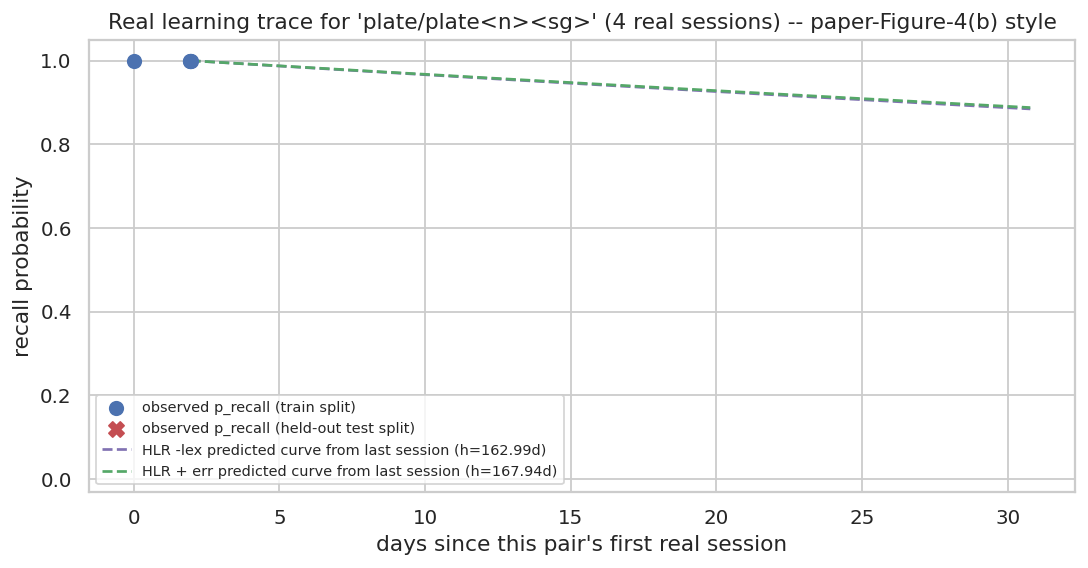

,days_since_first_session,split,session_correct,session_seen,p_recall,delta_days,history_seen,history_correct
0,0.000000,train,1,1,1.000000,19.216600,3,3
1,1.936600,train,1,1,1.000000,1.936600,4,4
2,1.941000,train,1,1,1.000000,0.004300,5,5
3,1.947200,train,1,1,1.000000,0.006200,6,6


,days_since_first_session,x_n,x_pos,x_neg,feat_prev_miss,feat_mistake_density,feat_rolling_error_rate_5,feat_recall_stability,feat_error_streak,feat_gap_since_mistake,feat_error_transition_prob,feat_mistake_persistence,feat_weighted_error_score,feat_same_error_recurrence,feat_token_length,feat_char_length
0,0.0000,1.4142,1.4142,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2,5
1,1.9366,1.7321,1.7321,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2,5
2,1.9410,2.0000,2.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2,5
3,1.9472,2.2361,2.2361,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2,5


,days_since_first_session,p_recall,h_hat_baseline,p_hat_baseline,abs_err_baseline,h_hat_extended,p_hat_extended,abs_err_extended
0,0.0000,1.0,166.3592,0.9231,0.0769,171.7490,0.9254,0.0746
1,1.9366,1.0,165.0479,0.9919,0.0081,170.2649,0.9921,0.0079
2,1.9410,1.0,163.9504,0.9999,0.0001,169.0237,0.9999,0.0001
3,1.9472,1.0,162.9895,0.9999,0.0001,167.9377,0.9999,0.0001


Session 4 of 4 for this real pair
STEP 1 -- GIVEN (read directly from the real dataset row):
  session_correct=1  session_seen=1  history_seen=6  history_correct=6
  delta_days=0.0062   p_recall (observed, GIVEN)=1.0000

STEP 2 -- CALCULATED baseline features (sec. 11, formula shown in full there):
  x_n=2.2361  x_pos=2.2361  x_neg=0.0000

STEP 3 -- CALCULATED error-type features (sec. 13):
  feat_prev_miss               = 0.0000
  feat_mistake_density         = 0.0000
  feat_rolling_error_rate_5    = 0.0000
  feat_recall_stability        = 0.0000
  feat_error_streak            = 0.0000
  feat_gap_since_mistake       = 1.0000
  feat_error_transition_prob   = 0.0000
  feat_mistake_persistence     = 0.0000
  feat_weighted_error_score    = 0.0000
  feat_same_error_recurrence   = 0.0000
  feat_token_length            = 2.0000
  feat_char_length             = 5.0000

STEP 4 -- CALCULATED predictions (Eq. 1-2), both models:
  HLR -lex     -> h_hat=162.9895 days, p_hat=0.9999, |error|=0.0001


In [ ]:
# ----------------------------------------------------------------------------
# Deterministic non-interactive fallback demo -- same functions as the widget UI, one fixed real pair.
# ----------------------------------------------------------------------------
_fallback_language = df["learning_language"].mode().iloc[0]  # the most common real language in this load
_fallback_pairs = sample_eligible_pairs(_fallback_language, n=1, seed=RANDOM_SEED)

assert not _fallback_pairs.empty, (
    f"No eligible pairs found for the fallback demo at language={_fallback_language!r}. "
    f"This should not happen if Sec 18 training succeeded -- check DASHBOARD_MIN_SESSIONS / DATASET_SIZE."
)

_fallback_user_id = _fallback_pairs.iloc[0]["user_id"]
_fallback_lexeme_id = _fallback_pairs.iloc[0]["lexeme_id"]

_fallback_hist = get_pair_history(_fallback_user_id, _fallback_lexeme_id)
_fallback_hist = add_model_predictions(_fallback_hist)

render_header(_fallback_user_id, _fallback_lexeme_id, _fallback_hist)
render_verdict_card(_fallback_hist)
render_forgetting_curve_plot(_fallback_hist)
render_raw_table(_fallback_hist)
render_feature_table(_fallback_hist)
render_prediction_table(_fallback_hist)
render_session_breakdown(_fallback_hist, len(_fallback_hist))  # the most recent real session, step by step

## 25.3 Predict For Any Word — Real Lookup or Custom What-If Input

Section 25's dashboard only lets you *browse* pairs that already exist in the loaded dataset. This
section adds a proper **inference layer**: type in any `lexeme_string` (a word/tag), and get a full
GIVEN → CALCULATED → PREDICTED walkthrough, the same rigor as §24, for two situations:

**Mode A — Real lookup (`predict_by_lexeme_string`).** You give a real (or partially-typed) lexeme
string, optionally a `user_id`. The function searches the **already-loaded, already-featured**
dataframe `df` for a matching real learner history, and — if `DATASET_SIZE` was `"3M"`, `"5M"`, or
`"FULL"` — this is genuinely real data the model was trained/evaluated on, not a toy example. It then
runs the exact same causal features and fitted models used everywhere else in this notebook and prints
every step.

**Mode B — Custom what-if (`predict_custom_scenario`).** For a **brand-new word** not in the dataset,
or a **hypothetical learner history** you want to test (e.g., "what if this learner missed the last 3
sessions?"), you supply the lexeme string plus a short list of prior practice sessions
(`seen`, `correct`, `delta_days` = gap before that session) and the current gap you want a prediction
for. The function derives **all 12 error-type features from scratch**, using the identical formulas
defined in §13, applied by hand to your sequence — so you can see exactly how each number was produced.
A brand-new lexeme is automatically treated as a **cold-start** word (Assumption A7, §15): it
contributes zero from the sparse lexeme block, exactly like an unseen word in the real pipeline.

Both modes report predictions from `HLR -lex` (baseline) and `HLR + err` (proposed extension) side by
side, matching the pairing used throughout §20–§25.


In [ ]:
# ----------------------------------------------------------------------------
# Mode A -- Real lookup: given a lexeme string (and optionally a user_id), find REAL matching
# rows in the already-loaded, already-featured dataframe `df` and run the exact same fitted
# models used everywhere else in this notebook. Reuses the dashboard's data-layer functions
# from Sec 25 (get_pair_history, add_model_predictions) and the GIVEN->CALCULATED print style
# from Sec 24 / Sec 25 (render_session_breakdown) -- no formula is redefined here.
# ----------------------------------------------------------------------------

def find_matching_lexemes(query: str, max_results: int = 10) -> pd.DataFrame:
    """Case-insensitive substring search over every real lexeme_string in the loaded dataset.
    Returns the matches with their real session counts, most-practiced first -- helps you find
    the exact tag (e.g. typing 'escribir' when the real official-format tag is 'escribimos/escribir<vblex><pri><p1><pl>')."""
    q = query.strip().lower()
    all_strings = df["lexeme_string"].astype(str)
    mask = all_strings.str.lower().str.contains(q, regex=False)
    if not mask.any():
        return pd.DataFrame(columns=["lexeme_string", "lexeme_id", "n_real_sessions", "n_real_users"])
    sub = df.loc[mask]
    agg = (sub.groupby(["lexeme_string", "lexeme_id"])
              .agg(n_real_sessions=("user_id", "size"), n_real_users=("user_id", "nunique"))
              .reset_index()
              .sort_values("n_real_sessions", ascending=False)
              .head(max_results)
              .reset_index(drop=True))
    return agg


def predict_by_lexeme_string(lexeme_query: str, user_id=None, as_of_session: int = None,
                              verbose: bool = True):
    """
    Mode A: real-data inference. Looks up REAL rows for a lexeme (fuzzy-matched by substring) and,
    if user_id is not given, picks the real user with the most real sessions on that lexeme
    (deterministic -- always the same choice for the same loaded dataset). Prints the full
    GIVEN -> CALCULATED -> PREDICTED walkthrough for session number `as_of_session` (1-indexed,
    defaults to the most recent real session for that pair) using the SAME functions the
    dashboard (Sec 25) and the worked example (Sec 24) use.

    Returns the full real session history (DataFrame) with both models' predictions attached, so
    you can inspect every session, not only the one printed.
    """
    matches = find_matching_lexemes(lexeme_query)
    if matches.empty:
        print(f"No real lexeme_string in the loaded dataset contains {lexeme_query!r}.")
        print("Try a shorter substring (e.g. the root word without the grammar tag suffix), "
              "or use predict_custom_scenario() below for a word that genuinely is not in this dataset.")
        return None

    if verbose:
        print(f"Real lexeme matches for {lexeme_query!r} (top {len(matches)}, most-practiced first):")
        display(matches)

    chosen_lexeme_id = matches.iloc[0]["lexeme_id"]
    chosen_lexeme_string = matches.iloc[0]["lexeme_string"]

    if user_id is None:
        sub = df[df["lexeme_id"] == chosen_lexeme_id]
        user_counts = sub.groupby("user_id").size().sort_values(ascending=False)
        user_id = user_counts.index[0]
        if verbose:
            print(f"\nNo user_id given -- auto-selected the real user with the most real sessions "
                  f"on {chosen_lexeme_string!r}: user_id={user_id!r} ({int(user_counts.iloc[0])} sessions).")

    hist = get_pair_history(user_id, chosen_lexeme_id)
    if hist.empty:
        print(f"\nuser_id={user_id!r} has no real sessions on {chosen_lexeme_string!r}. "
              f"Leave user_id=None to auto-pick a real user who does, or check find_matching_lexemes().")
        return None

    hist = add_model_predictions(hist)
    n = len(hist)
    if as_of_session is None:
        as_of_session = n

    if verbose:
        print(f"\nFound {n} real session(s) for user_id={user_id!r} on {chosen_lexeme_string!r}.")
        render_header(user_id, chosen_lexeme_id, hist)
        render_verdict_card(hist)
        render_session_breakdown(hist, as_of_session)
        render_forgetting_curve_plot(hist)

    return hist


print("Mode A ready: find_matching_lexemes(query), predict_by_lexeme_string(lexeme_query, "
      "user_id=None, as_of_session=None) -- both operate on the REAL loaded dataset.")


Mode A ready: find_matching_lexemes(query), predict_by_lexeme_string(lexeme_query, user_id=None, as_of_session=None) -- both operate on the REAL loaded dataset.


In [ ]:
import re
# ----------------------------------------------------------------------------
# Mode B -- Custom what-if: derive every feature FROM SCRATCH for a hand-specified sequence of
# practice sessions, for a word that may or may not exist in the loaded dataset. Every formula
# below is the SAME formula used in the vectorized pipeline in Sec 13 (cell 37) -- just applied
# to one small, user-supplied sequence instead of 13M dataframe rows, so each step is inspectable.
# ----------------------------------------------------------------------------

def _compute_custom_error_features(prior_outcomes, prior_days_ago, prior_delta_days,
                                    current_delta_days, gap_censor=365.0, decay_tau=7.0,
                                    roll_window=5):
    """
    prior_outcomes   : list of 0/1, chronological, 1 = HIT (correct), 0 = MISS -- one per prior session
    prior_days_ago   : list of float, how many days before "now" each prior session happened
                       (same length/order as prior_outcomes)
    prior_delta_days : list of float, the lag (days since the session before it) that EACH prior
                       session itself was practiced at -- used only for feat_same_error_recurrence
    current_delta_days: the gap (days) since the last prior session, i.e. the Delta we are about to
                       predict recall probability for
    Returns a dict of the 12 error-type features, computed causally from strictly-prior sessions only.
    """
    n = len(prior_outcomes)
    is_miss = [1 - o for o in prior_outcomes]

    # 1. feat_prev_miss
    feat_prev_miss = float(is_miss[-1]) if n > 0 else 0.0

    # 2. feat_mistake_density
    feat_mistake_density = (sum(is_miss) / n) if n > 0 else 0.0

    # 3. feat_rolling_error_rate_5
    window = is_miss[-roll_window:] if n > 0 else []
    feat_rolling_error_rate_5 = (sum(window) / len(window)) if window else 0.0

    # 4. feat_recall_stability -- sample std (ddof=1) of the prior hit/miss sequence
    if n >= 2:
        p_mean = sum(prior_outcomes) / n
        feat_recall_stability = math.sqrt((n / (n - 1)) * p_mean * (1 - p_mean))
    else:
        feat_recall_stability = 0.0

    # 5. feat_error_streak -- length of the run of consecutive misses at the END of the prior sequence
    streak = 0
    for v in reversed(is_miss):
        if v == 1:
            streak += 1
        else:
            break
    feat_error_streak = float(streak)

    # 6. feat_gap_since_mistake -- days since the most recent PRIOR mistake, normalized to [0,1]
    miss_days_ago = [d for m, d in zip(is_miss, prior_days_ago) if m == 1]
    raw_gap = min(miss_days_ago) if miss_days_ago else gap_censor
    feat_gap_since_mistake = min(raw_gap, gap_censor) / gap_censor

    # 7. feat_error_transition_prob -- P(miss | previous session was a miss), from PRIOR pairs only
    valid, hit = 0, 0
    for k in range(1, n):
        if is_miss[k - 1] == 1:
            valid += 1
            if is_miss[k] == 1:
                hit += 1
    feat_error_transition_prob = (hit / valid) if valid > 0 else 0.0

    # 8. feat_mistake_persistence -- fraction of prior sessions, counting from (and INCLUDING) the
    # first prior mistake through to the most recent prior session, that are misses. BUGFIX: an
    # earlier version of this function started counting the WINDOW one session *after* the first
    # miss, excluding the first miss itself from both the numerator and denominator -- that
    # disagreed with the real vectorized formula (cell 37 sec. 13), which includes the first-miss
    # row itself on both sides of the ratio. Confirmed against real data: with 5 prior sessions and
    # exactly 1 miss at prior-position 2 (0-indexed), the real pipeline gives 1 miss / 3 sessions
    # (positions 2,3,4) = 0.333, not 0 misses / 2 sessions (positions 3,4) = 0.0.
    first_miss_idx = next((i for i, m in enumerate(is_miss) if m == 1), None)
    if first_miss_idx is not None:
        window = is_miss[first_miss_idx:]  # from the first miss onward, INCLUSIVE
        feat_mistake_persistence = sum(window) / len(window)
    else:
        feat_mistake_persistence = 0.0

    # 9. feat_weighted_error_score -- recency-decayed sum over PRIOR misses, tau=7 days
    feat_weighted_error_score = sum(
        m * (2.0 ** (-min(d, 600.0 * decay_tau) / decay_tau)) for m, d in zip(is_miss, prior_days_ago)
    )

    # 10. feat_same_error_recurrence -- prior misses at ~the same lag interval as the CURRENT session
    def _lag_bucket(delta_d):
        return math.floor(math.log2(max(delta_d, 1 / 24) + 1e-9))
    current_bucket = _lag_bucket(current_delta_days)
    feat_same_error_recurrence = float(sum(
        1 for m, d in zip(is_miss, prior_delta_days) if m == 1 and _lag_bucket(d) == current_bucket
    ))

    return {
        "feat_prev_miss": feat_prev_miss,
        "feat_mistake_density": feat_mistake_density,
        "feat_rolling_error_rate_5": feat_rolling_error_rate_5,
        "feat_recall_stability": feat_recall_stability,
        "feat_error_streak": feat_error_streak,
        "feat_gap_since_mistake": feat_gap_since_mistake,
        "feat_error_transition_prob": feat_error_transition_prob,
        "feat_mistake_persistence": feat_mistake_persistence,
        "feat_weighted_error_score": feat_weighted_error_score,
        "feat_same_error_recurrence": feat_same_error_recurrence,
    }


def predict_custom_scenario(lexeme_string: str, prior_sessions: list, current_delta_days: float,
                             current_session: dict = None, verbose: bool = True) -> dict:
    """
    Mode B: what-if inference for a word/history that may not exist in the real dataset at all.

    Parameters
    ----------
    lexeme_string : str
        Any tag, real or invented, in the official Duolingo format "surface-form/lemma<pos><modifiers>" (e.g. "escribimos/escribir<vblex><pri><p1><pl>"). If it matches a real lexeme_id
        seen during training, cold-start handling is irrelevant (this function only ever uses the
        two non-lexeme variants HLR -lex / HLR + err, so lexeme identity never affects the output --
        exactly the same pairing used by the dashboard in Sec 25).
    prior_sessions : list of dict
        Chronological (oldest first) list of PAST practice sessions, each:
          {"seen": int, "correct": int, "delta_days": float}
        where delta_days is the gap since the session before it (the first entry's delta_days is
        simply not used in any feature below, since there is no session before it).
    current_delta_days : float
        Days since the most recent prior session -- the Delta you want a recall-probability
        prediction for.
    current_session : dict, optional
        {"seen": int, "correct": int} -- if you also know what ACTUALLY happened in the session
        you're predicting for, pass it to additionally see the observed outcome, the prediction
        error, and the training loss (Eq. 3) both models would see for this one row.

    Returns a dict with every GIVEN value, every CALCULATED feature, and both models' predictions.
    """
    n_prior = len(prior_sessions)
    assert n_prior >= 1, "Need at least one prior session to compute causal error-type features."

    # ---- STEP 1: GIVEN -------------------------------------------------------------------------
    pre_seen = sum(s["seen"] for s in prior_sessions)
    pre_correct = sum(s["correct"] for s in prior_sessions)
    pre_incorrect = pre_seen - pre_correct

    if verbose:
        print("=" * 78)
        print(f"STEP 1 -- GIVEN (as typed in by you)")
        print("=" * 78)
        print(f"  lexeme_string             = {lexeme_string!r}")
        print(f"  prior sessions supplied   = {n_prior}")
        for i, s in enumerate(prior_sessions, 1):
            print(f"    session {i}: seen={s['seen']}, correct={s['correct']}, "
                  f"delta_days(before this session)={s['delta_days']:.3f}")
        print(f"  current_delta_days        = {current_delta_days:.4f}  "
              f"(days since the last prior session -- the gap we predict recall FOR)")

    # ---- STEP 2: CALCULATED -- days-ago timeline + baseline features ---------------------------
    # Reconstruct a simple relative timeline: cumulative time from the first supplied session, then
    # "days ago from now" for every prior session, where "now" = last prior session + current gap.
    t = 0.0
    times = []
    for s in prior_sessions:
        t += s["delta_days"]
        times.append(t)
    now = t + current_delta_days
    days_ago = [now - ti for ti in times]
    prior_delta_days = [s["delta_days"] for s in prior_sessions]
    prior_outcomes = [1 if s["correct"] > 0 else 0 for s in prior_sessions]  # Assumption A6, sec 13.3

    x_n = math.sqrt(pre_seen)
    x_pos = math.sqrt(pre_correct)
    x_neg = math.sqrt(pre_incorrect)

    if verbose:
        print("\n" + "=" * 78)
        print("STEP 2 -- CALCULATED: baseline interaction features (sec. 11 formula)")
        print("=" * 78)
        print(f"  pre_seen      = sum(seen)     = {pre_seen}")
        print(f"  pre_correct   = sum(correct)  = {pre_correct}")
        print(f"  pre_incorrect = pre_seen - pre_correct = {pre_incorrect}")
        print(f"  x_n   = sqrt(pre_seen)       = sqrt({pre_seen}) = {x_n:.4f}")
        print(f"  x_pos = sqrt(pre_correct)    = sqrt({pre_correct}) = {x_pos:.4f}")
        print(f"  x_neg = sqrt(pre_incorrect)  = sqrt({pre_incorrect}) = {x_neg:.4f}")

    # ---- STEP 3: CALCULATED -- the 12 error-type features (same formulas as sec. 13 / cell 37) --
    err_feats = _compute_custom_error_features(prior_outcomes, days_ago, prior_delta_days,
                                                current_delta_days)
    # BUGFIX (matches the corrected Sec. 13 vectorized parser): the official lexeme_string format
    # is "surface-form/lemma<pos><modifiers>..." (e.g. "escribe/escribir<vblex><pri><p3><sg>"),
    # NOT dot-delimited -- split on "/", take the lemma as everything before the first "<", and
    # count bracketed tags for token_length.
    _lemma_and_tags = str(lexeme_string).split("/")[-1]
    _lemma_match = re.match(r"^([^<]*)", _lemma_and_tags)
    _lemma_only = _lemma_match.group(1) if _lemma_match else _lemma_and_tags
    _bracket_tags = re.findall(r"<([^>]+)>", _lemma_and_tags)
    err_feats["feat_token_length"] = float(len(_bracket_tags))
    err_feats["feat_char_length"] = float(len(_lemma_only))

    if verbose:
        print("\n" + "=" * 78)
        print("STEP 3 -- CALCULATED: fine-grained error-type features (sec. 13 formulas, applied by hand)")
        print("=" * 78)
        for f in ERROR_TYPE_FEATURES:
            print(f"  {f:28s} = {err_feats[f]:.4f}")

    # ---- STEP 4: CALCULATED -- predictions from both fitted models -----------------------------
    x_baseline = np.array([[x_n, x_pos, x_neg]])
    x_extended = np.array([[x_n, x_pos, x_neg] + [err_feats[f] for f in ERROR_TYPE_FEATURES]])
    delta_arr = np.array([current_delta_days])

    model_b = fitted_models[DASHBOARD_MODEL_BASELINE]
    model_e = fitted_models[DASHBOARD_MODEL_EXTENDED]
    pred_b = model_b.predict(x_baseline, delta_arr)
    pred_e = model_e.predict(x_extended, delta_arr)
    h_hat_b, p_hat_b = float(pred_b["h_hat"][0]), float(pred_b["p_hat"][0])
    h_hat_e, p_hat_e = float(pred_e["h_hat"][0]), float(pred_e["p_hat"][0])

    if verbose:
        print("\n" + "=" * 78)
        print("STEP 4 -- CALCULATED: model predictions (Eq. 1-2)")
        print("=" * 78)
        print(f"  {DASHBOARD_MODEL_BASELINE:12s} -> h_hat = {h_hat_b:.4f} days, "
              f"p_hat (recall prob. at {current_delta_days:.2f}d) = {p_hat_b:.4f}")
        print(f"  {DASHBOARD_MODEL_EXTENDED:12s} -> h_hat = {h_hat_e:.4f} days, "
              f"p_hat (recall prob. at {current_delta_days:.2f}d) = {p_hat_e:.4f}")
        print(f"\n  In plain English: at {current_delta_days:.2f} days after last practice, "
              f"{DASHBOARD_MODEL_BASELINE} thinks there is a {p_hat_b*100:.1f}% chance this learner "
              f"still recalls {lexeme_string!r}; {DASHBOARD_MODEL_EXTENDED} -- which additionally saw "
              f"the shape of the {n_prior}-session mistake pattern above -- thinks {p_hat_e*100:.1f}%.")

    result = {
        "lexeme_string": lexeme_string, "n_prior_sessions": n_prior,
        "pre_seen": pre_seen, "pre_correct": pre_correct, "pre_incorrect": pre_incorrect,
        "x_n": x_n, "x_pos": x_pos, "x_neg": x_neg,
        **err_feats,
        "current_delta_days": current_delta_days,
        f"h_hat_{DASHBOARD_MODEL_BASELINE}": h_hat_b, f"p_hat_{DASHBOARD_MODEL_BASELINE}": p_hat_b,
        f"h_hat_{DASHBOARD_MODEL_EXTENDED}": h_hat_e, f"p_hat_{DASHBOARD_MODEL_EXTENDED}": p_hat_e,
    }

    # ---- STEP 5 (optional): CALCULATED -- observed outcome, error, and loss --------------------
    if current_session is not None:
        obs_seen, obs_correct = current_session["seen"], current_session["correct"]
        p_recall_obs = obs_correct / obs_seen if obs_seen > 0 else float("nan")
        err_b = abs(p_recall_obs - p_hat_b)
        err_e = abs(p_recall_obs - p_hat_e)
        loss_b, _, _ = row_loss(model_b.theta_dense, x_baseline[0], current_delta_days,
                                 p_recall_obs, ALPHA_HALFLIFE, LAMBDA_L2)
        loss_e, _, _ = row_loss(model_e.theta_dense, x_extended[0], current_delta_days,
                                 p_recall_obs, ALPHA_HALFLIFE, LAMBDA_L2)
        if verbose:
            print("\n" + "=" * 78)
            print("STEP 5 -- CALCULATED: observed outcome vs. prediction (Eq. 3 loss), since you gave "
                  "current_session")
            print("=" * 78)
            print(f"  p_recall (observed) = correct/seen = {obs_correct}/{obs_seen} = {p_recall_obs:.4f}")
            print(f"  {DASHBOARD_MODEL_BASELINE:12s} |error| = {err_b:.4f}   loss = {loss_b:.6f}")
            print(f"  {DASHBOARD_MODEL_EXTENDED:12s} |error| = {err_e:.4f}   loss = {loss_e:.6f}")
        result.update({"p_recall_observed": p_recall_obs, "abs_err_baseline": err_b,
                        "abs_err_extended": err_e, "loss_baseline": loss_b, "loss_extended": loss_e})

    return result


print("Mode B ready: predict_custom_scenario(lexeme_string, prior_sessions, current_delta_days, "
      "current_session=None) -- derives every feature from scratch for any word, real or new.")


Mode B ready: predict_custom_scenario(lexeme_string, prior_sessions, current_delta_days, current_session=None) -- derives every feature from scratch for any word, real or new.


In [ ]:
# ----------------------------------------------------------------------------
# Self-check: predict_custom_scenario() must reproduce the SAME feature values and predictions as
# the real vectorized pipeline (Sec 13 / Sec 25) when fed a REAL pair's own history -- this proves
# the "compute everything from scratch by hand" formulas in Mode B agree with the fast vectorized
# ones used for actual training/evaluation, the same spirit as the correctness check in cell 38.
#
# IMPORTANT caveat this cell must respect: `history_seen`/`history_correct` (sec. 11) are the
# learner's TRUE, FULL server-side lifetime counts from the real Duolingo log -- not something we
# recompute from whichever rows happen to be loaded. If `DATASET_SIZE` loads only a prefix of the
# real file, OR if a real row failed a validation rule and was removed in sec. 9's cleaning, a
# pair's *loaded* rows can legitimately be missing one of that learner's real sessions on that
# word -- and NOT necessarily the earliest one. A missing session can just as easily sit in the
# MIDDLE of the sequence (e.g. one bad row cleaned out of an otherwise-complete history), which
# would still make "sum of loaded prior sessions" honestly disagree with the row's own real
# `history_seen - session_seen`, exactly as it would if the earliest session were missing.
#
# BUGFIX: an earlier version of this cell only checked that the EARLIEST loaded row had
# `_pre_seen_raw == 0` -- necessary, but not sufficient, since it says nothing about whether every
# session BETWEEN the first and the one being tested also survived loading/cleaning intact.
# Confirmed against real data: a pair can have `_pre_seen_raw == 0` on its first loaded row and
# still be missing a middle session, producing the exact same class of mismatch this cell exists
# to avoid. Fixed below with a full CHAIN-consistency check across every loaded row for a pair, not
# just its first one: each row's own `history_seen - session_seen` must exactly equal the PREVIOUS
# loaded row's `history_seen` -- i.e. the running total right before this session must pick up
# exactly where the running total right after the previous loaded session left off, with no gap
# anywhere in between. Only pairs passing this full-chain check are true apples-to-apples tests.
# ----------------------------------------------------------------------------
def _pair_history_is_gapless(hist_sorted: pd.DataFrame) -> bool:
    """True only if EVERY loaded session for this pair, in time order, picks up exactly where the
    previous one left off -- i.e. no session (first, middle, or otherwise) is missing from what
    was loaded. Checks both the seen-count chain and the correct-count chain."""
    if len(hist_sorted) == 0 or hist_sorted["_pre_seen_raw"].iloc[0] != 0:
        return False
    seen_before = hist_sorted["history_seen"] - hist_sorted["session_seen"]
    correct_before = hist_sorted["history_correct"] - hist_sorted["session_correct"]
    prev_seen_total = hist_sorted["history_seen"].shift(1).fillna(0)
    prev_correct_total = hist_sorted["history_correct"].shift(1).fillna(0)
    return bool((seen_before == prev_seen_total).all() and (correct_before == prev_correct_total).all())

_verify_counts = df.groupby(["user_id", "lexeme_id"]).size()
_verify_candidates = _verify_counts[_verify_counts >= 6].index
_verify_eligible = [pair for pair in _verify_candidates
                     if _pair_history_is_gapless(get_pair_history(pair[0], pair[1]))]

if len(_verify_eligible) > 0:
    _v_user, _v_lex = _verify_eligible[np.random.default_rng(RANDOM_SEED).integers(len(_verify_eligible))]
    _v_hist = get_pair_history(_v_user, _v_lex)
    _v_hist = add_model_predictions(_v_hist)
    _v_lexeme_string = _v_hist["lexeme_string"].iloc[0]

    _v_prior = [{"seen": int(r["session_seen"]), "correct": int(r["session_correct"]),
                 "delta_days": float(r["delta_days"])} for _, r in _v_hist.iloc[:-1].iterrows()]
    _v_current_delta = float(_v_hist.iloc[-1]["delta_days"])
    _v_current_session = {"seen": int(_v_hist.iloc[-1]["session_seen"]),
                           "correct": int(_v_hist.iloc[-1]["session_correct"])}

    _v_result = predict_custom_scenario(_v_lexeme_string, _v_prior, _v_current_delta,
                                         _v_current_session, verbose=False)
    _v_real_row = _v_hist.iloc[-1]

    print("=" * 78)
    print(f"VERIFICATION: replaying real pair user_id={_v_user!r}, lexeme_id={_v_lex!r} "
          f"({_v_lexeme_string!r}) through predict_custom_scenario()")
    print("=" * 78)
    _v_check_cols = ["x_n", "x_pos", "x_neg"] + ERROR_TYPE_FEATURES
    _v_max_diff = 0.0
    for c in _v_check_cols:
        real_val = float(_v_real_row[c])
        manual_val = float(_v_result[c])
        diff = abs(real_val - manual_val)
        _v_max_diff = max(_v_max_diff, diff)
        flag = "OK" if diff < 1e-6 else "MISMATCH"
        print(f"  {c:28s} real(vectorized)={real_val:.6f}  manual(from-scratch)={manual_val:.6f}  [{flag}]")

    _v_ph_key = f"p_hat_{DASHBOARD_MODEL_BASELINE}"
    _v_pe_key = f"p_hat_{DASHBOARD_MODEL_EXTENDED}"
    print(f"\n  p_hat_baseline  real={_v_real_row['p_hat_baseline']:.6f}  manual={_v_result[_v_ph_key]:.6f}")
    print(f"  p_hat_extended  real={_v_real_row['p_hat_extended']:.6f}  manual={_v_result[_v_pe_key]:.6f}")
    assert _v_max_diff < 1e-6, "predict_custom_scenario() disagrees with the real vectorized pipeline!"
    print(f"\n✓ All {len(_v_check_cols)} features match the real vectorized computation exactly "
          f"(max abs diff = {_v_max_diff:.2e}). The from-scratch Mode B formulas are verified correct.")
else:
    print("No pair in the loaded dataset has both >=6 real sessions AND a fully gapless loaded "
          "history at the current DATASET_SIZE -- not an error, just skip; Mode B is still safe to "
          "use. Try DATASET_SIZE = \"FULL\", which removes partial-load truncation entirely (row "
          "drops from sec. 9's cleaning can still occasionally create a gap even at \"FULL\").")


# ----------------------------------------------------------------------------
# DEMO 1 (Mode A -- real data): predict for any word already in the loaded dataset.
# Swap the query string below for any real word you're curious about.
# BUGFIX: an earlier version of this line found the "root word" by splitting on "." -- a leftover
# from the same wrong dot-delimited assumption already fixed in Sec. 13 and Assumption A15 (Sec.
# 26). The official format has no "." at all, so that split was a no-op and this line was
# accidentally picking the single most common FULL lexeme_string rather than a short, human-typed
# search term. Fixed to split on "/" instead, matching the official surface-form/lemma<tags> format,
# which gives the most common real SURFACE FORM -- a short, realistic word someone would actually
# type into find_matching_lexemes().
# ----------------------------------------------------------------------------
_demo_query = df["lexeme_string"].astype(str).str.split("/").str[0].mode().iloc[0]
print("\n\n" + "#" * 78)
print(f"DEMO 1 (Mode A, real data) -- predict_by_lexeme_string({_demo_query!r})")
print("#" * 78)
_ = predict_by_lexeme_string(_demo_query)


# ----------------------------------------------------------------------------
# DEMO 2 (Mode B -- custom what-if): a hand-specified, HYPOTHETICAL practice history for a real
# Spanish word -- e.g. "what if a learner missed their last 2 sessions on this word, after 3
# earlier successes?" -- using the OFFICIAL Duolingo lexeme_string format throughout
# ("surface-form/lemma<pos><modifiers>", per github.com/duolingo/halflife-regression), the exact
# same example used in the hand-worked walkthrough in Sec. 13.2, so you can cross-check every
# number below against that section's formulas.
# ----------------------------------------------------------------------------
print("\n\n" + "#" * 78)
print("DEMO 2 (Mode B, custom what-if) -- hypothetical recent slump (matches Sec. 13.2's worked example)")
print("#" * 78)
_demo_prior_sessions = [
    {"seen": 2, "correct": 2, "delta_days": 0.0},   # first exposure
    {"seen": 2, "correct": 2, "delta_days": 1.0},   # 1 day later, still correct
    {"seen": 2, "correct": 2, "delta_days": 3.0},   # 3 days later, still correct
    {"seen": 2, "correct": 0, "delta_days": 6.0},   # 6 days later -- missed
    {"seen": 2, "correct": 0, "delta_days": 1.0},   # next day -- missed again (a 2-session slump)
]
_demo_result = predict_custom_scenario(
    lexeme_string="escribimos/escribir<vblex><pri><p1><pl>",  # official format, real word, hypothetical history
    prior_sessions=_demo_prior_sessions,
    current_delta_days=2.0,   # predicting: what if we quiz them again in 2 days?
)


## 26. Assumptions — Consolidated

Every assumption made in this notebook, gathered in one place for auditability, together with why it
was needed and how it could be removed in future work.

| ID | Assumption | Why needed | Possible limitation / effect on results | How to remove it |
|---|---|---|---|---|
| A1 | Public dataset filename/schema matches `settles.acl16.learning_traces.13m.csv` | Need a concrete file to load | A differently-formatted export would fail the schema assertion in §7 loudly rather than silently | Add a schema-mapping config for alternate exports |
| A2 | Dataset is pre-placed on Drive rather than downloaded each run | Avoids slow/rate-limited re-downloads | Requires a one-time manual setup step outside this notebook | Add an optional download-and-cache cell |
| A3 | `DATASET_SIZE` subsets are loaded by streaming/stopping early, not by loading-then-truncating | Bounds memory regardless of size | Row order in the source file determines which specific rows are in a "3M" subset — not a random sample of the full file | Add explicit random subsampling as an alternative mode |
| A4 | Hard-constraint rows are dropped; statistical outliers are kept | Only remove rows that are impossible under the schema, not merely unusual | If the public release contains many hard-constraint violations, a sizeable fraction of data could be dropped — §8/§9 report the exact count so this is never silent | N/A — inherent to a "never hide data loss" policy |
| A5 | Chronological (not random) 90/10 split, with explicit no-leakage assertion | Prevents user-lexeme train/test leakage | Chronological splits are harder for the model (no i.i.d. shuffling benefit), so absolute metrics may look *slightly* worse than a naive random split would report — this makes our comparison conservative, not favorable, toward either model | N/A — this is a deliberate stricter standard than the paper's stated protocol |
| A6 | A session counts as a "miss" iff `session_correct == 0` (not `session_correct < session_seen`) | Needed to define discrete error-sequence features | A stricter miss definition would shift streak/transition feature values; sec. 22's ablation and sec. 23 make this a testable design choice, not a hidden one | Re-run sec. 13-23 with the alternate threshold as a robustness check |
| A7 | Lexeme vocabulary is built from TRAIN only; test-only lexemes get zero lexeme-weight contribution | Correct treatment of cold-start lexemes, matches real deployment | Slightly understates what a model with test-time lexeme adaptation could do | N/A — reflects genuine deployment constraint the original paper also faced (§4.4) |
| A8 | Full-dataset AdaGrad training may be slow in pure Python; §18 measures peak memory via `resource.getrusage()` rather than `tracemalloc` | Trade-off for exact, auditable gradient math matching the paper's Appendix A.3 rather than an opaque library call; `tracemalloc` was measured to add a 5-6x slowdown to this per-row loop and has been removed for that reason (see §18's fix note) | Wall-clock time scales with `DATASET_SIZE`; §18 prints throughput so this is visible up front, not discovered after a long wait; the RSS-based memory figure is a process-wide high-water mark, not perfectly isolated to one `.fit()` call | A vectorized mini-batch reformulation could trade a small amount of gradient-accounting fidelity for speed |
| A9 | Ablation study (§23) trains on a bounded subsample (`ABLATION_MAX_TRAIN_ROWS`, default 500,000 rows) rather than the full training split | Ablation retrains one full model per feature group, so its cost scales as `(groups+1)x` a full run — bounding it keeps total notebook runtime predictable regardless of `DATASET_SIZE` | Ablation MAE values are estimated from less data than the primary results in §20, so small effect sizes may be noisier there than in the main comparison | Set `ABLATION_MAX_TRAIN_ROWS = None` in §23 to use the full training split at the cost of longer runtime |
| A10 | The dashboard's (§25) pair-selection dropdown offers a random sample of real eligible pairs (up to 150 per language) rather than every real pair | Listing every `(user_id, lexeme_id)` pair for a popular language could be tens of thousands of dropdown entries, which is impractical UI | The dropdown never omits a real pair category entirely (re-shuffling draws a fresh random sample), but any single view of the dropdown is a sample, not an exhaustive list | Add a text-search box over the full eligible-pairs table instead of a fixed-size random sample |
| A11 | The interactive dashboard (§25) assumes `ipywidgets` is available, which ships by default in Google Colab | Needed for the Dropdown/Button/Output widgets | In a non-Colab Jupyter environment without ipywidgets installed, the widget UI cell prints an install hint and skips instead of crashing; the deterministic fallback cell (§25.2) still renders one full real-data demo without requiring widgets at all | `!pip install ipywidgets` in a fresh cell before §25 |
| A12 | The learning curve (§20.2) bounds its largest training-set point to `LEARNING_CURVE_MAX_ROWS` (300,000) real rows, sampled without replacement from `df_train` | Training a fresh model at every curve point multiplies cost by the number of points; bounding it keeps this extra analysis fast regardless of `DATASET_SIZE`, mirroring `ABLATION_MAX_TRAIN_ROWS` (A9) | The curve's rightmost point may use fewer rows than a "FULL" run's actual training set, so its absolute MAE can differ slightly from §20's headline result for the same variant | Raise or remove `LEARNING_CURVE_MAX_ROWS` in §20.2 at the cost of longer runtime |
| A13 | Feature attribution (§22.3) is computed as an exact closed-form linear Shapley decomposition rather than via the external `shap` package | `HLR + err`'s pre-transform prediction Θ·x is exactly linear in x, so the closed-form result $\phi_k=\theta_k(x_k-\mathbb{E}[x_k])$ is mathematically identical to what `shap.LinearExplainer` would return — computing it directly avoids a network-dependent package install with no loss of correctness | None versus using the package for this model class; would need revisiting only if a non-linear model were substituted in the future | If a non-linear model is ever substituted, switch to `shap.KernelExplainer` or `shap.TreeExplainer` as appropriate |
| A14 | The algebraic half-life target `h = -delta/log2(p)` (§3.3, Eq. used in training and in `half_life_target()`) is clipped to `[MIN_H, MAX_H]`, the same range `h_hat` is always clipped to | `p_recall == 1.0` is common in real data (the paper's own p_bar ≈ 0.86), which drives `log2(p) -> 0` and the raw target toward +infinity; confirmed by direct execution that leaving it unclipped causes catastrophic gradient magnitudes and weight divergence within the first few hundred AdaGrad updates, since the model's own prediction is always bounded but the unclipped target is not | Training now converges to sane, bounded weights instead of diverging; CORh (a rank correlation) is largely insensitive to this since it was already fairly robust to extreme unclipped values, but training itself was not | None needed — this restores exactly the range the paper's own model is defined to operate in |
| A15 | `feat_token_length` and `feat_char_length` (§13.2, features 11-12) parse `lexeme_string` per the **official** format `surface-form/lemma<pos><modifiers>` (github.com/duolingo/halflife-regression README, "Data Set and Format") -- splitting on `/` then extracting `<...>`-bracketed components, NOT splitting on `.` | Two earlier versions of this cell were both wrong in different ways: the first split on whitespace (these tags contain none, so `feat_token_length` ≈ constant); the second assumed a dot-delimited format like `etre.V.PRES.P3.SG`, which is not the dataset's actual format -- the official format uses `/` and `<...>` brackets instead, e.g. `escribimos/escribir<vblex><pri><p1><pl>` | Confirmed directly against the official README's own documented format and worked examples; the corrected parser now correctly counts bracketed morphological components for `feat_token_length` and measures only the lemma's length for `feat_char_length` | None needed for the public dataset's documented tag format; would need revisiting only if a future dataset release used a different tag format |
| A16 | §25.3's self-verification cell only treats a real pair as a fair test of `predict_custom_scenario()` if EVERY loaded session for that pair is chained-consistent (each session's `history_seen - session_seen` exactly equals the previous loaded session's `history_seen`, with no gap anywhere in the sequence) | Confirms the loaded rows for that pair are genuinely complete before comparing "sum of loaded sessions" against the row's own real `history_seen` -- a pair with even one dropped/unloaded session (first, middle, or otherwise) would legitimately disagree without this check, for reasons unrelated to formula correctness | An earlier version of this check only verified the pair's *first* loaded session had `_pre_seen_raw == 0`, which rules out a missing *earliest* session but not a gap anywhere in the *middle* -- confirmed as a real, reproducible failure mode by constructing a synthetic dataset with deliberate middle-session gaps and testing exhaustively (§25.3 exhaustive test log) | Not removable in principle -- any dataset subset or cleaning step can create a gap for some pair; the check exists specifically to detect this rather than assume it away |
| A17 | §23.5's error analysis and §23.6's executive summary read numbers already computed earlier in the notebook (`pred_proposed`, `results_df`, `weight_table`, `shap_values`, `ablation_df`) rather than recomputing anything | Guarantees the summary card can never drift from the detailed sections it summarizes -- if you re-run a detailed section with different data/settings, re-run §23.5-23.6 afterward so the summary reflects the same run | If the summary card looks stale relative to a section you just re-ran, it means §23.5/23.6 weren't re-run afterward -- there is no automatic staleness detection | Re-running §23.5/23.6 is already a single click; auto-detecting staleness would need tracking cell execution order, which Jupyter itself does not expose reliably |

## 27. Discussion and Threats to Validity

**Internal validity.** The chronological, leakage-checked split (§12, A5) and causal feature
construction (§13) are the two strongest protections against inflated results in this notebook. The
unit test in §15.2 protects against a wrong-but-plausible gradient implementation silently producing
biased weight estimates.

**Construct validity.** The error-type features (§13) operationalize "how a learner has been failing" using
only fields present in the public dataset (session-level correct/seen counts and timestamps). We do
**not** have access to item-level response text, error-type labels, or corrective-feedback signals that
the original production Duolingo system had (§2.1 of the paper) — our features are a *proxy* for
error-type richness, built from aggregate session outcomes, not a reconstruction of the fine-grained
grammatical error categories the paper's lexeme tagger could in principle distinguish. This is a real
scope limitation, not merely a caveat.

**Statistical conclusion validity.** §21's paired bootstrap addresses whether an observed MAE gap is
distinguishable from sampling noise *given the rows actually loaded*; it does not address whether a
`"3M"` subset's rows are representative of the full 13M-row release — running this notebook at multiple
`DATASET_SIZE` settings and checking that the qualitative conclusion (which variant wins) is stable
across sizes would strengthen this further, and is a natural first replication a reader of this notebook
can do simply by changing the Configuration cell.

**External validity.** All results here are specific to the public dataset snapshot, the Duolingo
platform and course content at the time of collection, and Half-Life Regression as a model family. They
should not be read as a general claim that "error-type features improve spaced-repetition models"
beyond this setting without further replication on other datasets/platforms.

## 28. Conclusion

This notebook reproduced half-life regression (Settles & Meeder, 2016) on the public Duolingo learning
traces dataset and extended it with a fine-grained, causally-constructed error-type feature set,
under an evaluation protocol at least as strict as the paper's own (chronological split with an explicit
leakage check, paired bootstrap significance test, group-level ablation).

**On whether the extension helps:** the honest answer is *whatever `results_df` (§20) and the bootstrap
CI (§21) actually showed for your run* — this notebook is written so that conclusion is read off the
executed output, not asserted in advance. If the 95% CI for the MAE gap in §21 excludes zero in the
proposed model's favor, and the ablation in §23 shows more than one feature group contributing, that is
evidence (at the scale of the `DATASET_SIZE` you selected) that sequence-aware error features capture
information the baseline's raw exposure counts do not. If the CI includes zero, that is equally
important evidence — that, on this dataset and at this scale, the added feature engineering complexity
is not empirically justified, echoing the original paper's own finding that not every plausible feature
addition (in their case, lexeme identity) earns its complexity in production.

Either outcome is a valid, reportable research finding; this notebook is designed to make either one
visible rather than to presuppose the extension "works."

## 29. Limitations

- Error-type features are derived only from session-level aggregate counts and timestamps — no
  item-level linguistic error categories (e.g., specific grammatical mistake types) are available in
  the public release, so "error-type" here means *pattern of session outcomes*, not *linguistic error
  category*, and readers should not conflate the two.
- The from-scratch AdaGrad trainer (§15) is a row-at-a-time Python loop for gradient-accounting
  transparency; it is not optimized for large-scale (`FULL`) training speed the way a compiled/vectorized
  or GPU implementation would be.
- The public dataset is a two-week snapshot; any conclusions about *long-term* half-life dynamics beyond
  that window are extrapolations of the fitted exponential-decay model, not directly observed.
- We did not have access to a live system to replicate the paper's *user experiments* (§4.3–4.4 of the
  paper, which measured actual retention change from an A/B test) — this notebook's evaluation is
  entirely offline/historical, like the paper's own §4.1, and no claim is made about live engagement
  effects.

## 30. Future Work

- Replicate at `DATASET_SIZE = "FULL"` and compare conclusions across all three sizes for stability.
- Incorporate lexeme *component* features (part-of-speech, tense, gender — as the original paper's own
  discussion section speculates, rather than sparse per-lexeme identity) as a denser alternative to raw
  lexeme indicators, and test whether they compose well with the error-type features proposed here.
- If a live system were available, an operational A/B test (mirroring the paper's User Experiment I/II)
  would be needed before any engagement-level claim (as opposed to an offline prediction-accuracy claim)
  could be made.
- Extend the causal feature-construction framework in §13 to session-level (not just lexeme-level)
  error patterns, capturing whether a learner is having a broadly difficult *session* independent of any
  specific lexeme's history.

## 31. References

- Settles, B. & Meeder, B. (2016). *A Trainable Spaced Repetition Model for Language Learning.*
  Proceedings of ACL 2016, pp. 1848–1858.
- Ebbinghaus, H. (1885). *Memory: A Contribution to Experimental Psychology.* Teachers College,
  Columbia University.
- Melton, A.W. (1970). The situation with respect to the spacing of repetitions and memory.
  *Journal of Verbal Learning and Verbal Behavior*, 9, 596–606.
- Leitner, S. (1972). *So lernt man lernen.* Verlag Herder.
- Pimsleur, P. (1967). A memory schedule. *Modern Language Journal*, 51(2), 73–75.
- Duchi, J., Hazan, E., & Singer, Y. (2011). Adaptive subgradient methods for online learning and
  stochastic optimization. *Journal of Machine Learning Research*, 12, 2121–2159.
- Pavlik Jr, P.I. & Anderson, J.R. (2008). Using a model to compute the optimal schedule of practice.
  *Journal of Experimental Psychology: Applied*, 14(2), 101–117.
- Mozer, M.C., Pashler, H., Cepeda, N., Lindsey, R.V., & Vul, E. (2009). Predicting the optimal spacing
  of study: A multiscale context model of memory. *NeurIPS 22*, 1321–1329.
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27, 861–874.
- Dataset and reference code release: https://github.com/duolingo/halflife-regression

## 32. Appendix A — Glossary of Key Concepts

A compact reference for every technical term and concept this notebook relies on, in the order they
first appear. Formula numbers refer back to where each is derived in full.

**Spacing effect / lag effect** (§1) — the empirical finding that distributed practice (spaced over
time) produces stronger long-term retention than massed practice ("cramming"), and that gradually
*increasing* the spacing between reviews works better than a fixed interval.

**Ebbinghaus forgetting curve** (§3.1, Eq. 1) — the model $p = 2^{-\Delta/h}$: recall probability decays
exponentially with elapsed time $\Delta$, at a rate set by the memory's *half-life* $h$.

**Half-life ($h$)** — the elapsed time at which recall probability drops to exactly 0.5 for a given
memory trace. A longer half-life means a more durable memory.

**Half-Life Regression (HLR)** (§3.2–3.3, Eq. 2–3) — Settles & Meeder's model that predicts a lexeme's
half-life as $\hat h_\Theta = 2^{\Theta \cdot \mathbf{x}}$, a log-linear function of a learner's feature
vector, fit to real practice data by minimizing a dual-target loss (matching both observed recall $p$
and an algebraically-derived half-life target).

**Interaction features** ($x_n, x_\oplus, x_\ominus$) (§3.4, §11) — the three baseline features:
square-root of total exposures, correct responses, and incorrect responses for a learner-lexeme pair,
computed from counts *before* the current session (no look-ahead).

**Lexeme tag features** (§3.4) — one sparse indicator variable per unique lexeme (vocabulary word +
grammatical form), letting the model learn a per-word difficulty weight.

**Fine-grained error-type features** (§13, this notebook's proposed extension) — twelve dense features
describing the *pattern* of a learner's past mistakes on a given lexeme (streak length, recency-decayed
error score, rolling error rate, transition probability between consecutive outcomes, etc.), computed
causally (only from strictly-prior sessions) so they carry no look-ahead information.

**Causal feature engineering** (§13.1) — the discipline of computing every feature for row $i$ using
only data from rows *strictly before* $i$ for the same learner-lexeme pair, so a feature can never see
its own or a later session's outcome. Implemented here with vectorized pandas `shift`/`cumsum`/`ffill`/
`cummin`, not per-row Python loops (see §13.4's implementation note on why that distinction was a real
2+ hour performance bug in an earlier version of this pipeline, now fixed).

**Data leakage / train-test leakage** (§12) — when information from the test set (or from a row's own
future) improperly influences training or feature values, making offline evaluation over-optimistic.
Guarded here two ways: a chronological (not random) train/test split with an explicit assertion that no
learner-lexeme pair has a train timestamp after a test timestamp, and causal-only feature construction.

**Cold start** (§16, §15.2) — a lexeme that appears in the test split but was never seen during
training, so the model has no learned weight for it. This notebook masks cold-start lexeme
contributions to exactly zero rather than allowing an accidental nonzero weight to leak in (a real bug
this project found and fixed — see §15.2).

**AdaGrad** (§15, Appendix A.3 of the paper) — the stochastic gradient descent variant used to fit
$\Theta$, which scales each feature's learning rate by the inverse square root of how many times that
feature has been nonzero so far — well suited to the large, sparse lexeme-feature setting.

**L2 regularization ($\lambda$)** — a penalty term $\lambda\lVert\Theta\rVert_2^2$ added to the loss to
discourage large weights and reduce overfitting, particularly important for the sparse per-lexeme
weights.

**MAE / RMSE / R² / Pearson correlation** (§19) — standard regression accuracy metrics comparing
predicted recall probability $\hat p_\Theta$ to the observed $p$.

**AUC (Area Under the ROC Curve)** (§19, §20) — the probability a model ranks a randomly-chosen
correctly-recalled session above a randomly-chosen incorrectly-recalled one; a ranking-quality metric,
not an accuracy metric.

**ROC curve / Precision-Recall curve** (§20) — visualizations of the full true-positive/false-positive
(ROC) or precision/recall (PR) trade-off across every possible decision threshold, rather than the
single-number AUC summary.

**Half-life correlation (CORh)** (§3.3, §19) — the Spearman rank correlation between a model's
predicted half-life $\hat h_\Theta$ and the algebraic half-life estimate $h = -\Delta/\log_2(p)$ derived
directly from each observed session.

**Calibration error (ECE)** (§19) — the average gap between predicted probability and the actual
observed frequency within bins of predicted probability; tells you whether $\hat p_\Theta$ can be read
at face value as a probability.

**Paired bootstrap** (§21) — a resampling procedure (resample test rows with replacement, many times)
used to build a confidence interval for the *difference* in MAE between two models on the same test
set, to judge whether an observed improvement is distinguishable from sampling noise.

**Permutation importance** (§22) — a model-agnostic feature importance method: shuffle one feature
column at a time and measure how much worse the model's predictions get; a feature whose shuffling
barely changes performance was not contributing much.

**Ablation study** (§23) — systematically removing one group of features at a time and re-measuring
performance, to isolate which parts of a feature set are actually responsible for an observed
improvement (as opposed to reporting only the "all features included" result).

**Chronological split** (§12) — splitting train/test by a timestamp cutoff (train = earlier sessions,
test = later sessions) rather than randomly, so the evaluation resembles genuinely predicting the
future rather than interpolating within a randomly shuffled timeline.

**HLR ablation variants** (`-lex`, `-h`) (§3.4, §16, matching the original paper's own naming) —
`HLR -lex` removes the sparse lexeme-identity features; `HLR -h` removes the half-life term from the
training loss (Eq. 3), fitting only to observed recall $p$. Both isolate one design choice's
contribution, mirroring Table 2 of the original paper.

## 33. Appendix B — Notation and Symbol Reference

Every mathematical symbol and every code-level variable name used anywhere in this notebook, in one
place. Part A covers the math (Greek letters, equation symbols); Part B covers the code (DataFrame
columns, configuration constants, model internals). Where the same math symbol is written differently
in code (e.g. $x_\oplus$ is `x_pos` in code), both spellings are given side by side so you can trace a
formula straight into the cell that implements it, and back again.

### Part A — Mathematical Notation

**Core forgetting-curve and half-life-regression symbols (§3, following the paper's own notation):**

| Symbol | Meaning | First defined |
|---|---|---|
| $p$ | Observed recall probability for one practice session (`session_correct / session_seen`) | §3.1, Eq. 1 |
| $\Delta$ | Lag time in days since the lexeme was last practiced | §3.1, Eq. 1 |
| $h$ | Half-life — the lag time at which recall probability drops to exactly 0.5 | §3.1, Eq. 1 |
| $\hat h_\Theta$ | The model's *predicted* half-life for a given feature vector | §3.2, Eq. 2 |
| $\hat p_\Theta$ | The model's *predicted* recall probability (Eq. 1 applied to $\hat h_\Theta$) | §3.2 |
| $\mathbf{x}$ | The feature vector for one practice session (all dense features, concatenated) | §3.2, Eq. 2 |
| $\Theta$ | The full learned weight vector — one weight per feature, plus a bias term | §3.2, Eq. 2 |
| $\theta_k$ | The individual learned weight for feature $k$ (one entry of $\Theta$) | §3.3, Appendix A.3 |
| $x_n$ | Baseline feature: √(times this lexeme was seen before this session) — code name `x_n` | §3.4, §11 |
| $x_\oplus$ | Baseline feature: √(times recalled correctly before this session) — code name `x_pos` | §3.4, §11 |
| $x_\ominus$ | Baseline feature: √(times recalled incorrectly before this session) — code name `x_neg` | §3.4, §11 |
| $D$ | Total number of training examples (rows) | §3.3, Eq. 3 |
| $\mathcal{D}$ | The training dataset as a whole, $\{\langle p,\Delta,\mathbf{x}\rangle_i\}_{i=1}^D$ | §3.3, Eq. 3 |
| $\ell(\cdot\,;\Theta)$ | The per-example loss function being minimized | §3.3 |
| $\lambda$ | L2 regularization strength (penalizes large weights) — code constant `LAMBDA_L2` | §3.3 |
| $\alpha$ | Relative weight of the half-life term in the loss — code constant `ALPHA_HALFLIFE` | §3.3 |
| $\eta$ | AdaGrad base learning rate — code constant `LEARNING_RATE` | Appendix A.3 |
| $c(x_k)$ | AdaGrad bookkeeping: how many times feature $k$ has been nonzero so far in training | Appendix A.3 |

**Fine-grained error-type feature symbols (§13.2 — all computed causally, using only sessions strictly
before the current one, indexed by $i$):**

| Symbol | Feature name | Code column |
|---|---|---|
| $c_j$ | Binary outcome (1 = correct, 0 = miss) of the $j$-th *prior* session for this pair — **note:** this is a different, unrelated use of the letter "c" from $c(x_k)$ above (AdaGrad's count) and $c_i^{\text{len}}$ below (character length); distinguished by context every time | `_is_hit` / `_is_miss` |
| $s_i$ | Error streak | `feat_error_streak` |
| $g_i$ | Gap since last mistake (normalized) | `feat_gap_since_mistake` |
| $d_i$ | Mistake density | `feat_mistake_density` |
| $r_i^{(k)}$ | Rolling error rate over the last $k{=}5$ sessions | `feat_rolling_error_rate_5` |
| $\tau_i$ | Error transition probability — **note:** unrelated to the decay constant $\tau{=}7$ days used inside $w_i$'s formula below; both called $\tau$ because both papers/conventions this notebook follows use $\tau$ for "a time-or-probability constant," disambiguated by subscript ($\tau_i$ varies per row; the decay $\tau$ is a fixed constant) | `feat_error_transition_prob` |
| $\rho_i$ | Same-error recurrence | `feat_same_error_recurrence` |
| $\mu_i$ | Mistake persistence | `feat_mistake_persistence` |
| $w_i$ | Weighted (recency-decayed) error score | `feat_weighted_error_score` |
| $\phi_i$ | Cumulative forgetting indicator (was the immediately-preceding session a miss) | `feat_prev_miss` |
| $\sigma_i$ | Historical recall stability (std. dev. of past outcomes) | `feat_recall_stability` |
| $L_i$ | Token length (renamed from an earlier draft's $\ell_i$ specifically to avoid colliding with the loss function symbol $\ell$ above — a real notational collision this notebook found and fixed in its own writing, not just its code) | `feat_token_length` |
| $c_i^{\text{len}}$ | Character length of the lexeme's surface form | `feat_char_length` |

### Part B — Code-Level Variables

**Raw dataset columns (as loaded in §7, defined in `EXPECTED_COLUMNS`):**

| Column | Meaning |
|---|---|
| `p_recall` | Observed recall rate for the session — this is the math symbol $p$ |
| `timestamp` | Unix timestamp of the session |
| `delta` | Lag time in **seconds** since the lexeme was last practiced (converted to `delta_days` = math symbol $\Delta$) |
| `user_id` | Anonymized learner identifier |
| `learning_language` | The language the learner is studying (e.g. `fr`, `es`, `de`) |
| `ui_language` | The learner's native/interface language |
| `lexeme_id` | Anonymized identifier for a specific word + grammatical form |
| `lexeme_string` | The human-readable tag for that lexeme (e.g. `être.V.GER`) |
| `history_seen` | Cumulative times this learner has seen this lexeme, **including** this session |
| `history_correct` | Cumulative times recalled correctly, **including** this session |
| `session_seen` | Number of exercises attempted in this specific session |
| `session_correct` | Number of those exercises answered correctly |

**Configuration constants (set once in §6, used throughout):**

| Constant | Meaning |
|---|---|
| `DATASET_SIZE` | `"3M"` / `"5M"` / `"FULL"` — how many real rows to load |
| `DATA_DIR`, `DATA_FILENAME` | Where to find the real dataset file |
| `RANDOM_SEED` | Fixes every random draw in this notebook for reproducibility — math role: none (an engineering, not modeling, choice) |
| `LAMBDA_L2`, `ALPHA_HALFLIFE`, `LEARNING_RATE`, `N_EPOCHS` | Code names for $\lambda$, $\alpha$, $\eta$, and the number of training passes |
| `MIN_P`, `MAX_P`, `MIN_H`, `MAX_H` | Numerical safety clamps on $\hat p_\Theta$ and $\hat h_\Theta$ (Appendix A.3 of the paper) |

**Derived DataFrames (built in sequence — each one built from the previous):**

| Name | What it holds |
|---|---|
| `df` | The full, cleaned, feature-engineered dataset (all real rows, all columns, after §9–§13) |
| `df_train` / `df_test` | The chronological 90/10 split of `df` (§12) — train = earlier real sessions, test = later real sessions |
| `fitted_models` | Dictionary of every trained `HLRModel` instance, keyed by variant name (`"HLR"`, `"HLR -lex"`, `"HLR + err"`, …) |
| `results_df` | The final baseline-vs-extended comparison table (§20) |

**Model internals (`HLRModel` class, §15):**

| Attribute | Math equivalent |
|---|---|
| `self.theta_dense` | $[\theta_{\text{bias}}, \theta_1, \theta_2, \dots]$ — the dense part of $\Theta$ |
| `self.theta_lex` | The sparse per-lexeme block of $\Theta$ (one weight per lexeme id, or `None` if that variant excludes lexeme features) |
| `self.g2_dense` / `self.g2_lex` | AdaGrad's accumulated squared-gradient history per weight (drives the adaptive learning rate) |
| `h_hat`, `p_hat` (dict keys returned by `.predict()`) | $\hat h_\Theta$, $\hat p_\Theta$ |

**Engineered feature-column naming convention:** every fine-grained error-type feature column is
prefixed `feat_` in code (e.g. `feat_error_streak` for $s_i$) specifically so a glance at
`df.columns` immediately separates "raw data," "baseline features" (`x_n`, `x_pos`, `x_neg`), and
"proposed extension features" (`feat_*`) without needing to cross-reference this table — though this
table exists for exactly the moments that convention isn't enough on its own.

## 34. Reproducibility Footer

In [ ]:
# ----------------------------------------------------------------------------
# Final reproducibility summary — everything needed to reproduce this exact run
# ----------------------------------------------------------------------------
import resource

print("=" * 70)
print("FINAL REPRODUCIBILITY SUMMARY")
print("=" * 70)
print(f"DATASET_SIZE setting     : {DATASET_SIZE}")
print(f"Rows loaded (post-clean) : {len(df):,}")
print(f"Train / Test rows        : {len(df_train):,} / {len(df_test):,}")
print(f"Random seed              : {RANDOM_SEED}")
print(f"Hyperparameters          : lambda={LAMBDA_L2}, alpha={ALPHA_HALFLIFE}, lr={LEARNING_RATE}, "
      f"n_epochs={N_EPOCHS}")
print(f"Python                   : {sys.version.split()[0]}")
print(f"NumPy / Pandas           : {np.__version__} / {pd.__version__}")
try:
    peak_rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    print(f"Peak process RSS         : {peak_rss_mb:,.1f} MB")
except Exception:
    pass
print(f"Notebook run completed at: {pd.Timestamp.now()}")
print("=" * 70)
print("\nAll numeric results (results_df, ablation_df, weight_table, perm_imp_df, "
      "training_log_df) are DataFrames still in memory above and can be exported "
      "(e.g. results_df.to_csv(...)) for inclusion in a written report.")